In [98]:
import cv2
import matplotlib.pyplot as plt

In [99]:
import pandas as pd

DATA_DIR = "./hw3_dataset"
train_df = pd.read_csv(f"{DATA_DIR}/train.csv")

In [100]:
train_df

,case,day,slice,class,segmentation
0,46,20.0,1.0,large_bowel,NaN
1,46,20.0,1.0,small_bowel,NaN
2,46,20.0,1.0,stomach,NaN
3,46,20.0,2.0,large_bowel,NaN
4,46,20.0,2.0,small_bowel,NaN
...,...,...,...,...,...
17707,0,4.0,143.0,small_bowel,NaN
17708,0,4.0,143.0,stomach,NaN
17709,0,4.0,144.0,large_bowel,NaN
17710,0,4.0,144.0,small_bowel,NaN


In [101]:
# case	day	slice	class	segmentation
# 0	46	20.0	1.0	large_bowel	NaN
# 1	46	20.0	1.0	small_bowel	NaN

# -> DATA_DIR/train/case60/day0/slice_1.png

train_df['image_path'] = f'{DATA_DIR}/train/' + 'case' + train_df['case'].astype(str) + '/day' + train_df['day'].astype(int).astype(str) + \
    '/slice_' + train_df['slice'].astype(int).astype(str) + '.png'
train_df.head()

,case,day,slice,class,segmentation,image_path
0,46,20.0,1.0,large_bowel,NaN,./hw3_dataset/train/case46/day20/slice_1.png
1,46,20.0,1.0,small_bowel,NaN,./hw3_dataset/train/case46/day20/slice_1.png
2,46,20.0,1.0,stomach,NaN,./hw3_dataset/train/case46/day20/slice_1.png
3,46,20.0,2.0,large_bowel,NaN,./hw3_dataset/train/case46/day20/slice_2.png
4,46,20.0,2.0,small_bowel,NaN,./hw3_dataset/train/case46/day20/slice_2.png


### **Load Image**

In [102]:
case = '0'
day = '1'
slice_id = '85'

row = train_df[((train_df['case']) == int(case)) &
               ((train_df['day']) == int(day)) &
               ((train_df['slice']) == int(slice_id))]

In [103]:
row

,case,day,slice,class,segmentation,image_path
15804,0,1.0,85.0,large_bowel,19329 5 19593 9 19859 11 20124 14 20390 15 206...,./hw3_dataset/train/case0/day1/slice_85.png
15805,0,1.0,85.0,small_bowel,22008 4 22272 8 22537 9 22802 11 23045 8 23068...,./hw3_dataset/train/case0/day1/slice_85.png
15806,0,1.0,85.0,stomach,19016 5 19279 9 19542 13 19807 14 20072 15 203...,./hw3_dataset/train/case0/day1/slice_85.png


In [104]:
row['image_path']

15804    ./hw3_dataset/train/case0/day1/slice_85.png
15805    ./hw3_dataset/train/case0/day1/slice_85.png
15806    ./hw3_dataset/train/case0/day1/slice_85.png
Name: image_path, dtype: str

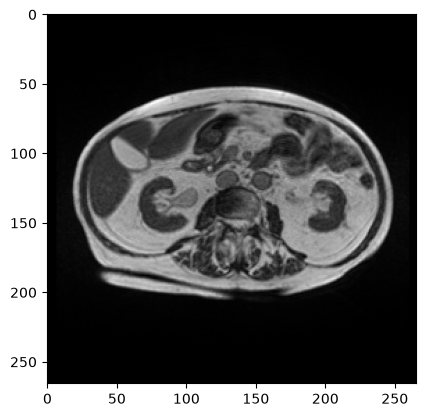

In [105]:
img = cv2.imread(row['image_path'].iloc[0], -1)
plt.imshow(img, cmap='gray')

### **Decode Mask**

In [106]:
import numpy as np

def rle_decode(mask_rle, shape):
    '''
    mask_rle: run-length as string formated (start length)
    shape: (height,width) of array to return 
    Returns numpy array, 1 - mask, 0 - background

    '''
    s = mask_rle.split()
    starts, lengths = [np.asarray(x, dtype=int) for x in (s[0:][::2], s[1:][::2])]
    starts -= 1
    ends = starts + lengths
    img = np.zeros(shape[0]*shape[1], dtype=np.uint8)
    for lo, hi in zip(starts, ends):
        img[lo:hi] = 1
    return img.reshape(shape)

def rle_encode(img):
    '''
    img: numpy array, 1 - mask, 0 - background
    Returns run length as string formated
    '''
    pixels = img.flatten()
    pixels = np.concatenate([[0], pixels, [0]])
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1
    runs[1::2] -= runs[::2]
    return ' '.join(str(x) for x in runs)

In [107]:
classes = ['stomach', 'small_bowel', 'large_bowel']

def get_mask(case, day, slice_id):
    h, w = 266, 266 # keep this fixed!!!
    sub_df = train_df[((train_df['case']) == int(case)) &
                      ((train_df['day']) == int(day)) &
                      ((train_df['slice']) == int(slice_id))]
    mask = np.zeros((h, w, len(classes)), dtype=np.uint8)
    for i, cls in enumerate(classes):
        rle = sub_df.loc[sub_df['class'] == cls, 'segmentation'].values
        if len(rle) and not pd.isna(rle[0]):
            mask[..., i] = rle_decode(rle[0], shape=(h, w))
    return mask

In [108]:
mask = get_mask(case, day, slice_id)
mask.shape

(266, 266, 3)

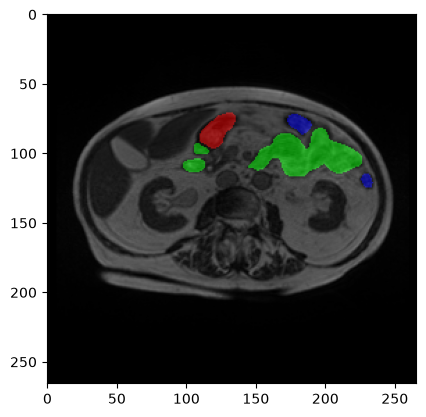

In [109]:
plt.imshow(img, cmap='gray')
plt.imshow(mask * 255, alpha=0.5)

# Data understanding

Every slice appears in `train.csv` three times, once per class, and the `segmentation` column is empty when that organ is not on the slice. So counting rows of `class` only counts slices times three. The real distribution is how many rows actually carry a mask.

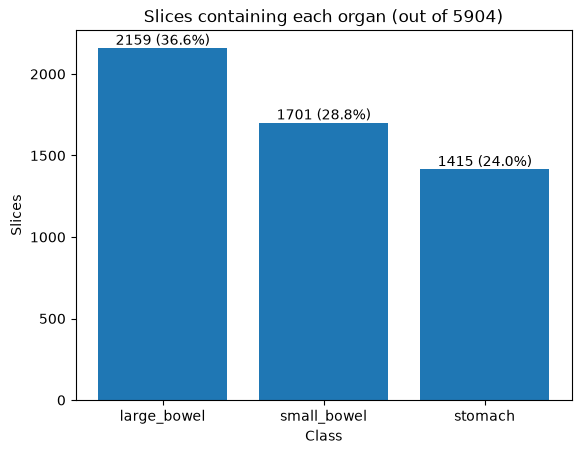

present
0    3316
1     388
2    1713
3     487
Name: count, dtype: int64


In [110]:
annotated = train_df[train_df['segmentation'].notna()]
n_slices = train_df.groupby(['case', 'day', 'slice']).ngroups

distribution = annotated['class'].value_counts()
pct = distribution / n_slices * 100

fig, ax = plt.subplots()
bars = ax.bar(distribution.index.astype(str), distribution.values)
ax.bar_label(bars, labels=[f'{v} ({p:.1f}%)' for v, p in zip(distribution.values, pct)])
ax.set_title(f'Slices containing each organ (out of {n_slices})')
ax.set_xlabel("Class")
ax.set_ylabel("Slices")
plt.show()

organs_per_slice = train_df.assign(present=train_df['segmentation'].notna()).groupby(['case', 'day', 'slice'])['present'].sum()
print(organs_per_slice.value_counts().sort_index())

The dataset is not balanced. Out of 5904 slices, large bowel appears on 2159 (36.6%), small bowel on 1701 (28.8%) and stomach on 1415 (24.0%).

It is even more skewed per slice: 3316 slices (56%) contain no organ at all, 1713 contain two and only 487 contain all three.

At pixel level the organs take 0.7%, 0.8% and 0.4% of the image, so the real imbalance the loss has to deal with is organ vs background, not organ vs organ.

Let's look at the difference between patients

In [111]:
rows = []
for case, group in train_df.groupby('case'):
    annotated = group[group['segmentation'].notna()]
    rows.append({
        'case': case,
        'days': group['day'].nunique(),
        'slices': group['image_path'].nunique(),
        'slices with an organ': annotated['image_path'].nunique(),
        'stomach': (annotated['class'] == 'stomach').sum(),
        'small_bowel': (annotated['class'] == 'small_bowel').sum(),
        'large_bowel': (annotated['class'] == 'large_bowel').sum(),
    })

per_patient = pd.DataFrame(rows).set_index('case')
per_patient['organ %'] = (per_patient['slices with an organ'] / per_patient['slices'] * 100).round(1)
per_patient

,days,slices,slices with an organ,stomach,small_bowel,large_bowel,organ %
case,,,,,,,
0,5,720,375,188,252,345,52.1
2,2,288,126,65,87,120,43.8
6,3,432,146,86,90,128,33.8
9,2,288,117,70,65,89,40.6
17,1,144,71,27,48,70,49.3
20,3,432,159,101,94,102,36.8
24,3,432,166,89,105,162,38.4
29,3,432,165,86,142,127,38.2
33,3,432,203,152,108,97,47.0


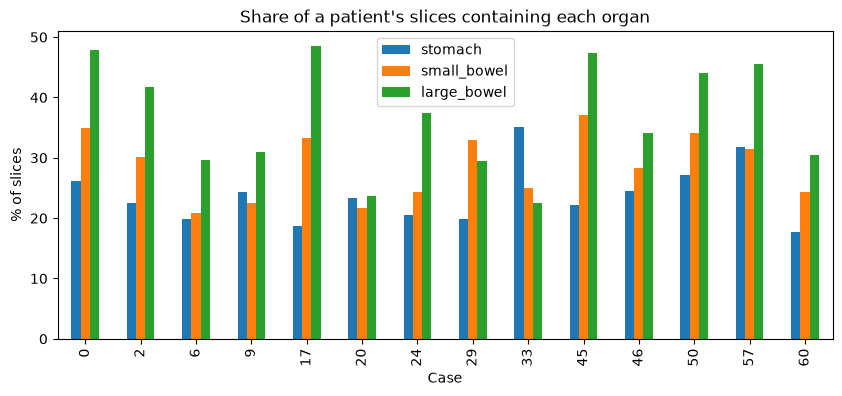

In [112]:
share = per_patient[classes].div(per_patient['slices'], axis=0) * 100

ax = share.plot.bar(figsize=(10, 4))
ax.set_title("Share of a patient's slices containing each organ")
ax.set_xlabel('Case')
ax.set_ylabel('% of slices')
plt.show()

One patient was scanned once (case 17, 144 slices), another five times (case 0, 720 slices), so a single patient is anywhere between 2.4% and 12.2% of the data.

How much of a patient is even annotated varies as well: 34% of case 6's slices contain an organ against 53% of case 45's.

The organ mix is patient-specific too. Case 33 is the only patient where stomach is the most frequent organ instead of large bowel.

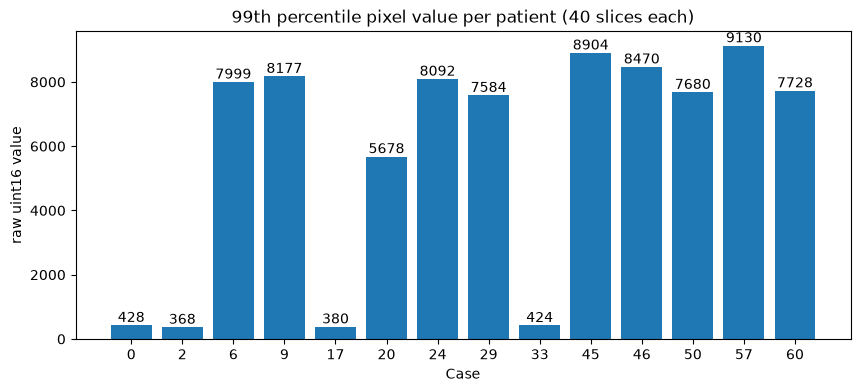

In [113]:
p99_per_patient = {}
for case, group in train_df.drop_duplicates('image_path').groupby('case'):
    sample = group.sample(min(40, len(group)), random_state=0)
    pixels = np.concatenate([cv2.imread(path, cv2.IMREAD_UNCHANGED).ravel() for path in sample['image_path']])
    p99_per_patient[case] = np.percentile(pixels, 99)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar([str(case) for case in p99_per_patient], list(p99_per_patient.values()))
ax.bar_label(bars, fmt='%.0f')
ax.set_title('99th percentile pixel value per patient (40 slices each)')
ax.set_xlabel('Case')
ax.set_ylabel('raw uint16 value')
plt.show()

This is the biggest difference between patients. The images are raw uint16 with no fixed unit, and four patients (0, 2, 17, 33) sit around 400 while the other ten sit around 8000 - a factor of 20.

That matters because if we use highest p99 over a sample of the whole training set when transforming and apply it to everybody, p99 comes out at 7728, so a case 0 slice that should fill 0-255 comes out with mean 1.6 and max 14.8, while a case 6 slice uses the full range. Four of the fourteen patients are handed to the model as almost black images.

## Dataset split for train and val sets

To avoid data leakage we need to make sure that the split will be done by cases aka persons. This way model will be validated against scans that it defenetely has never seen and that are not similar to what it has trained on.

In [114]:
from sklearn.model_selection import GroupKFold

group_5_fold = GroupKFold(n_splits=5)
train_idx, val_idx = next(group_5_fold.split(train_df, y=train_df['class'], groups=train_df['case']))

new_train_df, val_df = train_df.iloc[train_idx], train_df.iloc[val_idx]

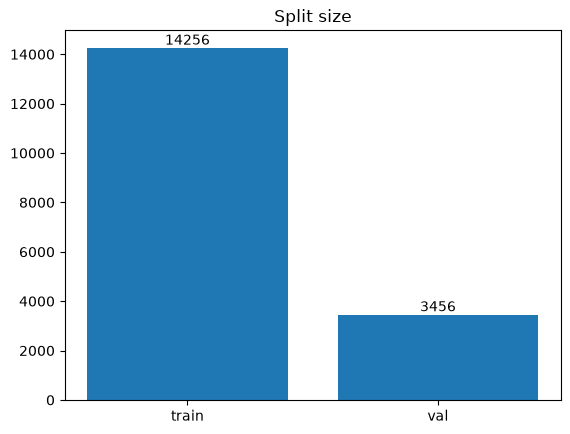

In [115]:
sizes = {'train': len(new_train_df), 'val': len(val_df)}

fig, ax = plt.subplots()
bars = ax.bar(sizes.keys(), sizes.values())
ax.bar_label(bars, labels=sizes.values())
ax.set_title("Split size")
plt.show()


In [116]:
train_cases = set(new_train_df['case'])
val_cases = set(val_df['case'])

print("Train & val:", train_cases & val_cases)

Train & val: set()


Nice, there is no leakage between splits. Now check that both splits still contain each organ in a similar proportion - again counting only the rows that carry a mask.

In [117]:
for fold, (train_idx, val_idx) in enumerate(group_5_fold.split(train_df, groups=train_df['case'])):
    val_cases = sorted(set(train_df.iloc[val_idx]['case']))
    print(f'fold {fold}: {14 - len(val_cases)} train patients, '
          f'val patients {val_cases} ({len(val_idx) // 3} slices)')

fold 0: 12 train patients, val patients [0, 6] (1152 slices)
fold 1: 11 train patients, val patients [2, 24, 60] (1296 slices)
fold 2: 11 train patients, val patients [17, 20, 45] (1152 slices)
fold 3: 11 train patients, val patients [33, 50, 57] (1152 slices)
fold 4: 11 train patients, val patients [9, 29, 46] (1152 slices)


14 patients over 5 folds means every fold validates on 2 or 3 of them, so a val score is an average over very few people and the folds are not the same size.

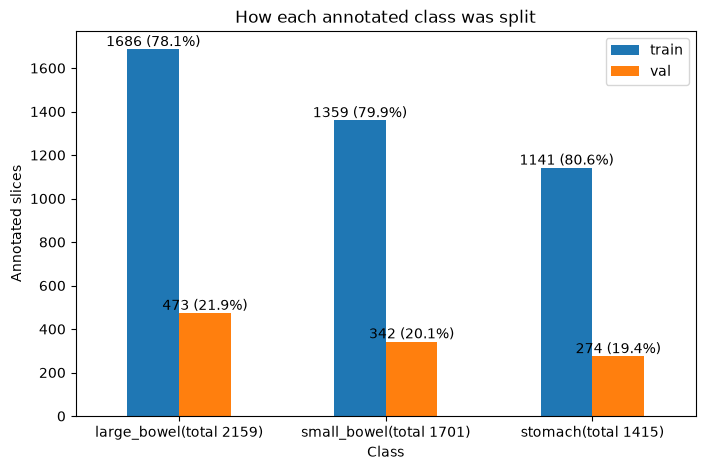

In [118]:
train_df_distribution = new_train_df[new_train_df['segmentation'].notna()]['class'].value_counts()
val_df_distribution = val_df[val_df['segmentation'].notna()]['class'].value_counts()

classes_distribution = pd.concat([train_df_distribution, val_df_distribution], axis=1, keys=['train', 'val'])
totals = classes_distribution.sum(axis=1)
pct = classes_distribution.div(totals, axis=0) * 100

ax = classes_distribution.plot.bar(figsize=(8, 5))
for cont, col in zip(ax.containers, classes_distribution.columns):
    ax.bar_label(cont, labels=[f'{v} ({p:.1f}%)' for v, p in zip(classes_distribution[col], pct[col])])

ax.set_xticklabels([f'{c}(total {t})' for c, t in totals.items()], rotation=0)
ax.set_title('How each annotated class was split')
ax.set_xlabel('Class')
ax.set_ylabel('Annotated slices')
plt.show()

# Model discoveries

## Setup

In [119]:
import torch
import segmentation_models_pytorch as smp
from segmentation_models_pytorch.losses import DiceLoss
from torch.utils.data import DataLoader, Subset

import train_25d
import train_2d

train_2d.set_seed(42)
device = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.device('cpu')
print("Current device:", device)

ENCODER = 'resnet34'
LOCAL_BATCH_SIZE = 16

preprocess_input, scale_intensity, pad = train_2d.build_transforms(new_train_df, ENCODER, sample_size=500, seed=42)
train_dataset = train_2d.SegDataset(new_train_df, preprocess_input, scale_intensity, pad)
val_dataset = train_2d.SegDataset(val_df, preprocess_input, scale_intensity, pad)
print(len(train_dataset), len(val_dataset), "slices (train / val)")

# a small random part of the training set, so a local prototype takes seconds
random_indices = torch.randperm(len(train_dataset))[:256].tolist()
small_train_loader = DataLoader(Subset(train_dataset, random_indices), batch_size=LOCAL_BATCH_SIZE, shuffle=True)

Current device: cuda


Intensity range from train sample: p1=0.0, p99=7889.0
4752 1152 slices (train / val)


In [120]:
images, masks = next(iter(small_train_loader))

print("Image:", tuple(images.shape), images.dtype, f"range [{images.min():.2f}, {images.max():.2f}]")
print("Mask: ", tuple(masks.shape), masks.dtype, "values", sorted(masks.unique().tolist()))

Image: (16, 3, 288, 288) torch.float32 range [-2.12, 2.64]
Mask:  (16, 3, 288, 288) torch.float32 values [0.0, 1.0]


## Run analysis

In [ ]:
import json
from pathlib import Path

from IPython.display import Image, display
from monai.metrics import DiceMetric

RUN_RESULTS = {}

def evaluate(model, dataloader, device) -> dict:
    model.eval()
    dice_metric = DiceMetric(include_background=True, reduction='mean')
    n_classes = len(train_2d.CLASSES)
    tp_per_class = torch.zeros(n_classes, device=device)
    fp_per_class = torch.zeros(n_classes, device=device)
    fn_per_class = torch.zeros(n_classes, device=device)
    fp_on_empty_per_class = torch.zeros(n_classes, device=device)
    fp_on_class = torch.zeros(n_classes, n_classes, device=device)
    fp_on_background = torch.zeros(n_classes, device=device)

    with torch.no_grad():
        for images_batch, gt_masks in dataloader:
            images_batch, gt_masks = images_batch.to(device), gt_masks.to(device)

            preds_bin = (torch.sigmoid(model(images_batch)) > 0.5).float()
            dice_metric(y_pred=preds_bin, y=gt_masks)

            tp_mask = preds_bin * gt_masks
            fp_mask = preds_bin * (1 - gt_masks)
            background = (gt_masks.sum(dim=1) == 0).float()   # (batch, H, W): pixel has no organ at all
            for a in range(n_classes):
                for b in range(n_classes):
                    fp_on_class[a, b] += (fp_mask[:, a] * gt_masks[:, b]).sum()
                fp_on_background[a] += (fp_mask[:, a] * background).sum()

            fn_mask = gt_masks * (1 - preds_bin)
            tp_per_class += tp_mask.sum(dim=(0, 2, 3))
            fp_per_class += fp_mask.sum(dim=(0, 2, 3))
            fn_per_class += fn_mask.sum(dim=(0, 2, 3))

            gt_empty = gt_masks.sum(dim=(2, 3)) == 0                 # (batch, classes)
            fp_on_empty_per_class += (fp_mask.sum(dim=(2, 3)) * gt_empty).sum(dim=0)

    per_class = []
    for i, name in enumerate(train_2d.CLASSES):
        tp, fp, fn = tp_per_class[i].item(), fp_per_class[i].item(), fn_per_class[i].item()
        per_class.append({
            'class': name,
            'dice_pooled': 2 * tp / (2 * tp + fp + fn),
            'miss_rate': fn / (tp + fn),                              # share of organ missed
            'fn_fp_ratio': fn / fp,                                   # >1 misses, <1 false alarms
            'fp_on_empty_share': fp_on_empty_per_class[i].item() / fp,
            'tp': tp, 'fp': fp, 'fn': fn,
        })

    fp_where = pd.DataFrame(fp_on_class.cpu().numpy(), index=train_2d.CLASSES, columns=train_2d.CLASSES)
    fp_where['background'] = fp_on_background.cpu().numpy()
    fp_where = fp_where.div(fp_per_class.cpu().numpy(), axis=0)   # rows: predicted class, values: share of its FP

    return {'dice': dice_metric.aggregate().item(), 'per_class': per_class, 'fp_where': fp_where}


def analyse_run(folder, architecture, data, checkpoint='checkpoint_best.pt', model=None):
    run_dir = Path('results') / folder
    config = json.loads((run_dir / 'config.json').read_text())
    fold = int(config.get('fold', 0))   # runs from before cross-validation all used fold 0
    print(f"{folder}: {architecture}, fold {fold}, {config['epochs']} epochs, batch {config['batch_size']}, lr {config['lr']}")

    # rebuild the validation set exactly as the run had it
    run_train_df, run_val_df = data.build_splits(Path(config['data_dir']), int(config['n_splits']), fold)
    val_cases = sorted(int(c) for c in run_val_df['case'].unique())
    if 'val_cases' in config:   # recorded by the training script: the patients the run really was validated on
        assert config['val_cases'] == val_cases, 'the split rebuilt here differs from the one the run used'
    run_preprocess, run_scale, run_pad = data.build_transforms(
        run_train_df, config['encoder_name'], int(config['intensity_sample_size']), int(config['seed'])
    )
    val_loader = DataLoader(data.SegDataset(run_val_df, run_preprocess, run_scale, run_pad), batch_size=LOCAL_BATCH_SIZE)

    metrics = pd.read_csv(run_dir / 'metrics.csv')
    best = metrics.loc[metrics['val_dice'].idxmax()]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(metrics['epoch'], metrics['train_loss'], label='train')
    ax1.plot(metrics['epoch'], metrics['val_loss'], label='val')
    ax1.set_title('Loss')
    ax1.legend()
    ax2.plot(metrics['epoch'], metrics['val_dice'])
    ax2.axvline(best['epoch'], linestyle='--', color='gray')
    ax2.set_title(f"Val Dice (per-slice mean), best {best['val_dice']:.4f} at epoch {int(best['epoch'])}")
    for ax in (ax1, ax2):
        ax.set_xlabel('epoch')
    fig.suptitle(folder)
    plt.show()

    if model is None:
        model = smp.create_model(architecture, encoder_name=config['encoder_name'], encoder_weights=None, classes=3)
    model = model.to(device)
    saved = torch.load(run_dir / checkpoint, map_location=device)
    model.load_state_dict(saved['model_state'])
    result = evaluate(model, val_loader, device)
    print(f"{checkpoint} (epoch {saved['epoch']}): val_dice per-slice mean = {result['dice']:.4f}, validated on cases {val_cases}")

    per_class = pd.DataFrame(result['per_class']).set_index('class')
    per_class['annotated_slices'] = train_df.groupby('class')['segmentation'].count()   # whole dataset
    display(per_class.round(3))
    display(result['fp_where'].round(3))

    for sample_path in sorted((run_dir / 'samples').glob('*.png')):
        display(Image(filename=str(sample_path)))

    RUN_RESULTS[folder] = {
        'label': folder, 'architecture': architecture, 'metrics': metrics, 'fold': fold, 'val_cases': val_cases,
        'best_epoch': int(best['epoch']), 'val_dice': result['dice'], 'per_class': per_class,
    }

## Models

Here i tried multiple baseline models using UnetPlusPlus and Segormer architectures. Both of them have used the same pretrained encoder Resnet34 to speed up training process.

### SegFormer 2d

- Input: 2D
- Loss: Dice

The single slice is repeated to 3 channels for the ImageNet ResNet-34 encoder because it was trained using RGB images.

In [122]:
# model = smp.create_model('segformer', encoder_name=ENCODER, encoder_weights='imagenet', classes=3).to(device)
# dice_loss = DiceLoss(mode='multilabel')
# bce_loss = torch.nn.BCEWithLogitsLoss()
# optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

# for epoch in range(4):
#     model.train()
#     train_loss = 0.0
#     for images_batch, gt_masks in small_train_loader:
#         images_batch, gt_masks = images_batch.to(device), gt_masks.to(device)

#         optimizer.zero_grad()
#         predicted_mask = model(images_batch)
#         loss = dice_loss(predicted_mask, gt_masks) + bce_loss(predicted_mask, gt_masks)
#         loss.backward()
#         optimizer.step()

#         train_loss += loss.item()

#     print(f"epoch {epoch}: train loss {train_loss / len(small_train_loader):.3f}")

1671556-same-as-previous-better-samples: segformer, fold 0, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7889.0


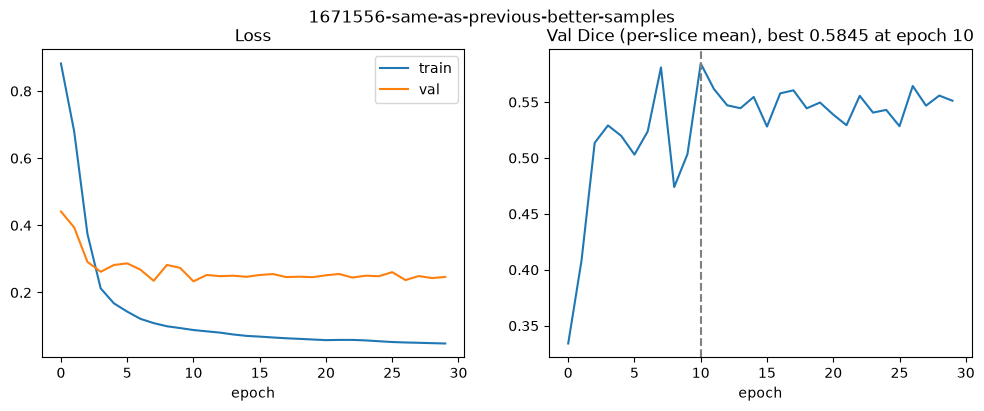

checkpoint_best.pt (epoch 10): val_dice per-slice mean = 0.5845, validated on cases [0, 6]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.697,0.393,2.924,0.323,208564.0,46199.0,135063.0,1415
small_bowel,0.534,0.521,1.663,0.348,289977.0,189947.0,315788.0,1701
large_bowel,0.672,0.264,0.578,0.112,371457.0,230075.0,133053.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.373,0.049,0.578
small_bowel,0.023,0.000,0.104,0.873
large_bowel,0.010,0.407,0.000,0.584


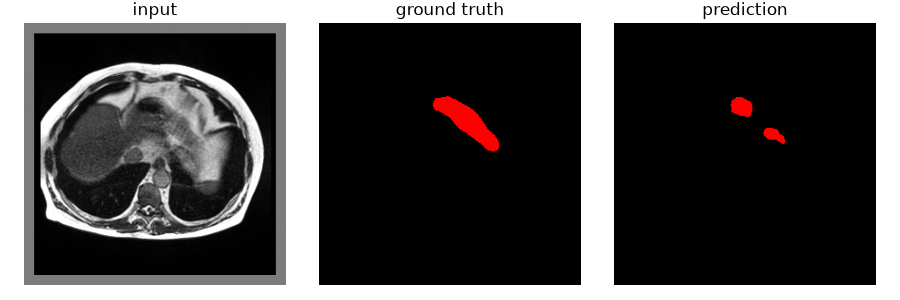

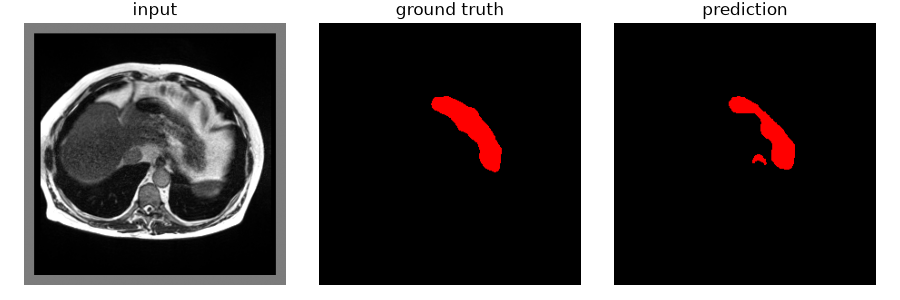

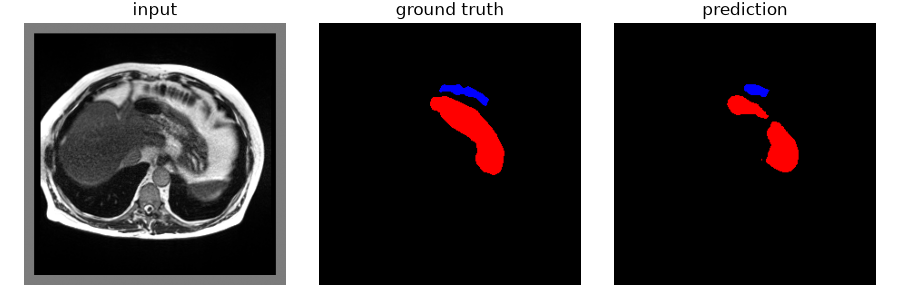

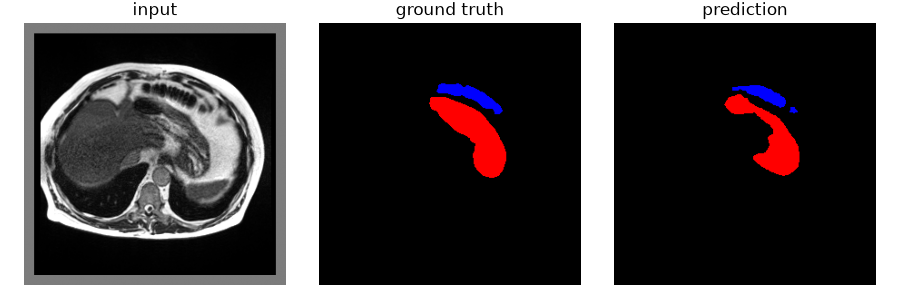

In [123]:
analyse_run('1671556-same-as-previous-better-samples', 'segformer', data=train_2d)

## Results

Looking at loss model overfits. We can see that after 10 epochs val_loss remains about the same and Dice score also get no improvement. However, train_loss keeps getting smaller so model at least can extract features, but not really well to generalize.

Also if we look at dice score per class, the small bowel gets the smallest and 52% of gt mask pixels got missed. 

At the same time we can see that model heavily under-predicting stomach and over-predicting large bowel.

### U-Net++ 2d

- Input: 2D
- Loss: Dice + BCE

Same input and encoder as before, but with a U-Net++ decoder.

In [124]:
# model = smp.create_model('unetplusplus', encoder_name=ENCODER, encoder_weights='imagenet', classes=3).to(device)
# dice_loss = DiceLoss(mode='multilabel')
# bce_loss = torch.nn.BCEWithLogitsLoss()
# optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

# for epoch in range(4):
#     model.train()
#     train_loss = 0.0
#     for images_batch, gt_masks in small_train_loader:
#         images_batch, gt_masks = images_batch.to(device), gt_masks.to(device)

#         optimizer.zero_grad()
#         predicted_mask = model(images_batch)
#         loss = dice_loss(predicted_mask, gt_masks) + bce_loss(predicted_mask, gt_masks)
#         loss.backward()
#         optimizer.step()

#         train_loss += loss.item()

#     print(f"epoch {epoch}: train loss {train_loss / len(small_train_loader):.3f}")

1783292: unetplusplus, fold 0, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7889.0


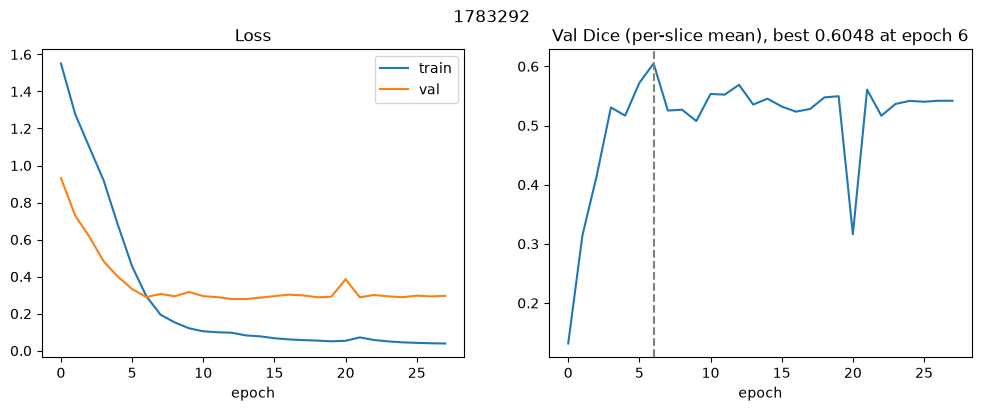

checkpoint_best.pt (epoch 6): val_dice per-slice mean = 0.6048, validated on cases [0, 6]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.682,0.416,3.209,0.395,200806.0,44513.0,142821.0,1415
small_bowel,0.532,0.406,0.636,0.459,359866.0,386335.0,245899.0,1701
large_bowel,0.678,0.247,0.527,0.155,379736.0,236601.0,124774.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.372,0.084,0.544
small_bowel,0.075,0.000,0.088,0.838
large_bowel,0.007,0.360,0.000,0.633


In [125]:
analyse_run('1783292', 'unetplusplus', data=train_2d)

## Results

Val Dice is 0.605 against 0.585 for SegFormer on the same fold, so the sharper decoder gives a small gain. The overfitting did not go away: the best epoch is 6 out of 30, and after that val_loss stays around 0.29 while train_loss keeps falling to 0.04.

Small bowel is again the weakest class (0.53) and again the one the other organs are confused with - 36% of large bowel false positives and 37% of stomach false positives land on real small bowel pixels.

## Cross-validation

The runs above were validated on fold 0 only, which is 2 patients out of 14, so a single unlucky or lucky patient moves the score a lot. From here every configuration is trained 5 times, once per fold, so every patient is validated on exactly once.

### U-Net++ 2d, 5 folds

- Input: 2D
- Loss: Dice + BCE

The same configuration as above, now trained once per fold.

1786020-UnetPlusPlus/fold0: unetplusplus, fold 0, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7889.0


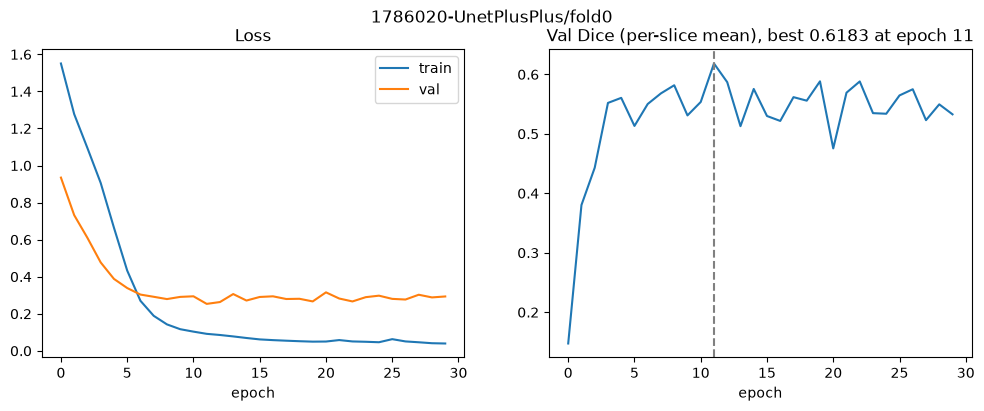

checkpoint_best.pt (epoch 11): val_dice per-slice mean = 0.6184, validated on cases [0, 6]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.667,0.446,4.169,0.465,190392.0,36760.0,153235.0,1415
small_bowel,0.594,0.377,0.793,0.423,377332.0,287980.0,228433.0,1701
large_bowel,0.642,0.418,1.809,0.201,293832.0,116462.0,210678.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.558,0.004,0.439
small_bowel,0.039,0.000,0.183,0.778
large_bowel,0.007,0.386,0.000,0.607


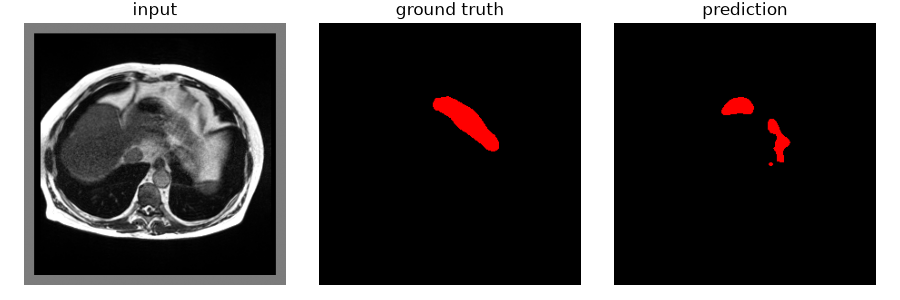

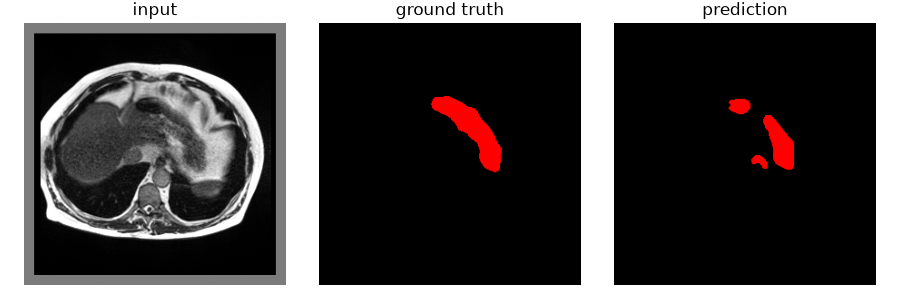

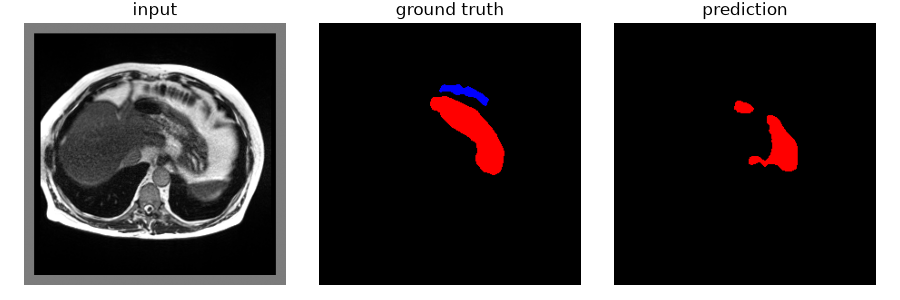

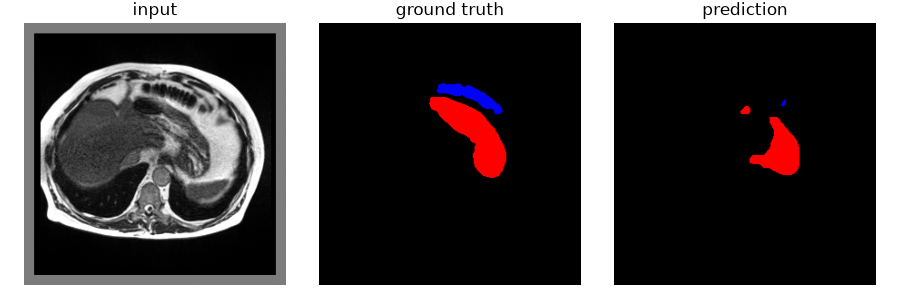

1786020-UnetPlusPlus/fold1: unetplusplus, fold 1, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7920.0


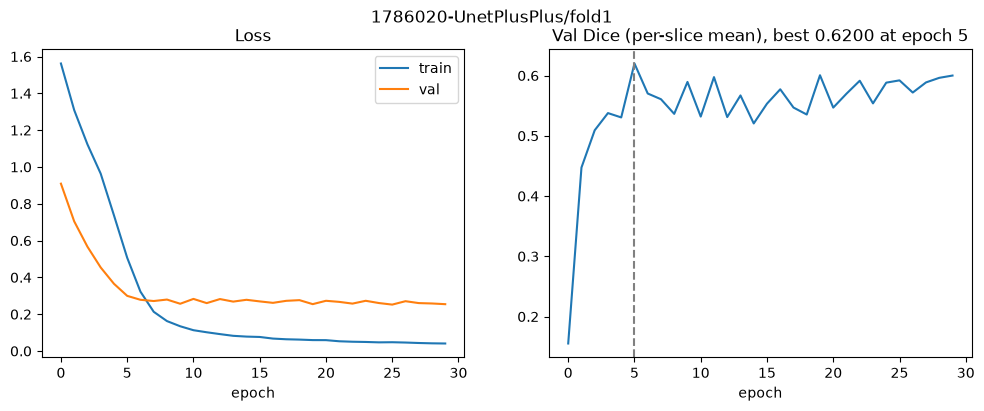

checkpoint_best.pt (epoch 5): val_dice per-slice mean = 0.6200, validated on cases [2, 24, 60]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.753,0.321,2.580,0.131,240109.0,43975.0,113468.0,1415
small_bowel,0.510,0.242,0.199,0.346,465963.0,746806.0,148930.0,1701
large_bowel,0.663,0.422,2.533,0.378,449209.0,129213.0,327344.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.038,0.073,0.889
small_bowel,0.054,0.000,0.193,0.753
large_bowel,0.015,0.235,0.000,0.750


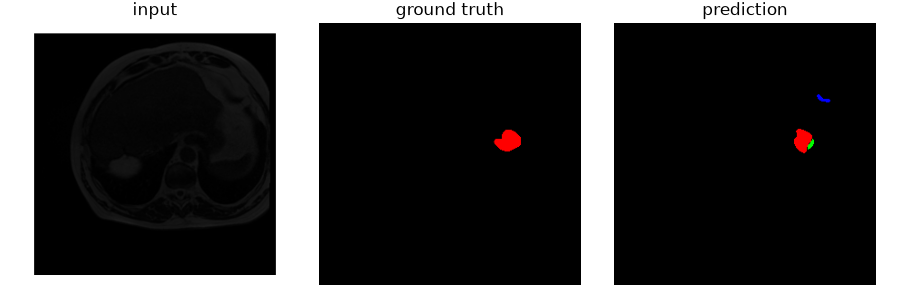

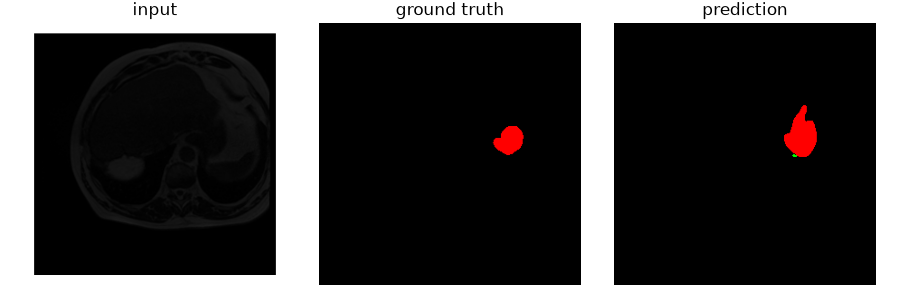

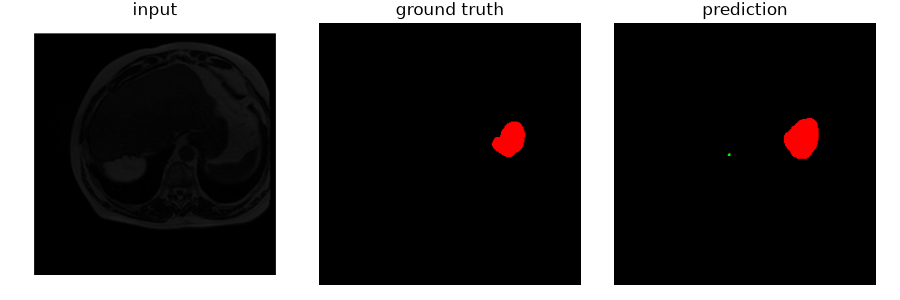

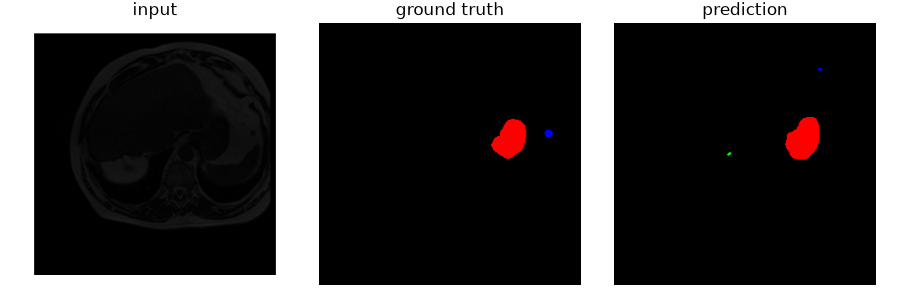

1786020-UnetPlusPlus/fold2: unetplusplus, fold 2, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7700.0


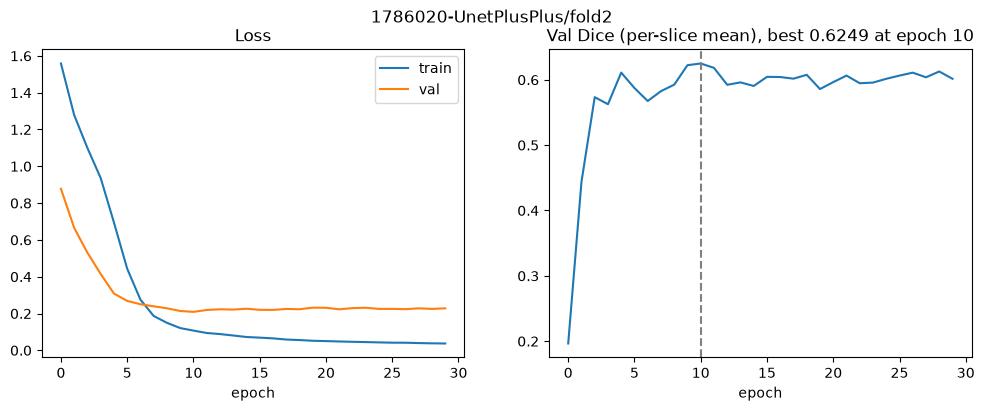

checkpoint_best.pt (epoch 10): val_dice per-slice mean = 0.6248, validated on cases [17, 20, 45]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.757,0.355,5.985,0.376,294842.0,27146.0,162466.0,1415
small_bowel,0.622,0.367,0.908,0.186,396797.0,253045.0,229801.0,1701
large_bowel,0.689,0.398,2.746,0.132,495609.0,119405.0,327907.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.050,0.330,0.620
small_bowel,0.029,0.000,0.379,0.592
large_bowel,0.002,0.389,0.000,0.610


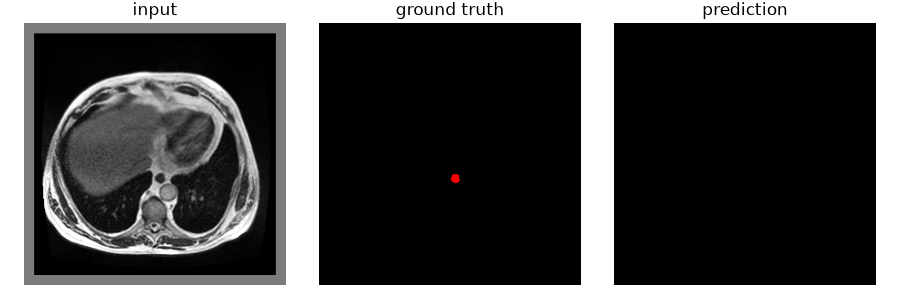

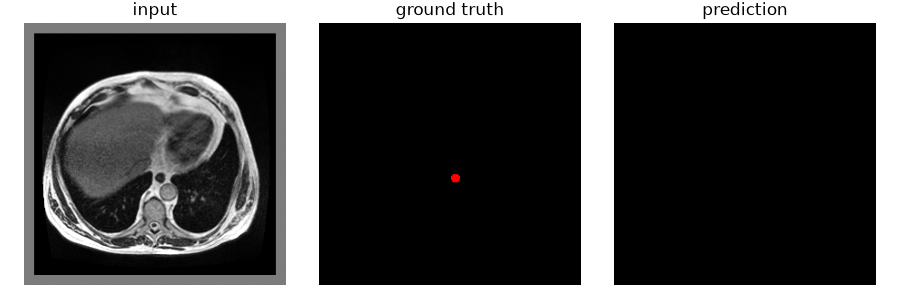

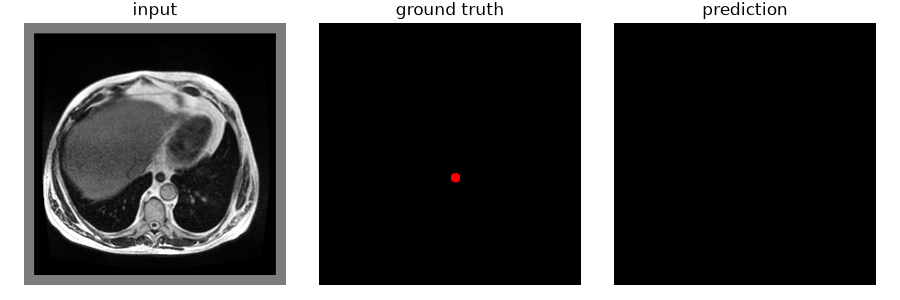

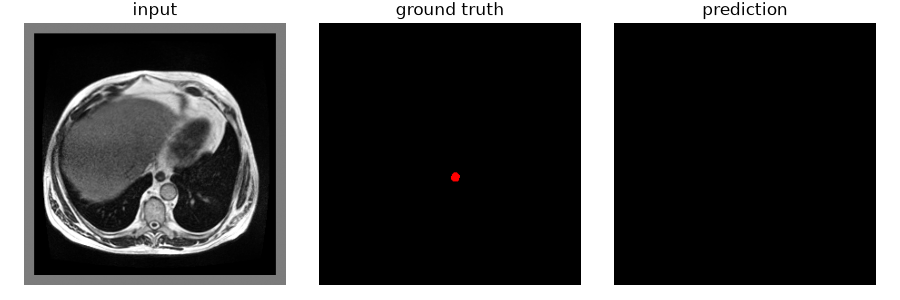

1786020-UnetPlusPlus/fold3: unetplusplus, fold 3, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7728.0


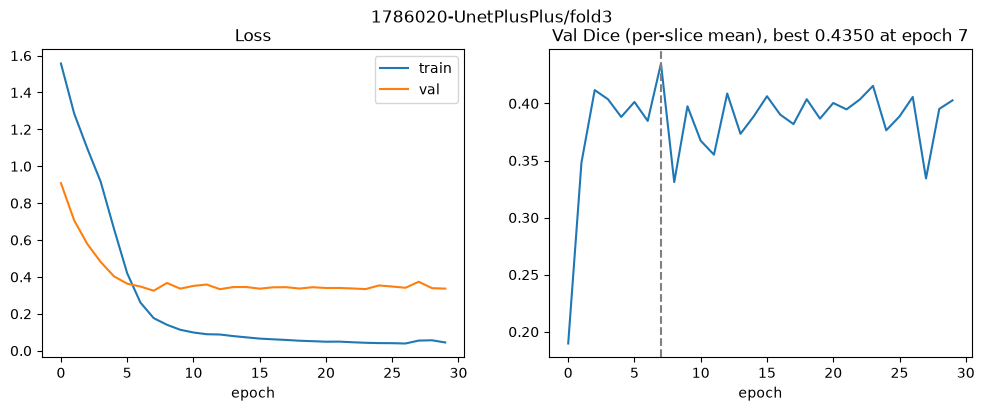

checkpoint_best.pt (epoch 7): val_dice per-slice mean = 0.4351, validated on cases [33, 50, 57]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.534,0.598,5.814,0.163,119440.0,30572.0,177754.0,1415
small_bowel,0.522,0.524,1.510,0.305,293598.0,214223.0,323463.0,1701
large_bowel,0.582,0.427,1.075,0.372,256071.0,177164.0,190529.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.029,0.097,0.874
small_bowel,0.319,0.000,0.193,0.488
large_bowel,0.144,0.295,0.000,0.561


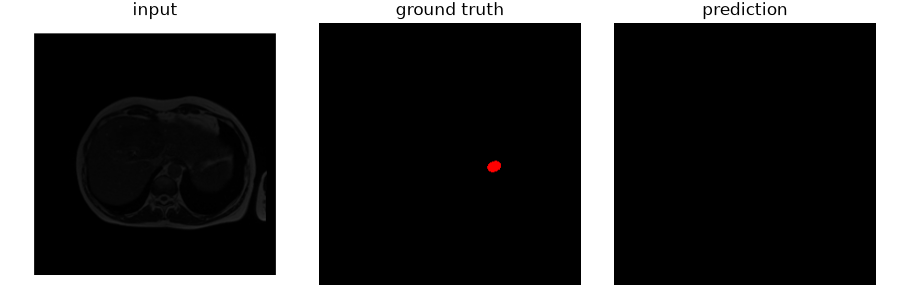

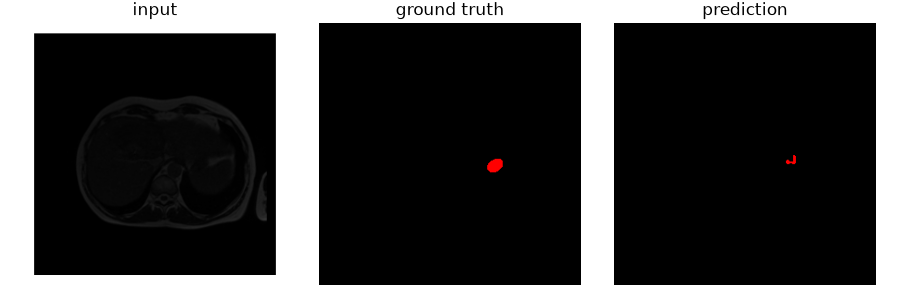

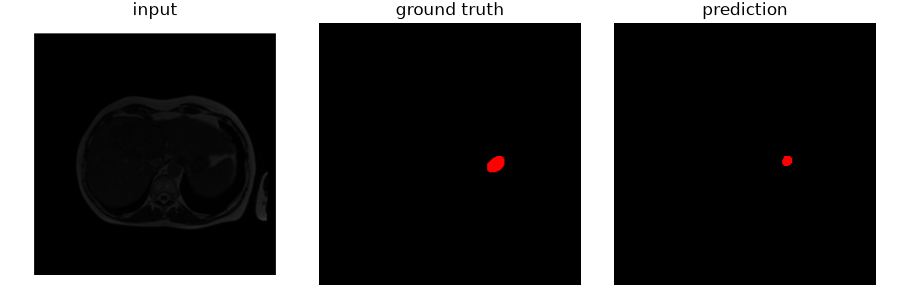

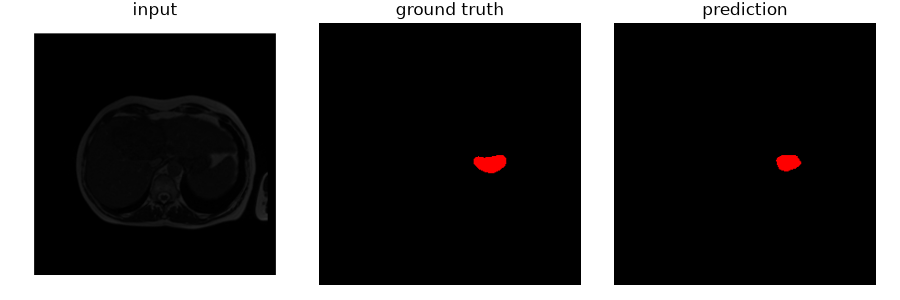

1786020-UnetPlusPlus/fold4: unetplusplus, fold 4, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7705.0


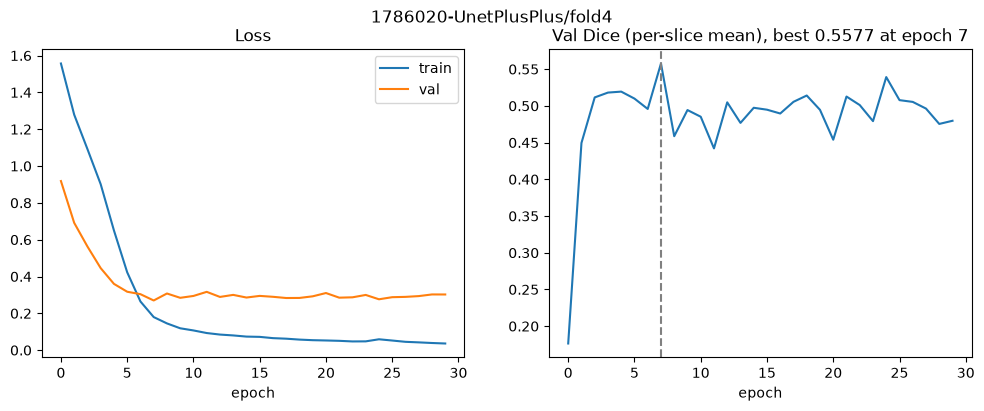

checkpoint_best.pt (epoch 7): val_dice per-slice mean = 0.5577, validated on cases [9, 29, 46]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.690,0.356,1.584,0.179,254684.0,88767.0,140591.0,1415
small_bowel,0.546,0.534,2.209,0.117,359022.0,186244.0,411320.0,1701
large_bowel,0.488,0.565,1.624,0.277,160545.0,128279.0,208262.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.438,0.046,0.516
small_bowel,0.036,0.000,0.370,0.594
large_bowel,0.001,0.535,0.000,0.464


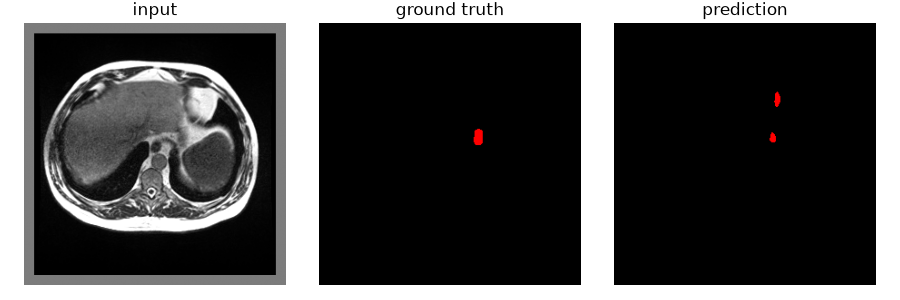

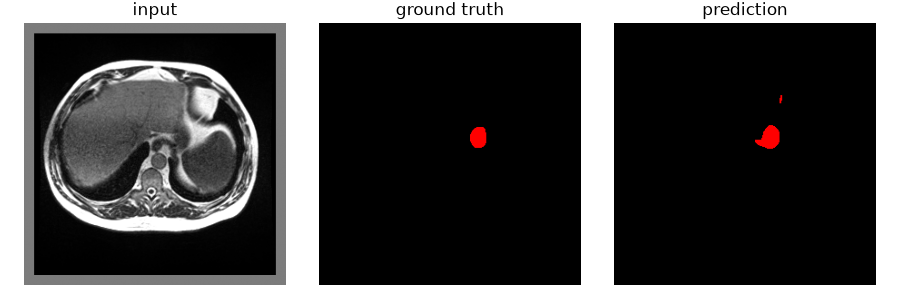

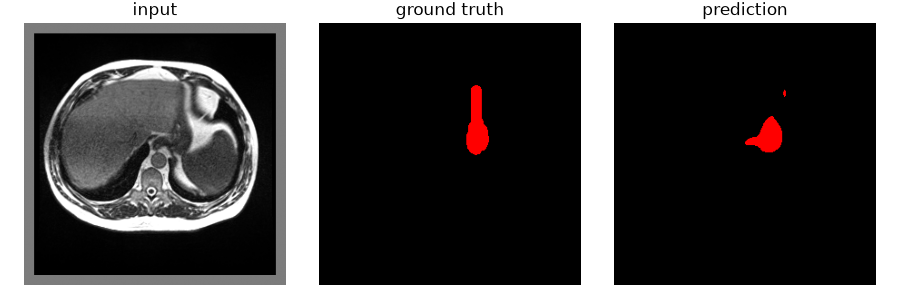

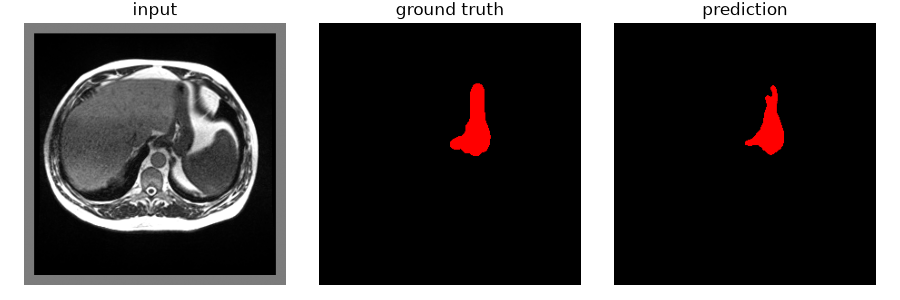

In [126]:
CV_JOB = '1786020-UnetPlusPlus'
CV_ARCHITECTURE = 'unetplusplus'

cv_folders = [f'{CV_JOB}/fold{k}' for k in range(5)]
for folder in cv_folders:
    analyse_run(folder, CV_ARCHITECTURE, data=train_2d)

In [127]:
cv = pd.DataFrame([
    {
        'fold': RUN_RESULTS[folder]['fold'], 'val cases': RUN_RESULTS[folder]['val_cases'],
        'val_dice': RUN_RESULTS[folder]['val_dice'],
        **{f'dice {cls}': dice for cls, dice in RUN_RESULTS[folder]['per_class']['dice_pooled'].items()},
    }
    for folder in cv_folders
]).set_index('fold')
display(cv.round(3))
display(cv.drop(columns='val cases').agg(['mean', 'std']).round(3))

,val cases,val_dice,dice stomach,dice small_bowel,dice large_bowel
fold,,,,,
0,"[0, 6]",0.618,0.667,0.594,0.642
1,"[2, 24, 60]",0.620,0.753,0.510,0.663
2,"[17, 20, 45]",0.625,0.757,0.622,0.689
3,"[33, 50, 57]",0.435,0.534,0.522,0.582
4,"[9, 29, 46]",0.558,0.690,0.546,0.488


,val_dice,dice stomach,dice small_bowel,dice large_bowel
mean,0.571,0.68,0.559,0.613
std,0.081,0.09,0.048,0.080


## Results

Mean val Dice is 0.571 with a spread of 0.081 across folds. The single-fold run above gave 0.605, so that number was about 0.03 too optimistic - fold 0 turns out to be one of the easier splits.

Fold 3 (cases 33, 50, 57) is clearly the hardest at 0.435, while folds 0-2 are all around 0.62. So it was good idea to make it.

Per class the order is the same as in the single-fold runs: stomach 0.680, large bowel 0.613, small bowel 0.559.

### SegFormer 2d, 5 folds

- Input: 2D
- Loss: Dice + BCE

SegFormer again, now with the same Dice + BCE loss as U-Net++ and on all 5 folds, so the two architectures can be compared directly.

1786236/fold0: segformer, fold 0, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7889.0


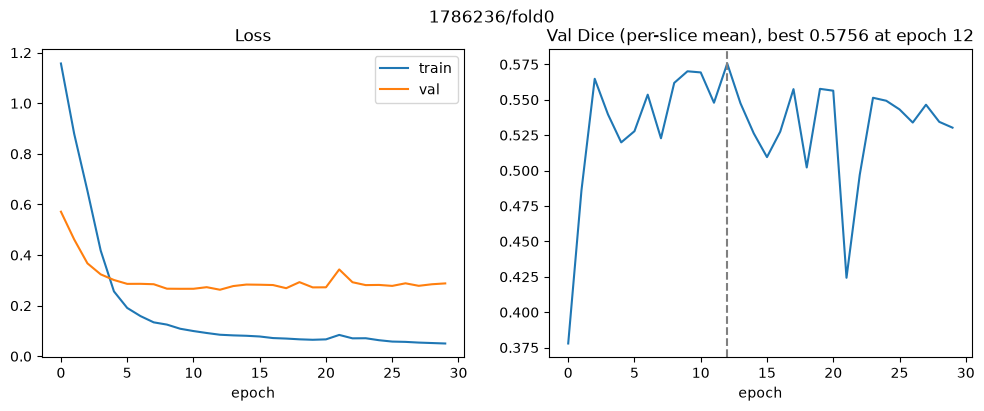

checkpoint_best.pt (epoch 12): val_dice per-slice mean = 0.5757, validated on cases [0, 6]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.680,0.441,5.187,0.311,192036.0,29223.0,151591.0,1415
small_bowel,0.544,0.512,1.680,0.327,295445.0,184707.0,310320.0,1701
large_bowel,0.666,0.266,0.566,0.113,370124.0,237608.0,134386.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.443,0.006,0.551
small_bowel,0.028,0.000,0.115,0.857
large_bowel,0.007,0.405,0.000,0.588


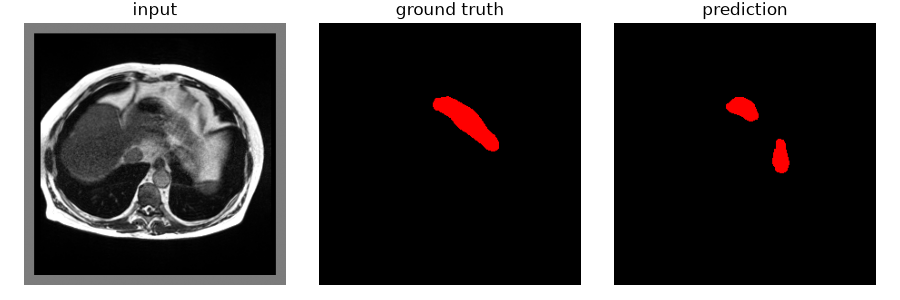

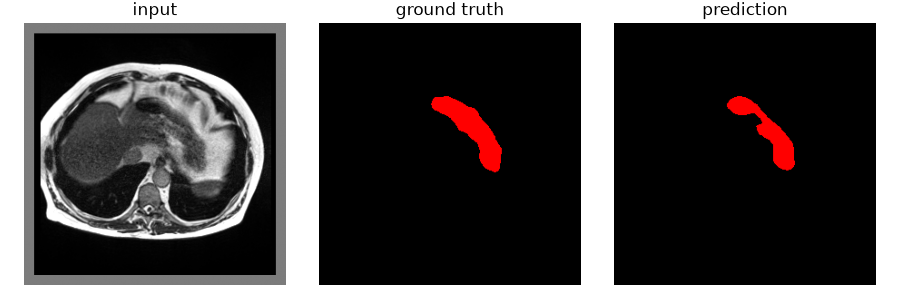

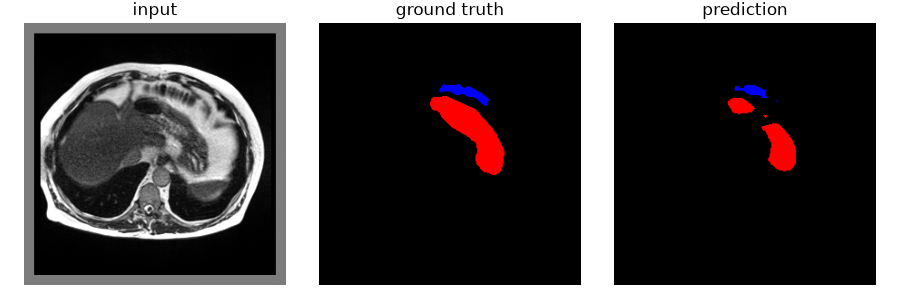

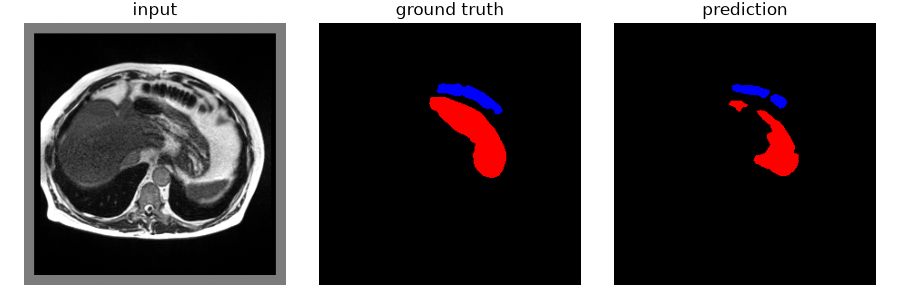

1786236/fold1: segformer, fold 1, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7920.0


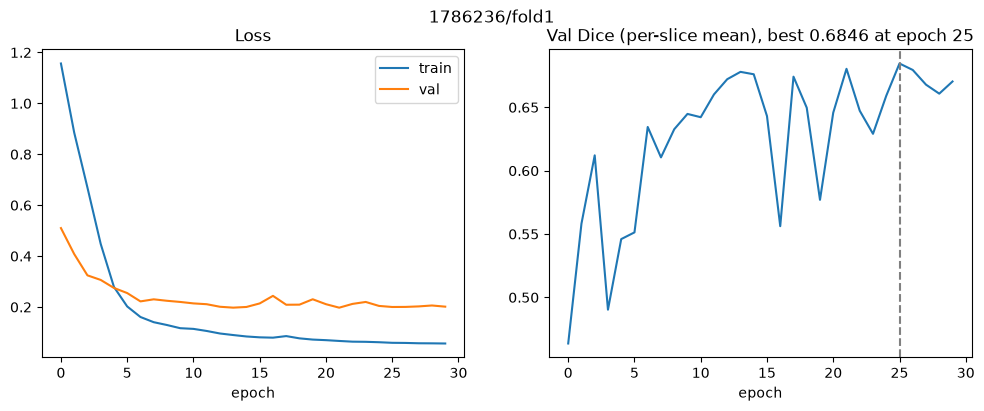

checkpoint_best.pt (epoch 25): val_dice per-slice mean = 0.6845, validated on cases [2, 24, 60]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.807,0.225,1.554,0.210,273899.0,51276.0,79678.0,1415
small_bowel,0.604,0.434,1.404,0.300,348319.0,189905.0,266574.0,1701
large_bowel,0.721,0.356,2.496,0.466,500032.0,110795.0,276521.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.140,0.146,0.714
small_bowel,0.059,0.000,0.301,0.640
large_bowel,0.004,0.263,0.000,0.733


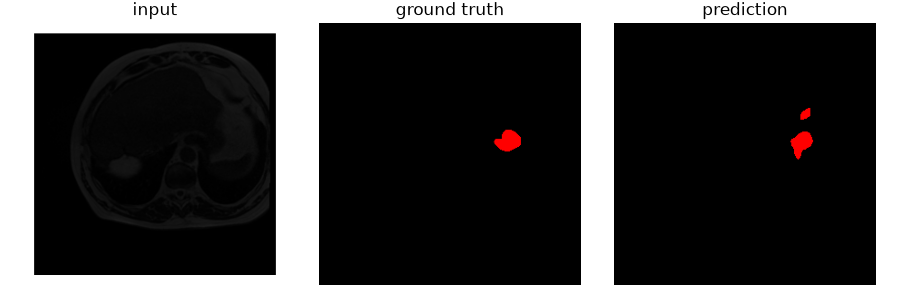

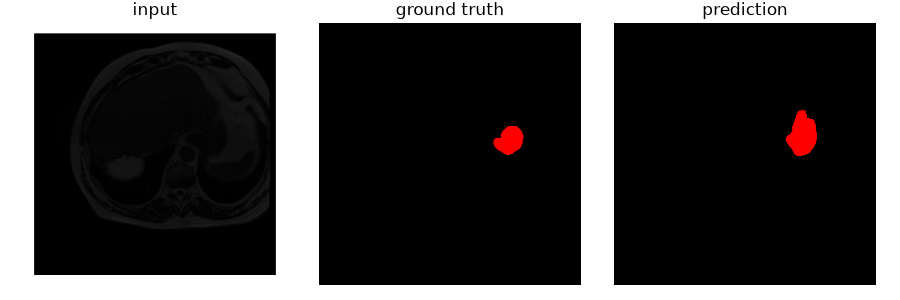

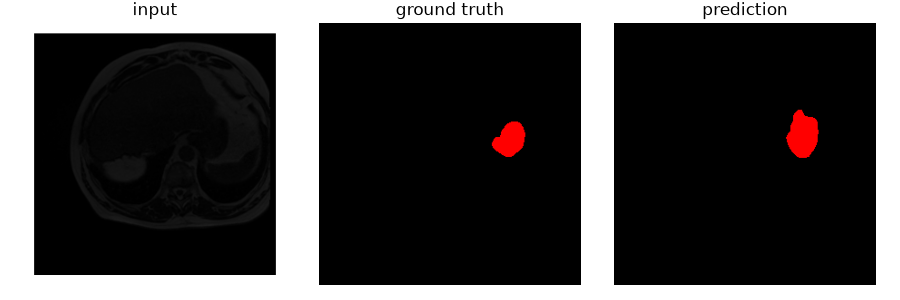

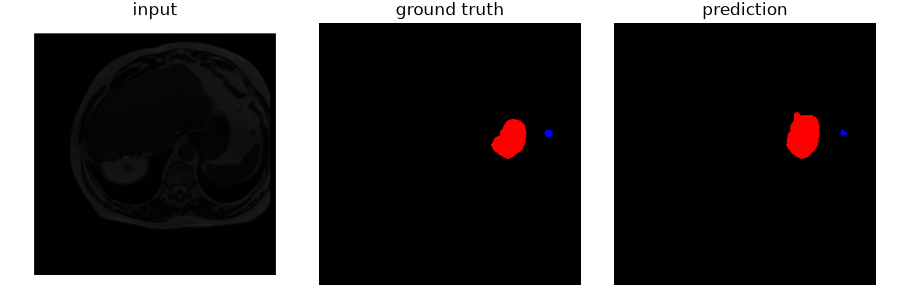

1786236/fold2: segformer, fold 2, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7700.0


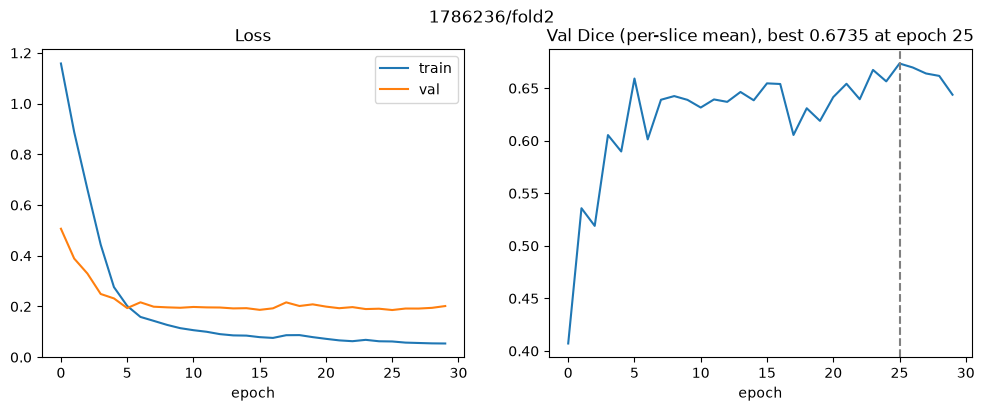

checkpoint_best.pt (epoch 25): val_dice per-slice mean = 0.6735, validated on cases [17, 20, 45]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.815,0.268,4.150,0.254,334923.0,29489.0,122385.0,1415
small_bowel,0.632,0.335,0.760,0.252,416665.0,276284.0,209933.0,1701
large_bowel,0.728,0.320,1.717,0.120,559608.0,153662.0,263908.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.055,0.153,0.792
small_bowel,0.030,0.000,0.391,0.579
large_bowel,0.008,0.362,0.000,0.631


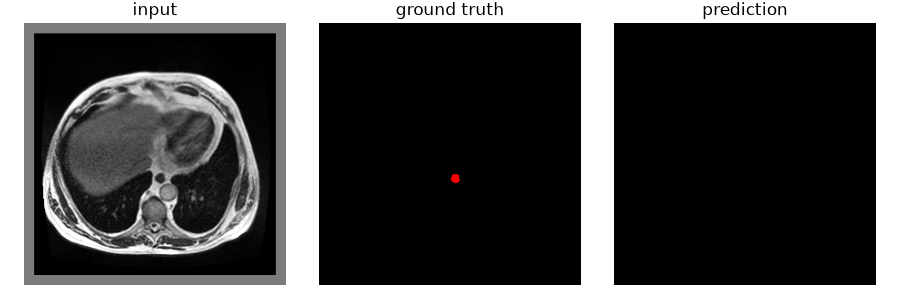

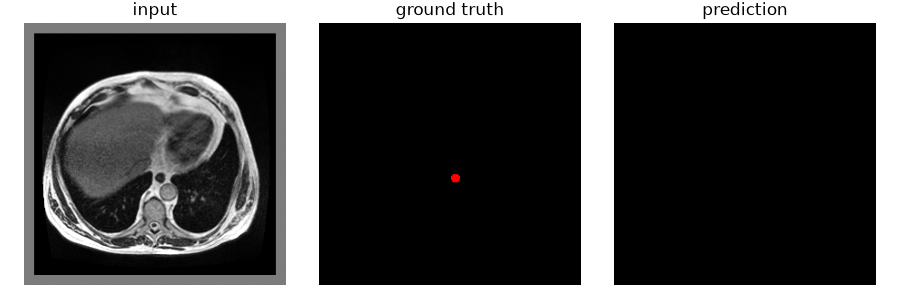

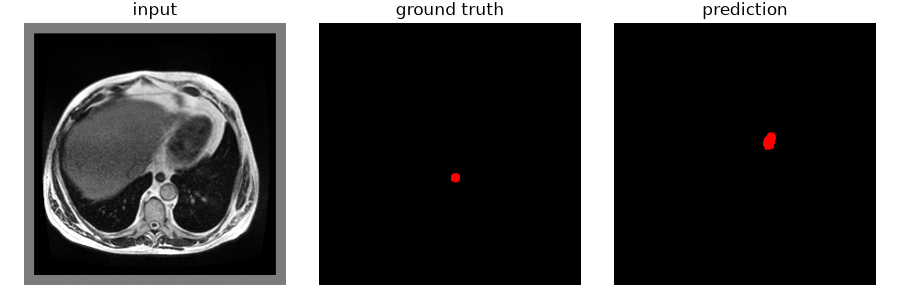

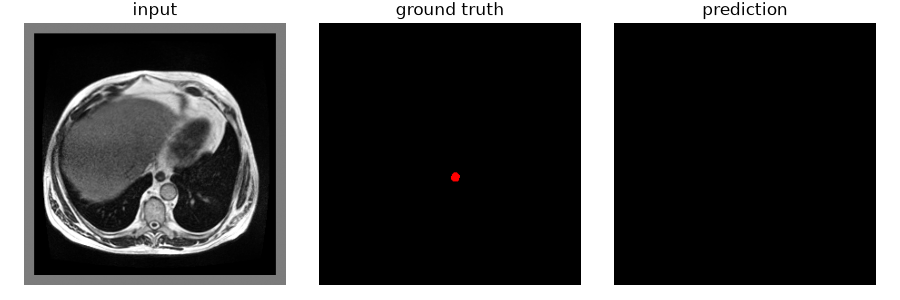

1786236/fold3: segformer, fold 3, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7728.0


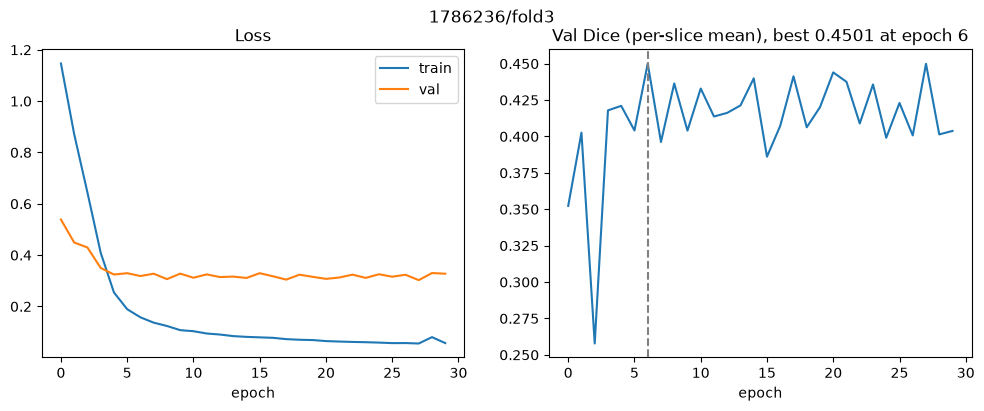

checkpoint_best.pt (epoch 6): val_dice per-slice mean = 0.4501, validated on cases [33, 50, 57]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.598,0.490,2.520,0.181,151570.0,57797.0,145624.0,1415
small_bowel,0.484,0.509,0.948,0.281,302690.0,331641.0,314371.0,1701
large_bowel,0.547,0.521,1.915,0.273,213725.0,121636.0,232875.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.071,0.108,0.821
small_bowel,0.248,0.000,0.234,0.519
large_bowel,0.097,0.328,0.000,0.575


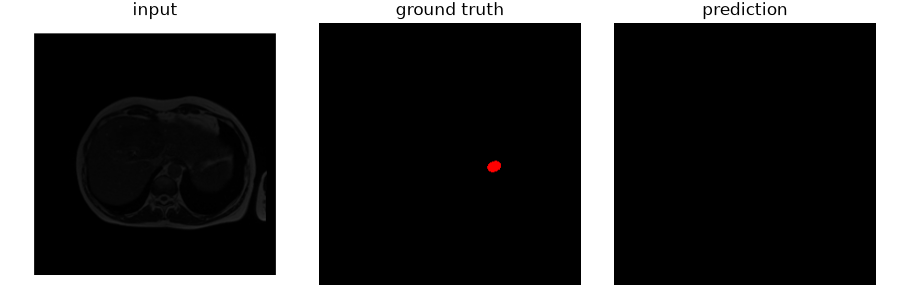

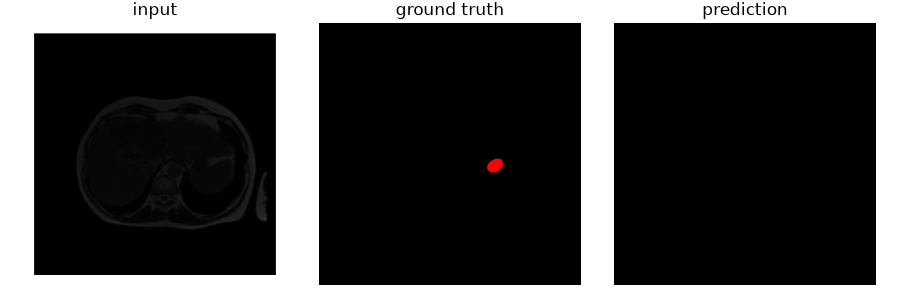

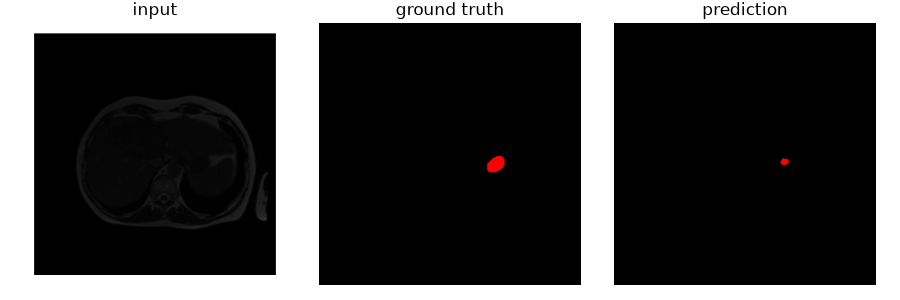

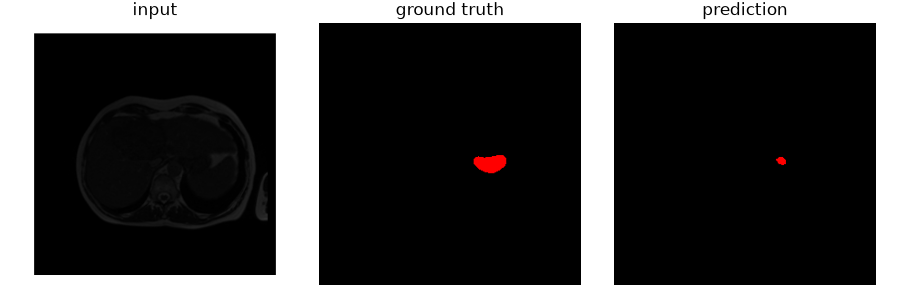

1786236/fold4: segformer, fold 4, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7705.0


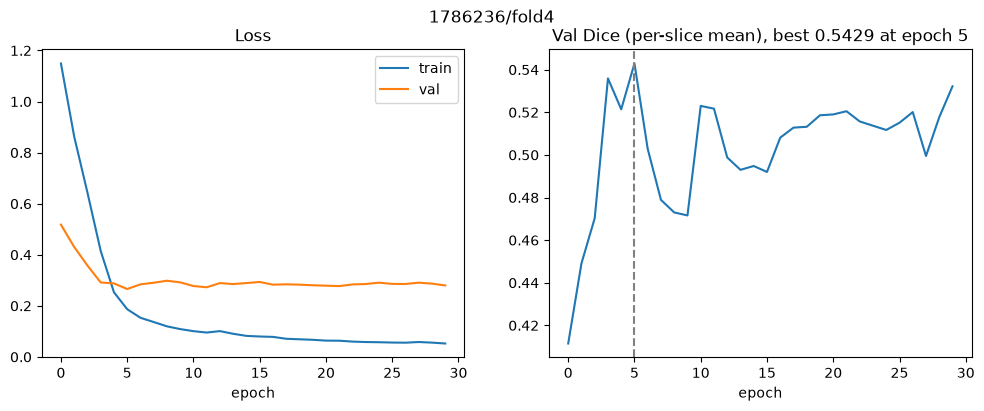

checkpoint_best.pt (epoch 5): val_dice per-slice mean = 0.5429, validated on cases [9, 29, 46]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.681,0.376,1.797,0.229,246797.0,82642.0,148478.0,1415
small_bowel,0.518,0.579,2.824,0.134,324519.0,157858.0,445823.0,1701
large_bowel,0.486,0.581,1.898,0.303,154623.0,112846.0,214184.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.388,0.066,0.546
small_bowel,0.021,0.000,0.321,0.657
large_bowel,0.000,0.549,0.000,0.450


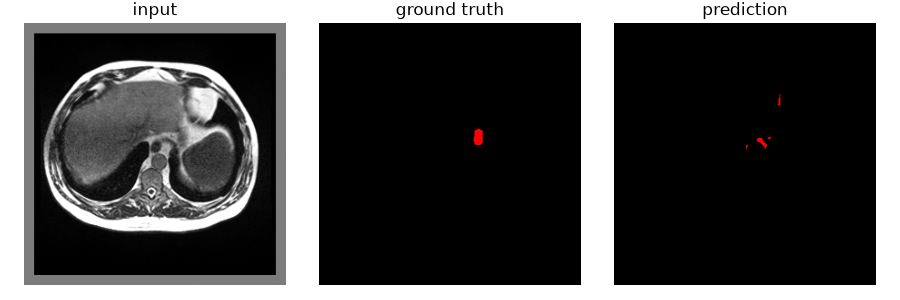

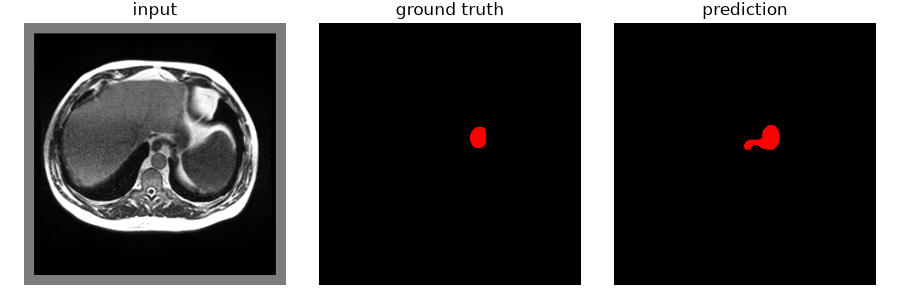

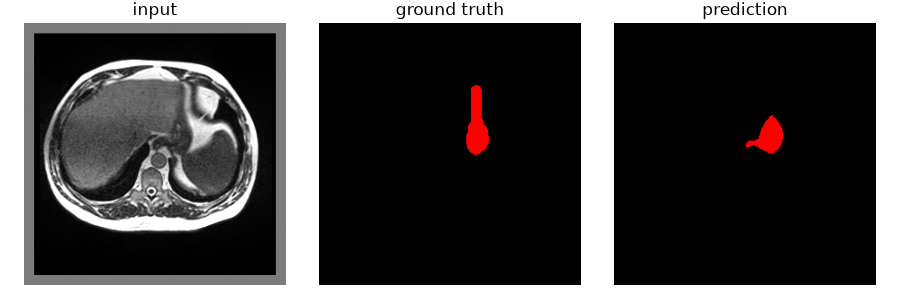

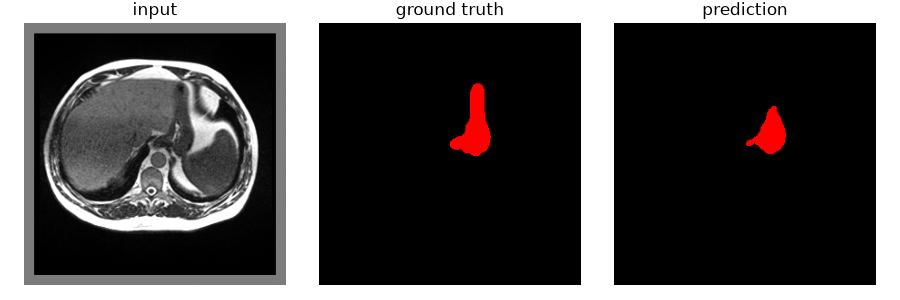

In [129]:
CV_JOB = '1786236'
CV_ARCHITECTURE = 'segformer'

cv_folders = [f'{CV_JOB}/fold{k}' for k in range(5)]
for folder in cv_folders:
    analyse_run(folder, CV_ARCHITECTURE, data=train_2d)

In [130]:
cv = pd.DataFrame([
    {
        'fold': RUN_RESULTS[folder]['fold'], 'val cases': RUN_RESULTS[folder]['val_cases'],
        'val_dice': RUN_RESULTS[folder]['val_dice'],
        **{f'dice {cls}': dice for cls, dice in RUN_RESULTS[folder]['per_class']['dice_pooled'].items()},
    }
    for folder in cv_folders
]).set_index('fold')
display(cv.round(3))
display(cv.drop(columns='val cases').agg(['mean', 'std']).round(3))

,val cases,val_dice,dice stomach,dice small_bowel,dice large_bowel
fold,,,,,
0,"[0, 6]",0.576,0.680,0.544,0.666
1,"[2, 24, 60]",0.685,0.807,0.604,0.721
2,"[17, 20, 45]",0.673,0.815,0.632,0.728
3,"[33, 50, 57]",0.450,0.598,0.484,0.547
4,"[9, 29, 46]",0.543,0.681,0.518,0.486


,val_dice,dice stomach,dice small_bowel,dice large_bowel
mean,0.585,0.716,0.556,0.629
std,0.097,0.093,0.061,0.108


## Results

Mean val Dice is 0.585 against 0.571 for U-Net++. On average SegFormer is ahead, but it wins only 3 of the 5 folds and loses folds 0 and 4.

Fold 3 is the worst here as well (0.450), which confirms those patients are hard for both architectures rather than one model failing on them.

Stomach is the best class (0.716) but also the most under-predicted - about 3 missed pixels for every false positive. Small bowel stays the weakest (0.556).

### SegFormer 2.5d, 5 folds

- Input: 2.5D
- Loss: Dice + BCE

Instead of repeating one slice 3 times, the channels are now the previous, the current and the next slice of the same scan. At the first and last slice of a scan the slice itself stands in for the missing neighbour.

1786512-segformer_train_25d/fold0: segformer, fold 0, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7889.0


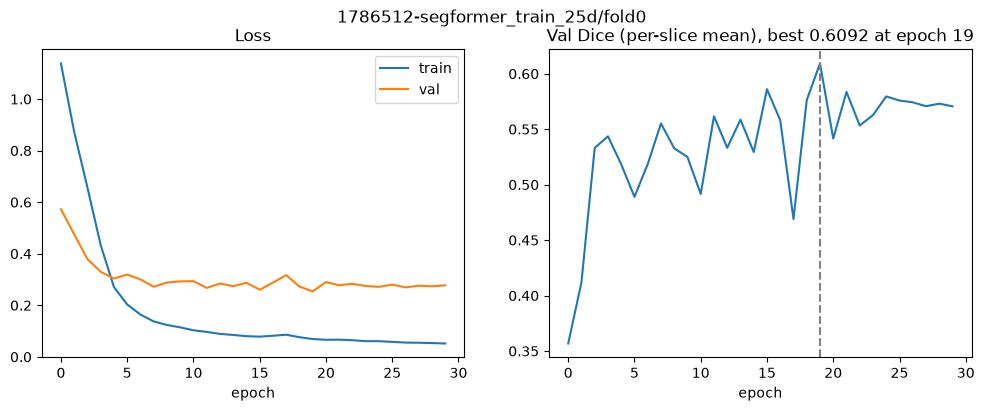

checkpoint_best.pt (epoch 19): val_dice per-slice mean = 0.6092, validated on cases [0, 6]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.690,0.438,6.728,0.374,192986.0,22389.0,150641.0,1415
small_bowel,0.576,0.450,1.259,0.441,332966.0,216598.0,272799.0,1701
large_bowel,0.669,0.262,0.558,0.150,372495.0,236510.0,132015.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.336,0.010,0.654
small_bowel,0.019,0.000,0.107,0.873
large_bowel,0.020,0.398,0.000,0.582


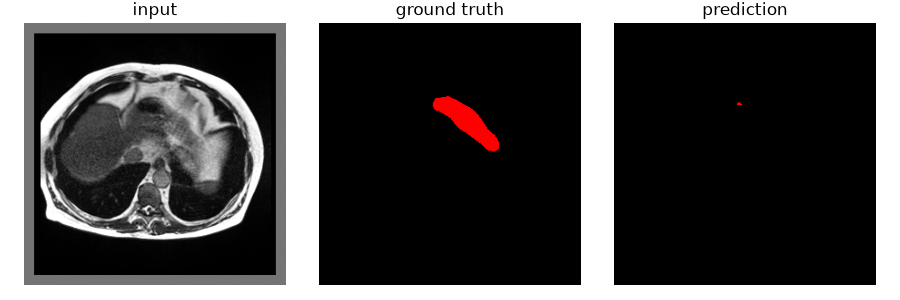

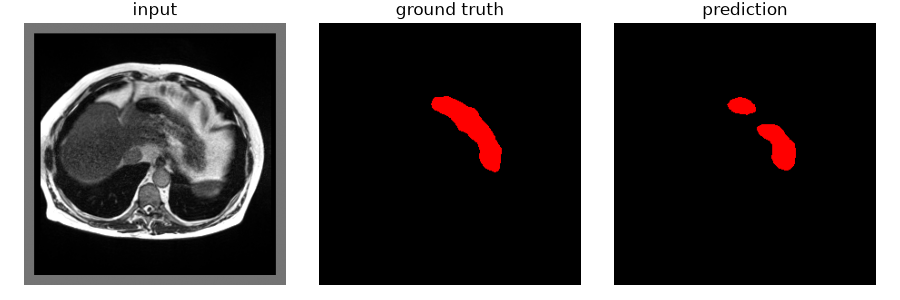

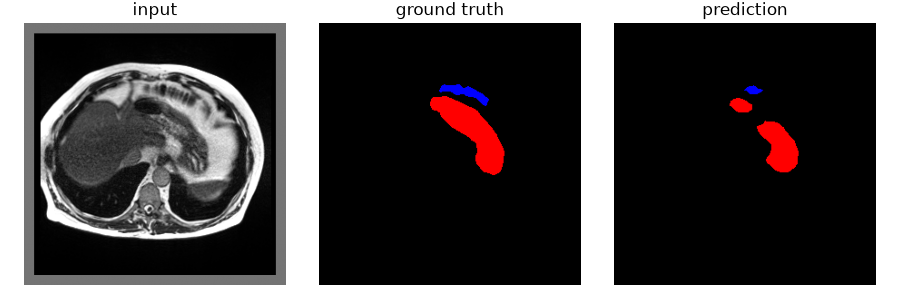

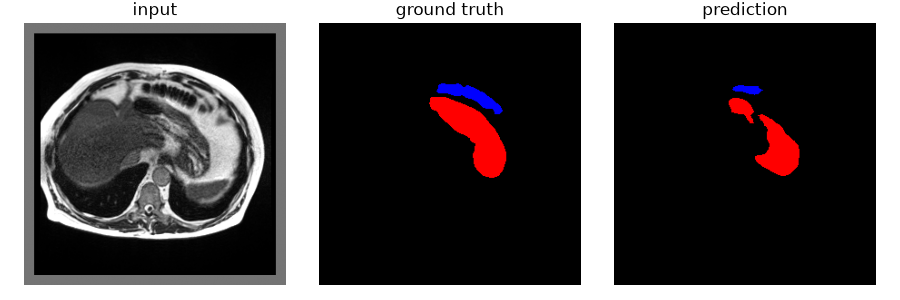

1786512-segformer_train_25d/fold1: segformer, fold 1, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7920.0


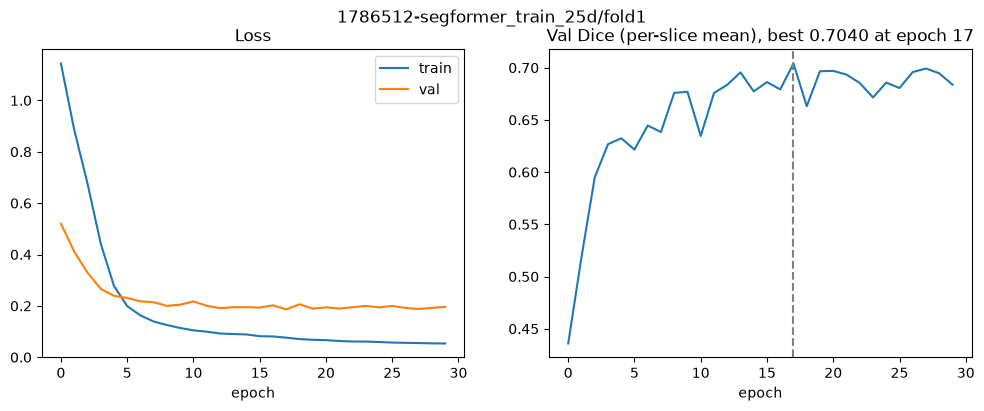

checkpoint_best.pt (epoch 17): val_dice per-slice mean = 0.7041, validated on cases [2, 24, 60]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.803,0.258,2.457,0.183,262210.0,37192.0,91367.0,1415
small_bowel,0.610,0.428,1.410,0.420,351442.0,186855.0,263451.0,1701
large_bowel,0.749,0.294,1.637,0.493,548351.0,139445.0,228202.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.06,0.13,0.810
small_bowel,0.029,0.00,0.22,0.751
large_bowel,0.031,0.22,0.00,0.749


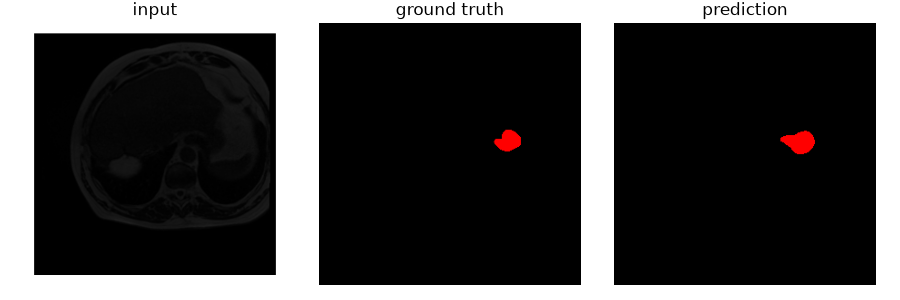

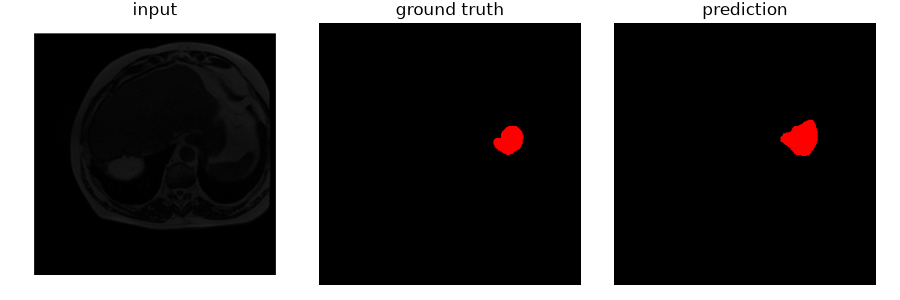

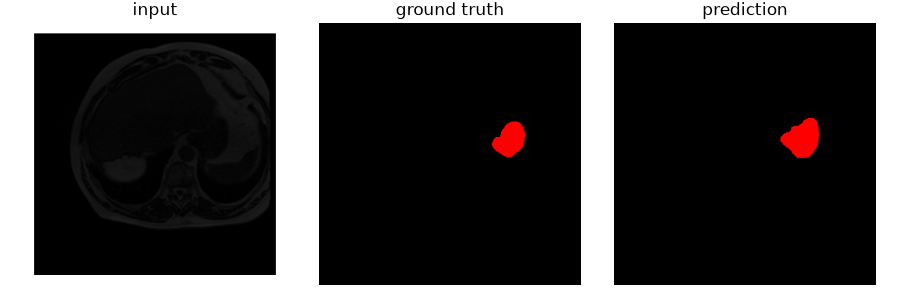

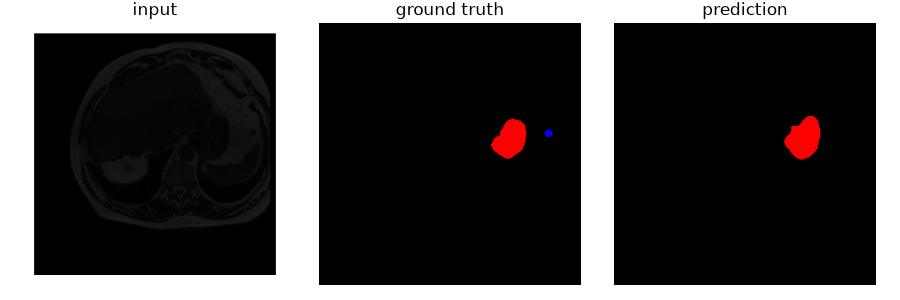

1786512-segformer_train_25d/fold2: segformer, fold 2, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7700.0


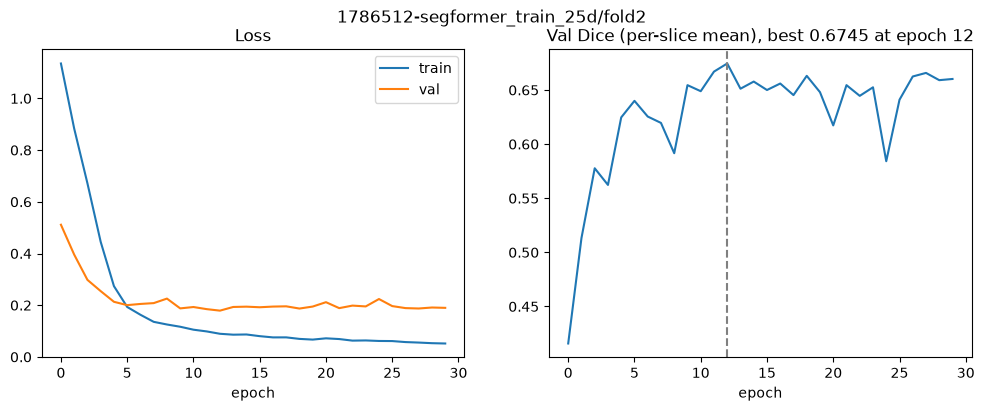

checkpoint_best.pt (epoch 12): val_dice per-slice mean = 0.6745, validated on cases [17, 20, 45]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.826,0.255,4.230,0.318,340831.0,27537.0,116477.0,1415
small_bowel,0.646,0.366,1.113,0.165,397543.0,205867.0,229055.0,1701
large_bowel,0.727,0.336,2.070,0.096,546562.0,133768.0,276954.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.042,0.231,0.728
small_bowel,0.015,0.000,0.431,0.553
large_bowel,0.009,0.398,0.000,0.593


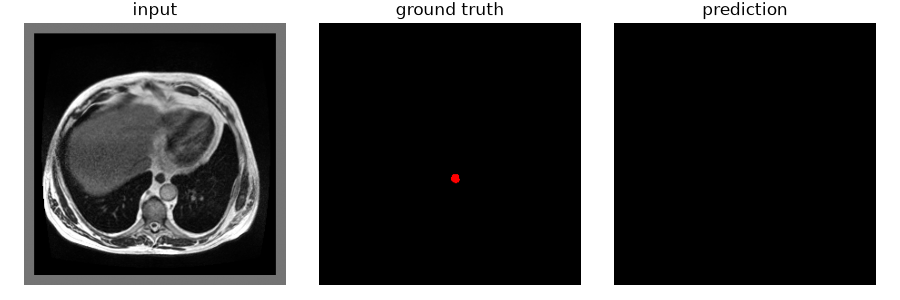

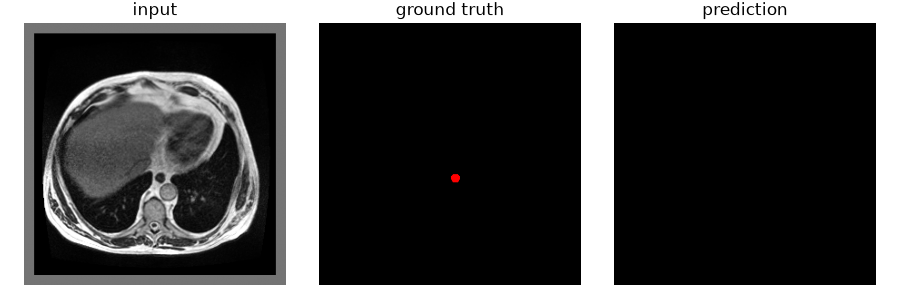

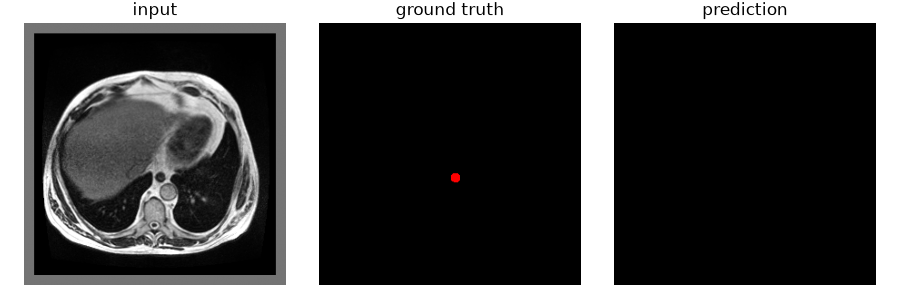

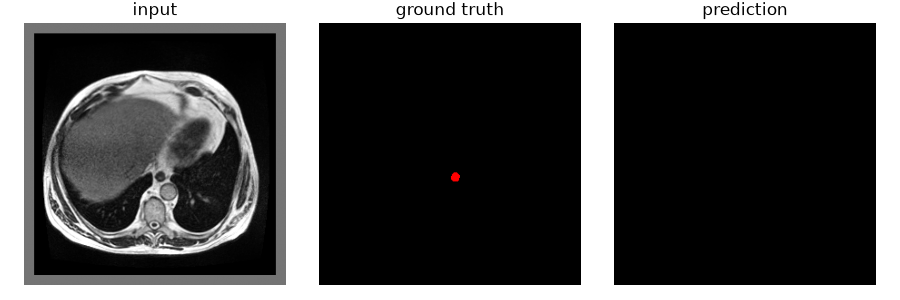

1786512-segformer_train_25d/fold3: segformer, fold 3, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7728.0


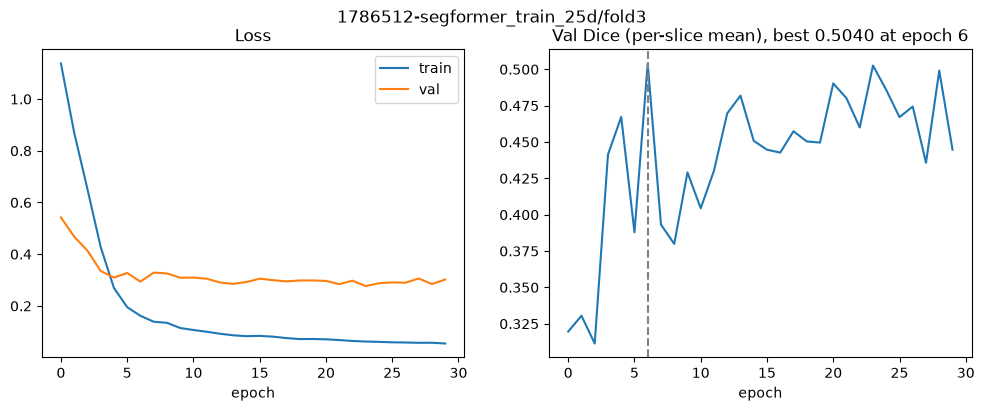

checkpoint_best.pt (epoch 6): val_dice per-slice mean = 0.5040, validated on cases [33, 50, 57]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.623,0.459,2.346,0.196,160832.0,58129.0,136362.0,1415
small_bowel,0.514,0.513,1.268,0.219,300261.0,249892.0,316800.0,1701
large_bowel,0.584,0.463,1.528,0.309,239991.0,135250.0,206609.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.077,0.104,0.819
small_bowel,0.208,0.000,0.287,0.505
large_bowel,0.075,0.298,0.000,0.628


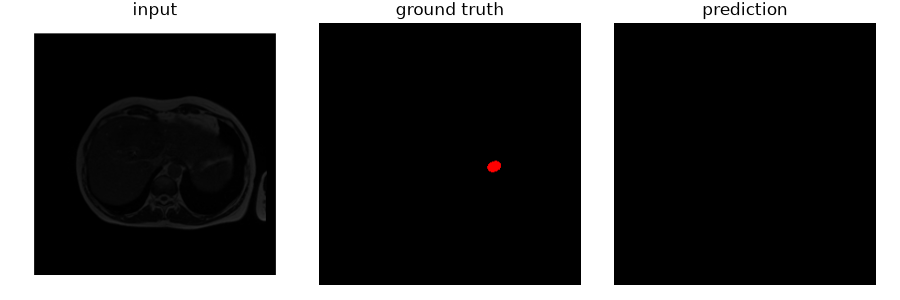

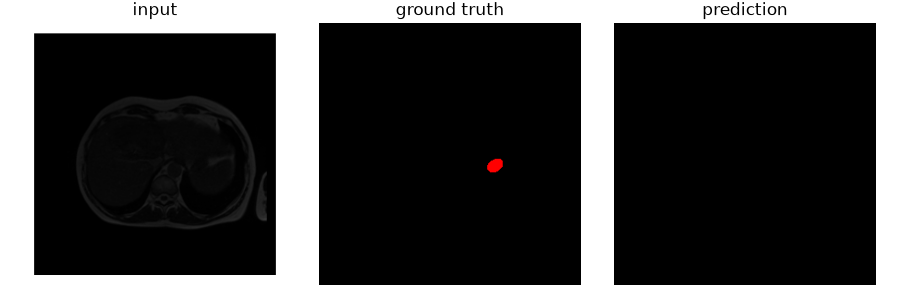

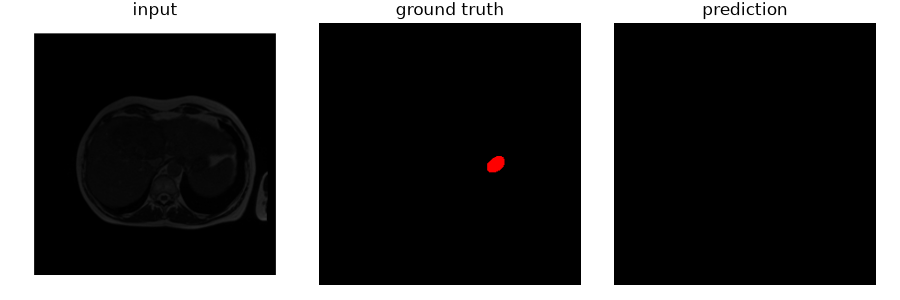

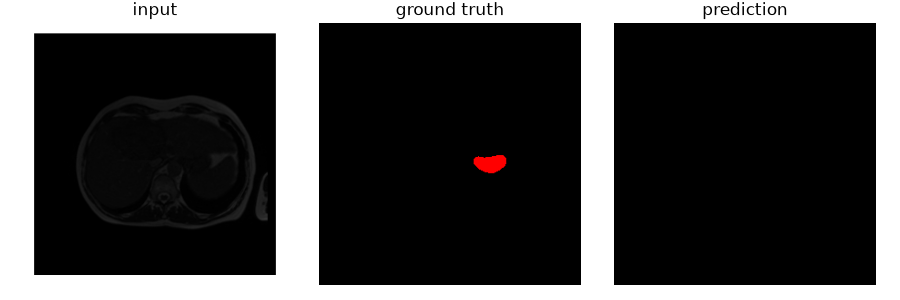

1786512-segformer_train_25d/fold4: segformer, fold 4, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7705.0


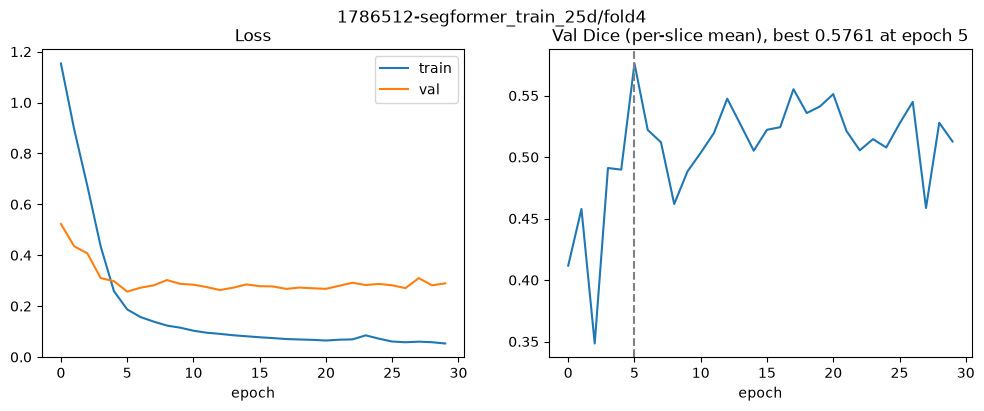

checkpoint_best.pt (epoch 5): val_dice per-slice mean = 0.5761, validated on cases [9, 29, 46]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.707,0.388,3.232,0.054,242086.0,47396.0,153189.0,1415
small_bowel,0.565,0.502,1.888,0.201,383722.0,204739.0,386620.0,1701
large_bowel,0.506,0.537,1.463,0.333,170667.0,135422.0,198140.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.239,0.001,0.760
small_bowel,0.026,0.000,0.311,0.663
large_bowel,0.024,0.536,0.000,0.440


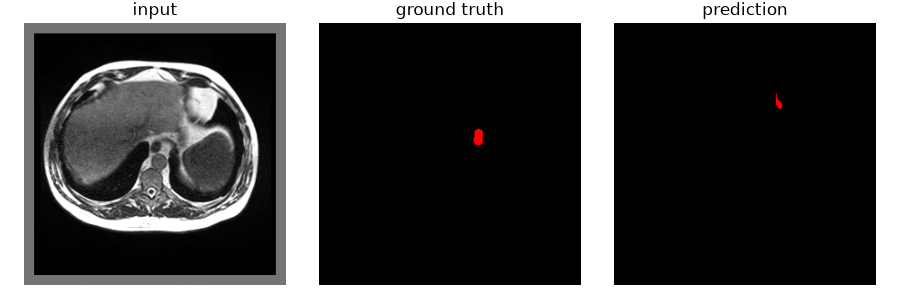

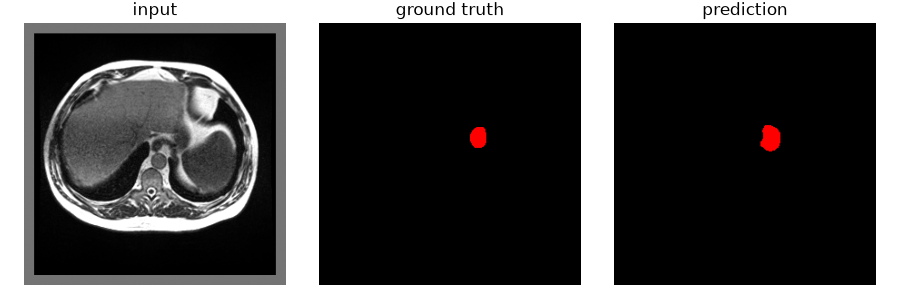

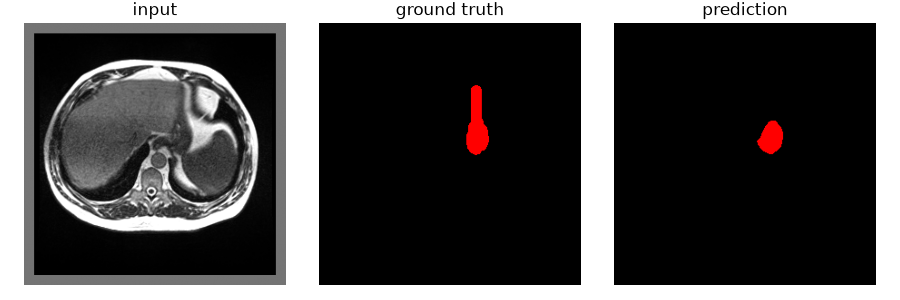

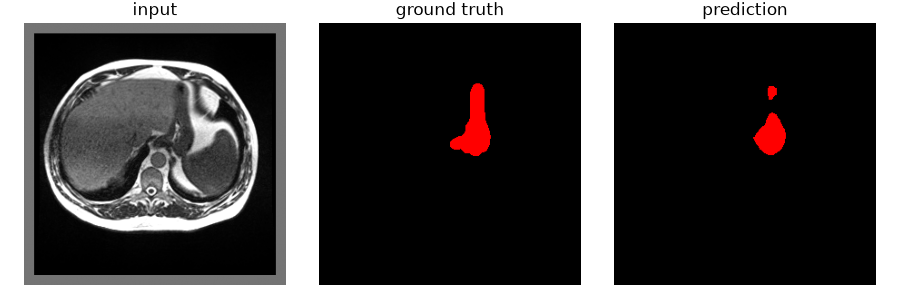

In [131]:
CV_JOB = '1786512-segformer_train_25d'
CV_ARCHITECTURE = 'segformer'

cv_folders = [f'{CV_JOB}/fold{k}' for k in range(5)]
for folder in cv_folders:
    analyse_run(folder, CV_ARCHITECTURE, data=train_25d)

In [132]:
cv = pd.DataFrame([
    {
        'fold': RUN_RESULTS[folder]['fold'], 'val cases': RUN_RESULTS[folder]['val_cases'],
        'val_dice': RUN_RESULTS[folder]['val_dice'],
        **{f'dice {cls}': dice for cls, dice in RUN_RESULTS[folder]['per_class']['dice_pooled'].items()},
    }
    for folder in cv_folders
]).set_index('fold')
display(cv.round(3))
display(cv.drop(columns='val cases').agg(['mean', 'std']).round(3))

,val cases,val_dice,dice stomach,dice small_bowel,dice large_bowel
fold,,,,,
0,"[0, 6]",0.609,0.690,0.576,0.669
1,"[2, 24, 60]",0.704,0.803,0.610,0.749
2,"[17, 20, 45]",0.674,0.826,0.646,0.727
3,"[33, 50, 57]",0.504,0.623,0.514,0.584
4,"[9, 29, 46]",0.576,0.707,0.565,0.506


,val_dice,dice stomach,dice small_bowel,dice large_bowel
mean,0.614,0.730,0.582,0.647
std,0.080,0.084,0.049,0.101


## Results

Mean val Dice is 0.614 against 0.585 for the same architecture in 2D, so +0.029, and it is better on every one of the 5 folds (from +0.001 on fold 2 to +0.054 on fold 3).

Every class improves a little, and the stomach/small bowel confusion drops: 15% of stomach false positives land on real small bowel against 22% in 2D. The large bowel confusion does not move at all - 37% of its false positives are still real small bowel, the same as in 2D. So the neighbouring slices help the model place organs, but do not help it tell the two bowels apart.

The best epoch also comes later on most folds, which fits the extra context giving the model more to learn before it starts overfitting.

### U-Net++ 2.5d, 5 folds

- Input: 2.5D
- Loss: Dice + BCE

The same 2.5D input as above, with the U-Net++ decoder, to check whether the gain depends on the architecture.

1787653-unetplusplus_train_25d/fold0: unetplusplus, fold 0, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7889.0


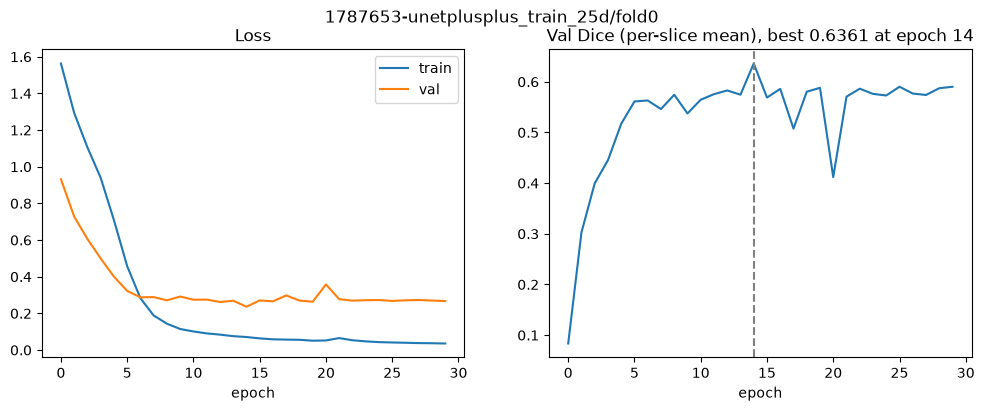

checkpoint_best.pt (epoch 14): val_dice per-slice mean = 0.6361, validated on cases [0, 6]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.700,0.417,5.033,0.256,200245.0,28488.0,143382.0,1415
small_bowel,0.598,0.373,0.790,0.423,379949.0,285732.0,225816.0,1701
large_bowel,0.706,0.238,0.596,0.166,384593.0,201069.0,119917.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.208,0.003,0.789
small_bowel,0.024,0.000,0.081,0.895
large_bowel,0.020,0.394,0.000,0.586


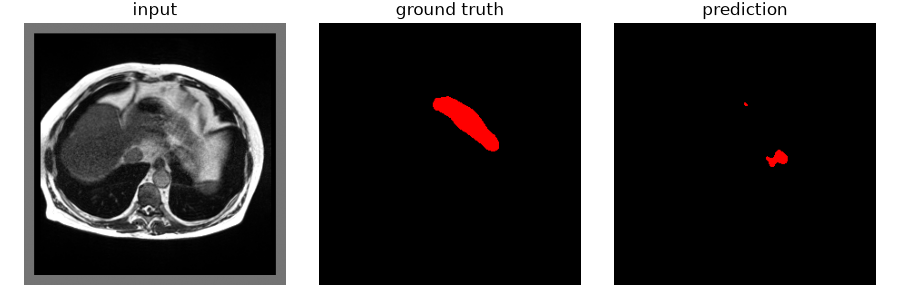

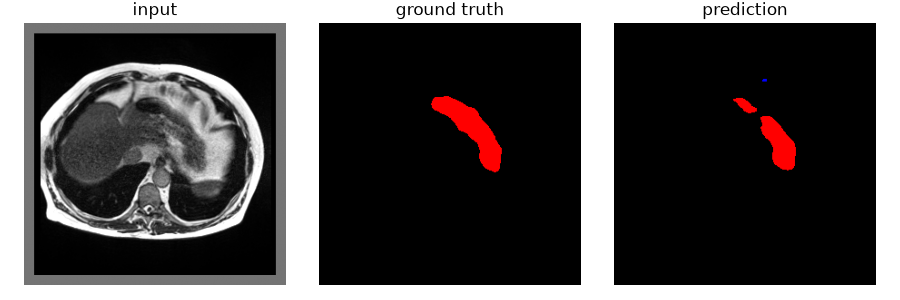

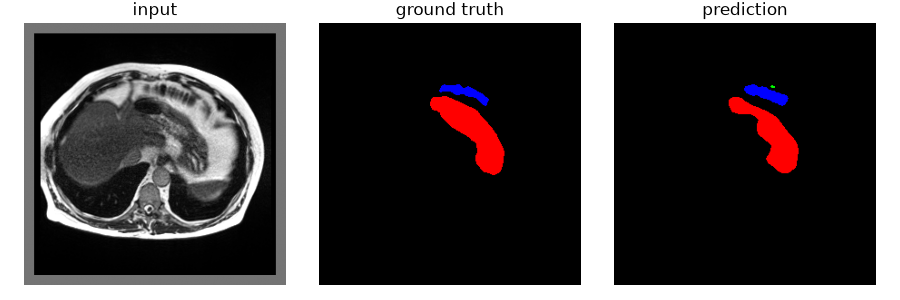

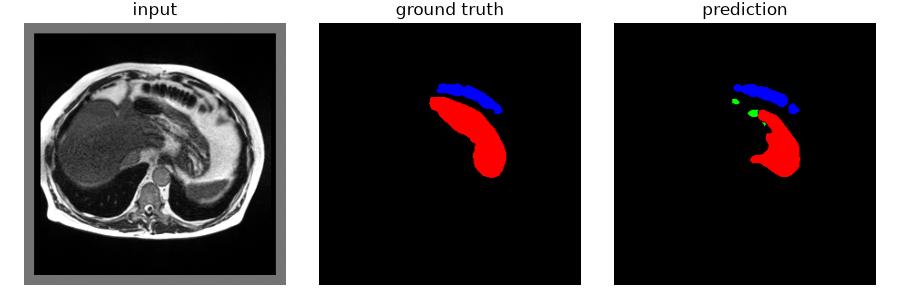

1787653-unetplusplus_train_25d/fold1: unetplusplus, fold 1, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7920.0


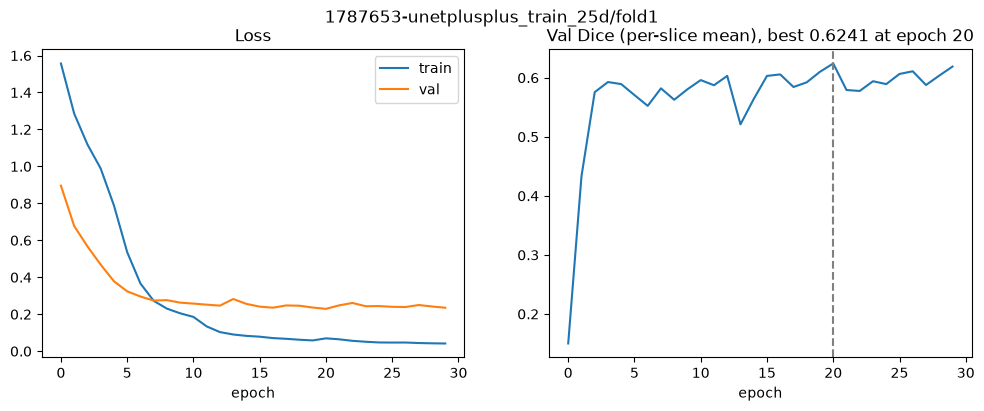

checkpoint_best.pt (epoch 20): val_dice per-slice mean = 0.6241, validated on cases [2, 24, 60]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.714,0.403,5.320,0.221,211175.0,26767.0,142402.0,1415
small_bowel,0.550,0.468,1.162,0.324,327074.0,247638.0,287819.0,1701
large_bowel,0.671,0.403,2.224,0.457,463562.0,140729.0,312991.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.051,0.185,0.765
small_bowel,0.106,0.000,0.339,0.556
large_bowel,0.017,0.294,0.000,0.689


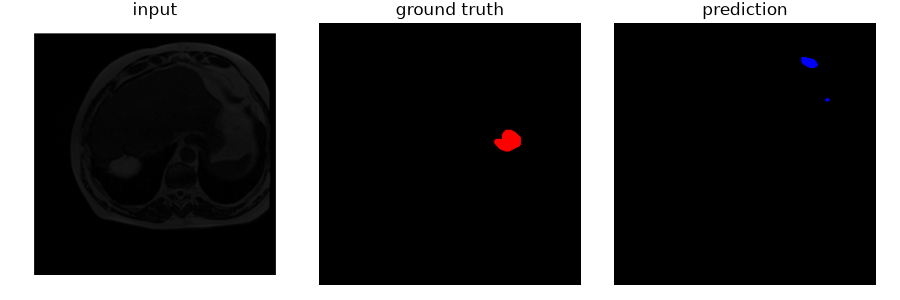

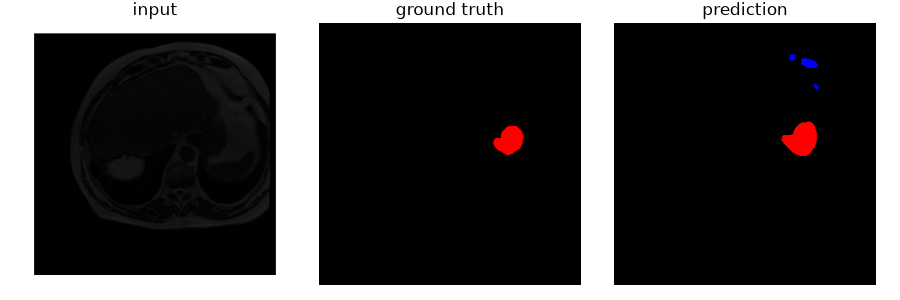

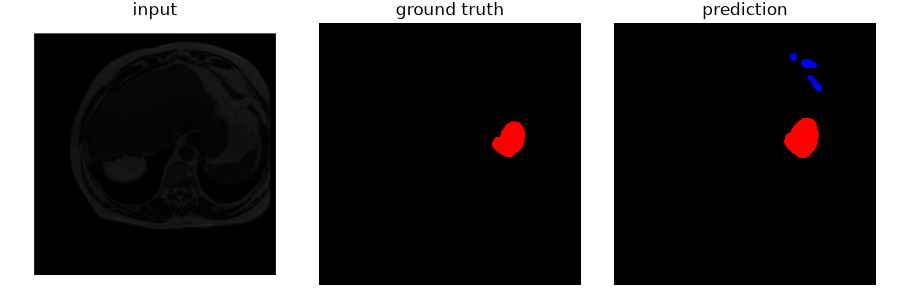

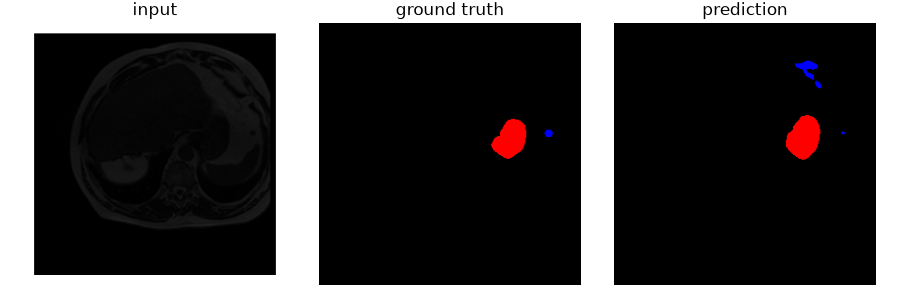

1787653-unetplusplus_train_25d/fold2: unetplusplus, fold 2, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7700.0


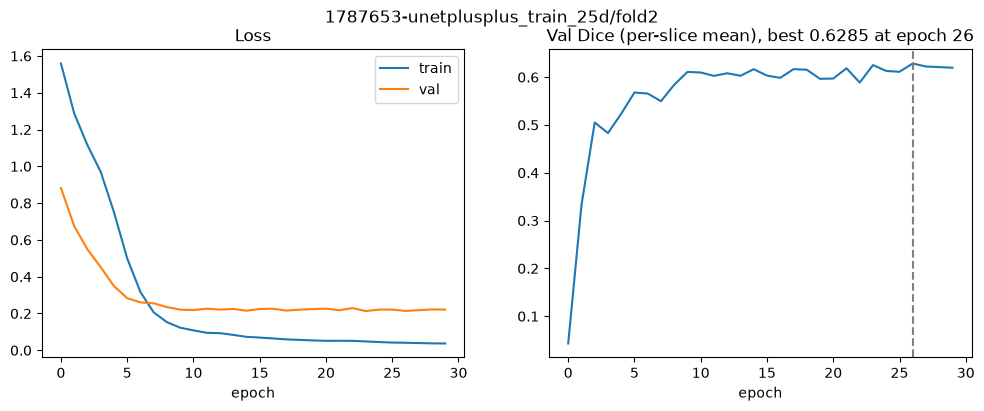

checkpoint_best.pt (epoch 26): val_dice per-slice mean = 0.6285, validated on cases [17, 20, 45]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.763,0.351,6.628,0.445,296753.0,24222.0,160555.0,1415
small_bowel,0.629,0.365,0.947,0.239,397949.0,241566.0,228649.0,1701
large_bowel,0.694,0.389,2.587,0.173,503343.0,123773.0,320173.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.082,0.142,0.777
small_bowel,0.028,0.000,0.384,0.587
large_bowel,0.057,0.341,0.000,0.602


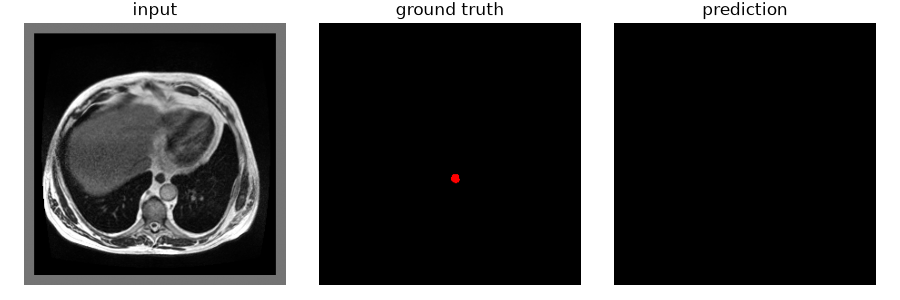

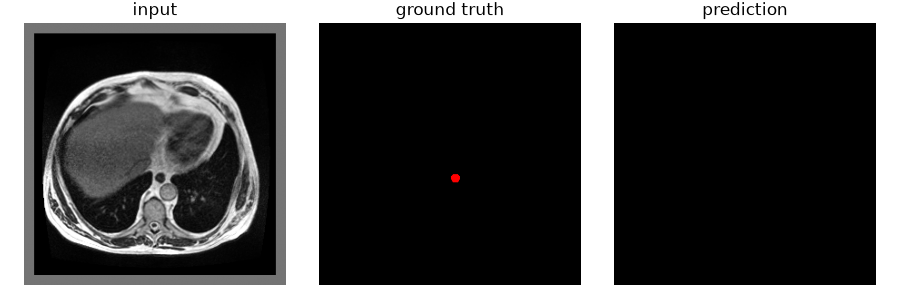

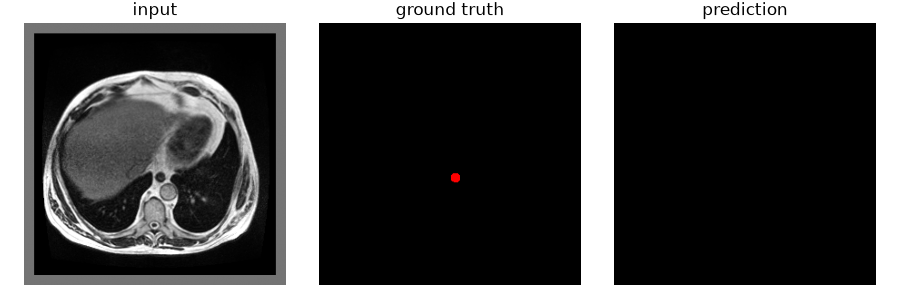

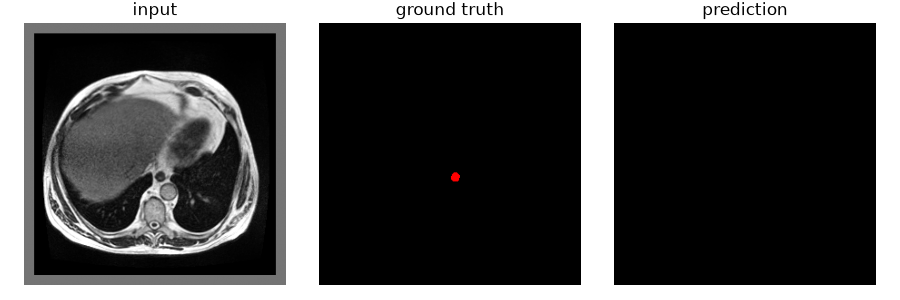

1787653-unetplusplus_train_25d/fold3: unetplusplus, fold 3, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7728.0


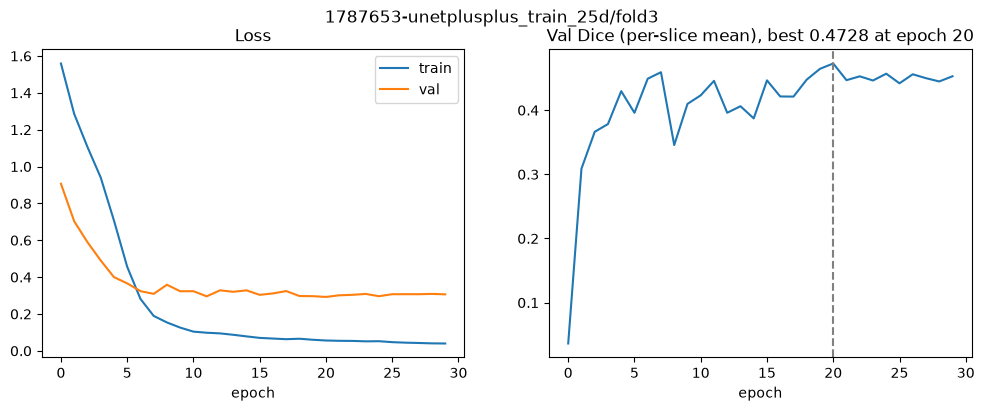

checkpoint_best.pt (epoch 20): val_dice per-slice mean = 0.4728, validated on cases [33, 50, 57]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.591,0.549,7.384,0.060,133954.0,22106.0,163240.0,1415
small_bowel,0.527,0.522,1.549,0.332,295144.0,207846.0,321917.0,1701
large_bowel,0.597,0.451,1.556,0.391,244964.0,129553.0,201636.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.172,0.013,0.816
small_bowel,0.255,0.000,0.212,0.533
large_bowel,0.127,0.332,0.000,0.542


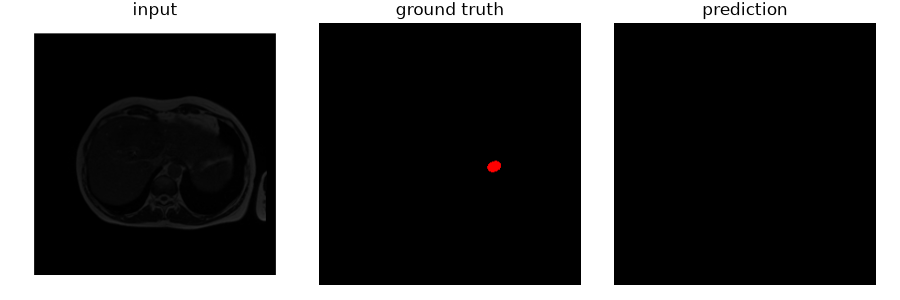

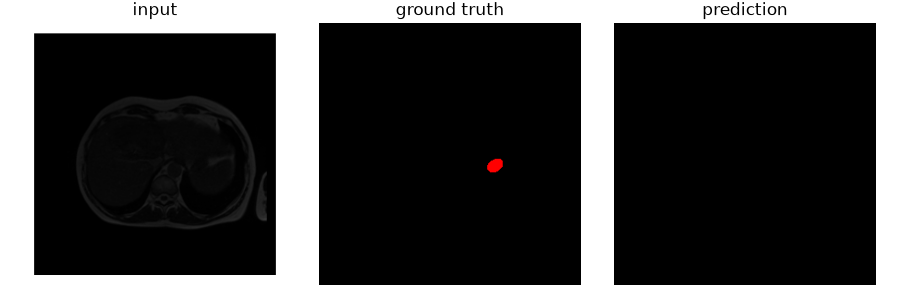

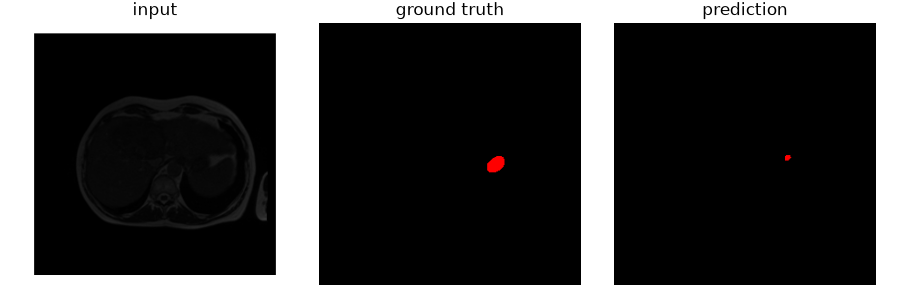

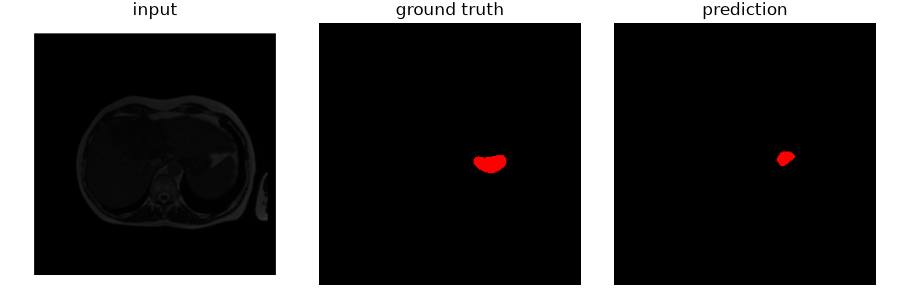

1787653-unetplusplus_train_25d/fold4: unetplusplus, fold 4, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7705.0


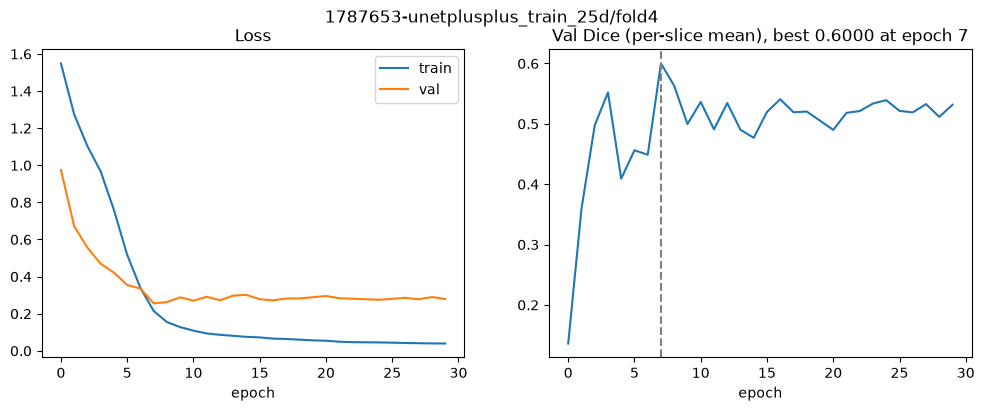

checkpoint_best.pt (epoch 7): val_dice per-slice mean = 0.6000, validated on cases [9, 29, 46]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.710,0.357,2.110,0.094,254314.0,66800.0,140961.0,1415
small_bowel,0.592,0.402,0.953,0.265,460790.0,324664.0,309552.0,1701
large_bowel,0.520,0.509,1.277,0.306,181058.0,147001.0,187749.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.322,0.021,0.657
small_bowel,0.032,0.000,0.238,0.731
large_bowel,0.016,0.489,0.000,0.496


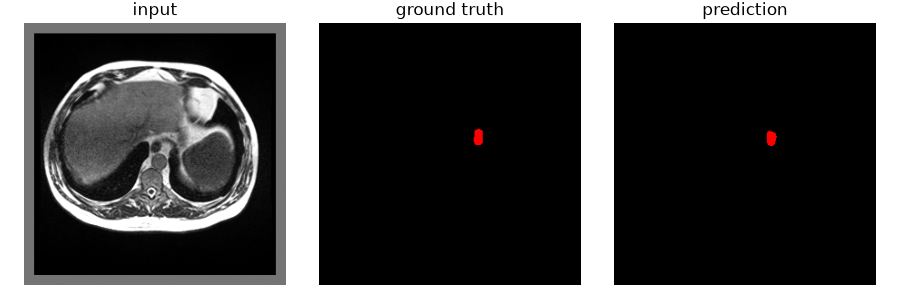

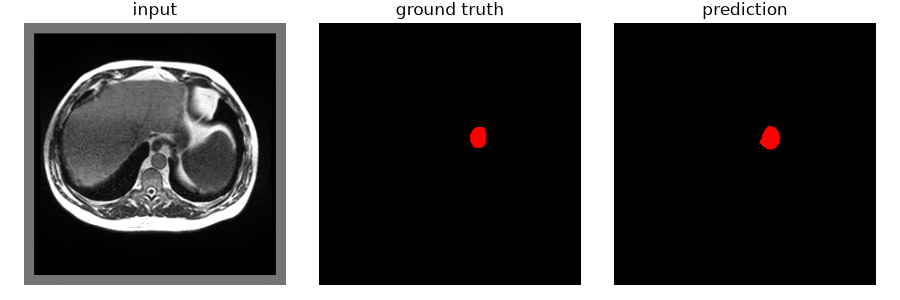

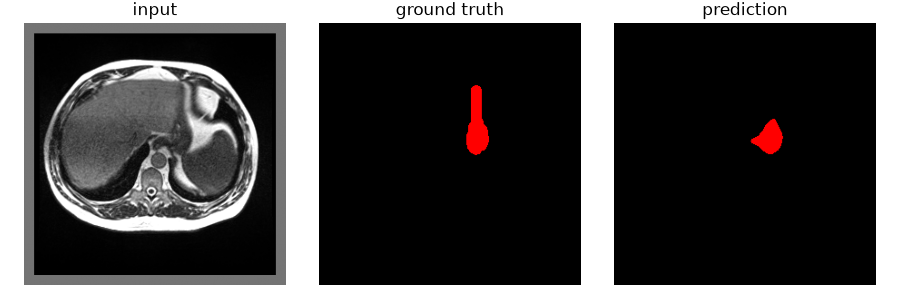

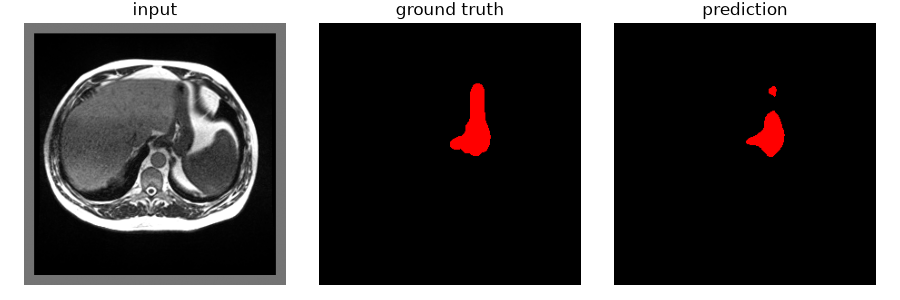

In [134]:
CV_JOB = '1787653-unetplusplus_train_25d'
CV_ARCHITECTURE = 'unetplusplus'

cv_folders = [f'{CV_JOB}/fold{k}' for k in range(5)]
for folder in cv_folders:
    analyse_run(folder, CV_ARCHITECTURE, data=train_25d)

In [135]:
cv = pd.DataFrame([
    {
        'fold': RUN_RESULTS[folder]['fold'], 'val cases': RUN_RESULTS[folder]['val_cases'],
        'val_dice': RUN_RESULTS[folder]['val_dice'],
        **{f'dice {cls}': dice for cls, dice in RUN_RESULTS[folder]['per_class']['dice_pooled'].items()},
    }
    for folder in cv_folders
]).set_index('fold')
display(cv.round(3))
display(cv.drop(columns='val cases').agg(['mean', 'std']).round(3))

,val cases,val_dice,dice stomach,dice small_bowel,dice large_bowel
fold,,,,,
0,"[0, 6]",0.636,0.700,0.598,0.706
1,"[2, 24, 60]",0.624,0.714,0.550,0.671
2,"[17, 20, 45]",0.628,0.763,0.629,0.694
3,"[33, 50, 57]",0.473,0.591,0.527,0.597
4,"[9, 29, 46]",0.600,0.710,0.592,0.520


,val_dice,dice stomach,dice small_bowel,dice large_bowel
mean,0.592,0.695,0.579,0.637
std,0.068,0.063,0.040,0.078


## Results

Mean val Dice is 0.592 against 0.571 in 2D, so +0.021, and again better on all 5 folds (+0.003 to +0.042). The direction matches SegFormer, so the 2.5D gain is a property of the input and not of one architecture.

The per-class pattern repeats as well: stomach false positives landing on small bowel drop from 22% to 17%, while large bowel false positives on small bowel stay at 37%.

The spread across folds is also the smallest of the four runs (0.068).

1794273-segformer_train_aug_25d/fold0: segformer, fold 0, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7889.0


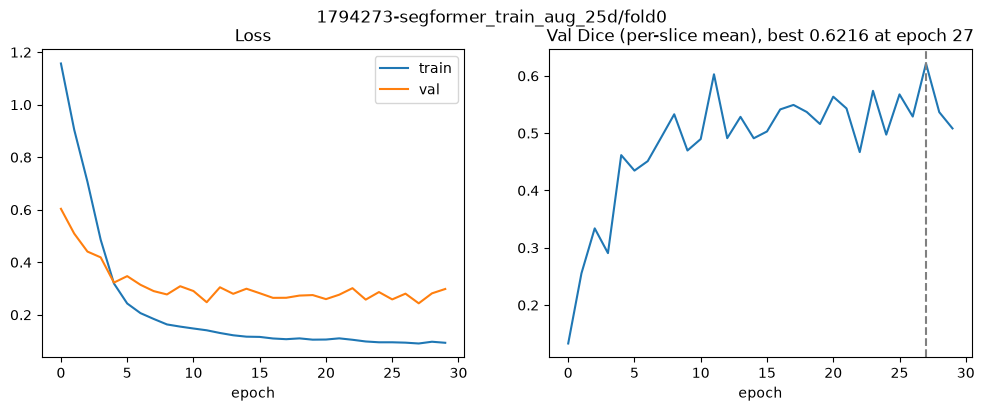

checkpoint_best.pt (epoch 27): val_dice per-slice mean = 0.6217, validated on cases [0, 6]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.692,0.449,10.448,0.380,189442.0,14758.0,154185.0,1415
small_bowel,0.601,0.439,1.432,0.496,339782.0,185679.0,265983.0,1701
large_bowel,0.706,0.187,0.383,0.212,409991.0,246746.0,94519.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.329,0.001,0.670
small_bowel,0.023,0.000,0.073,0.903
large_bowel,0.038,0.393,0.000,0.570


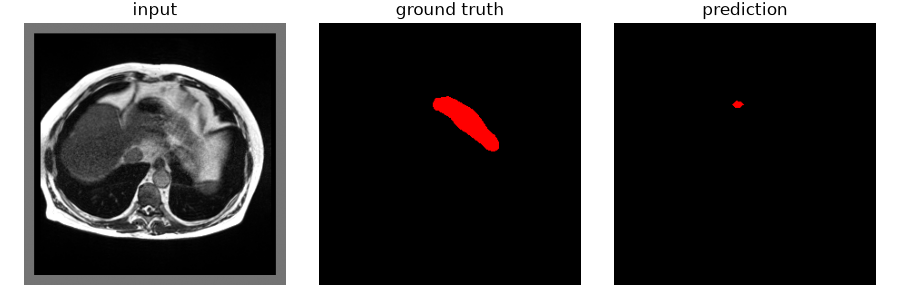

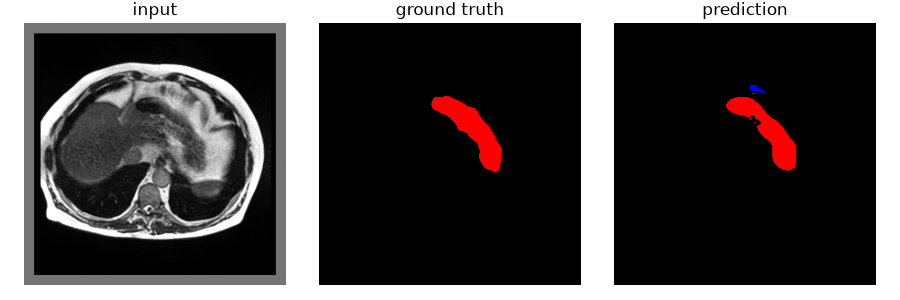

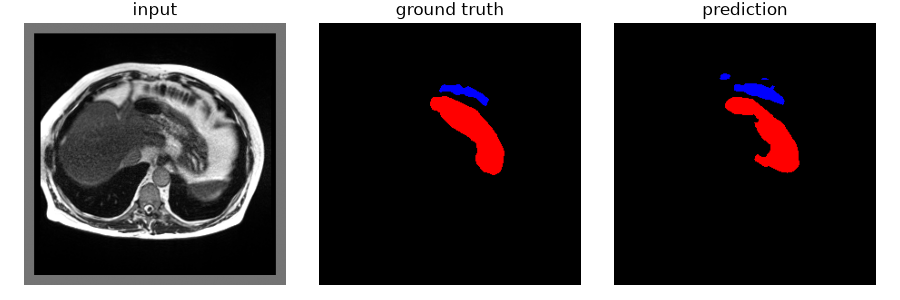

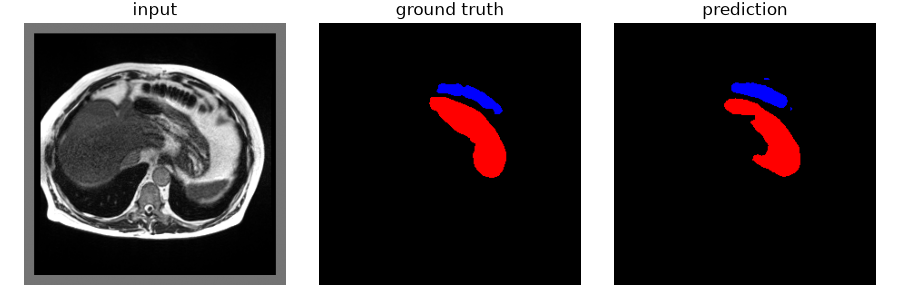

1794273-segformer_train_aug_25d/fold1: segformer, fold 1, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7920.0


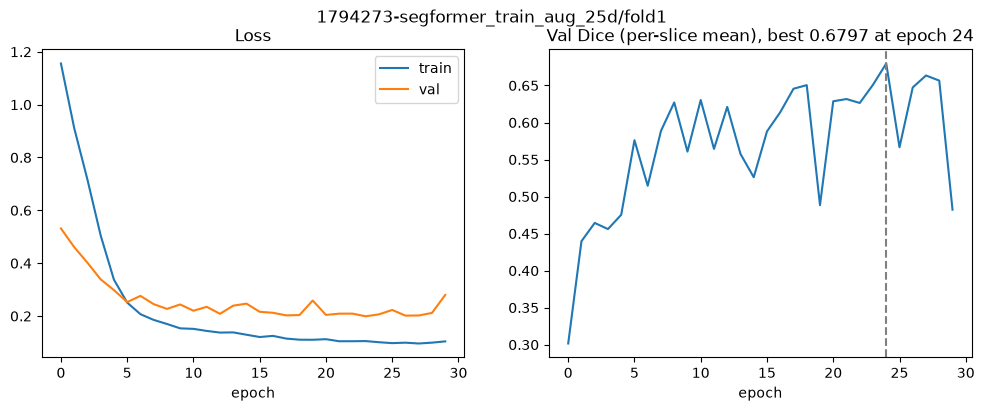

checkpoint_best.pt (epoch 24): val_dice per-slice mean = 0.6797, validated on cases [2, 24, 60]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.799,0.293,4.805,0.077,249830.0,21590.0,103747.0,1415
small_bowel,0.582,0.404,0.892,0.464,366604.0,278351.0,248289.0,1701
large_bowel,0.721,0.310,1.388,0.664,535481.0,173663.0,241072.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.033,0.085,0.882
small_bowel,0.064,0.000,0.293,0.643
large_bowel,0.017,0.123,0.000,0.860


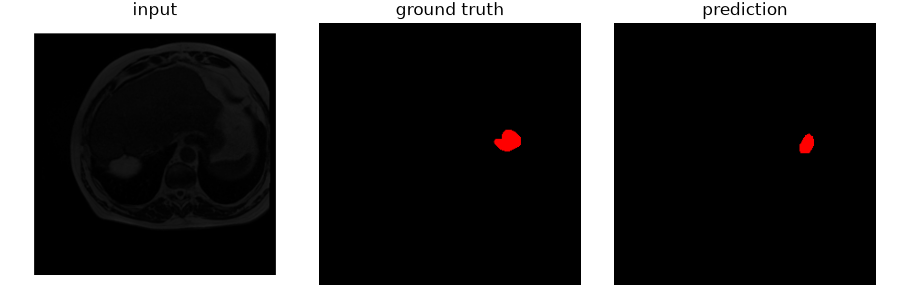

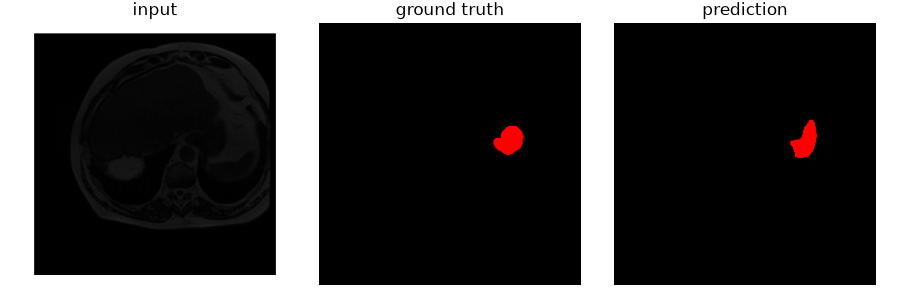

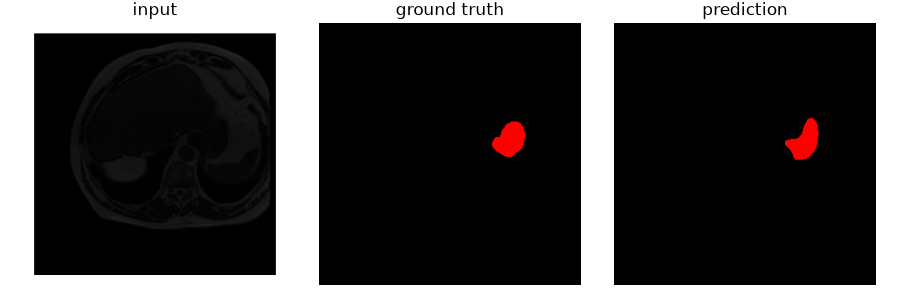

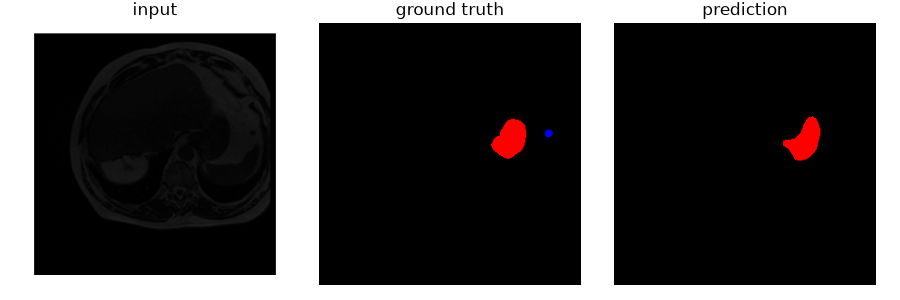

1794273-segformer_train_aug_25d/fold2: segformer, fold 2, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7700.0


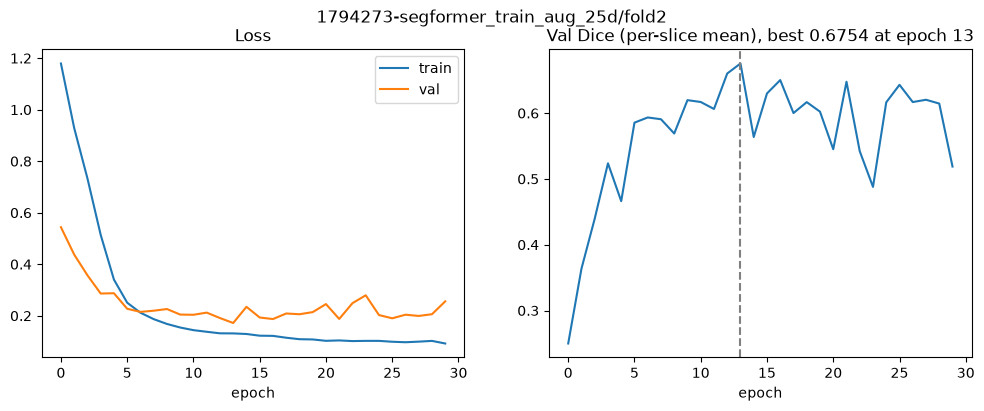

checkpoint_best.pt (epoch 13): val_dice per-slice mean = 0.6754, validated on cases [17, 20, 45]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.828,0.248,3.871,0.176,343782.0,29328.0,113526.0,1415
small_bowel,0.688,0.300,0.896,0.091,438312.0,210111.0,188286.0,1701
large_bowel,0.738,0.328,2.178,0.085,553630.0,123937.0,269886.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.018,0.221,0.761
small_bowel,0.012,0.000,0.355,0.634
large_bowel,0.033,0.242,0.000,0.725


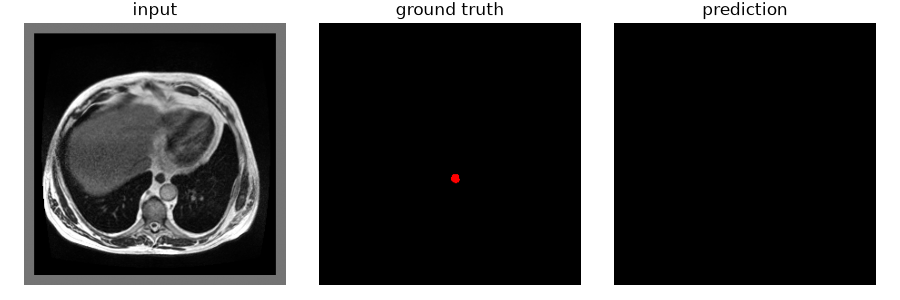

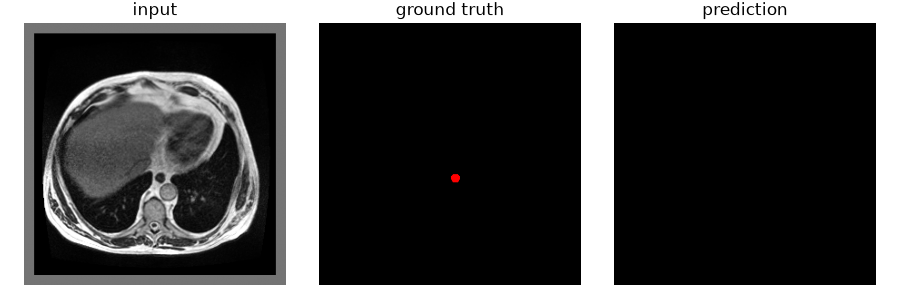

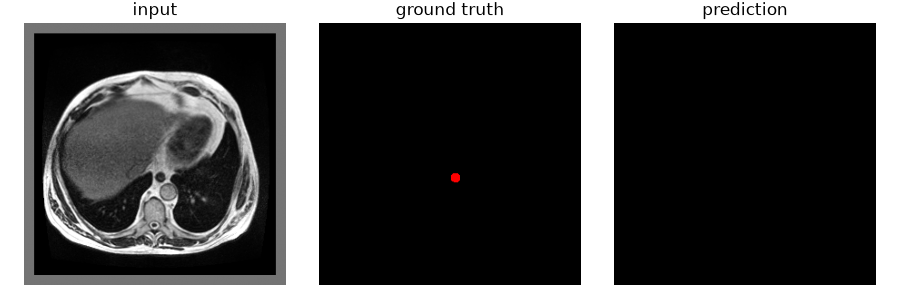

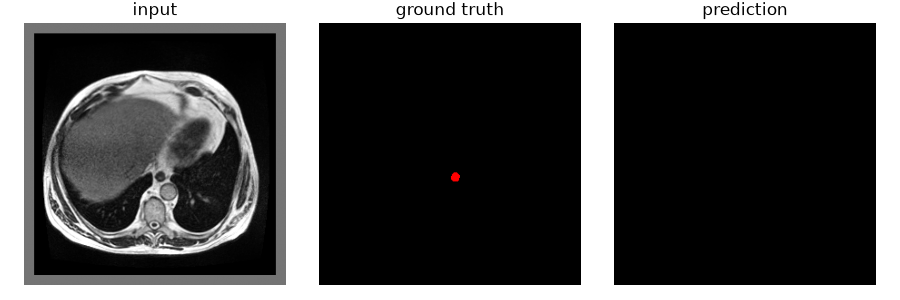

1794273-segformer_train_aug_25d/fold3: segformer, fold 3, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7728.0


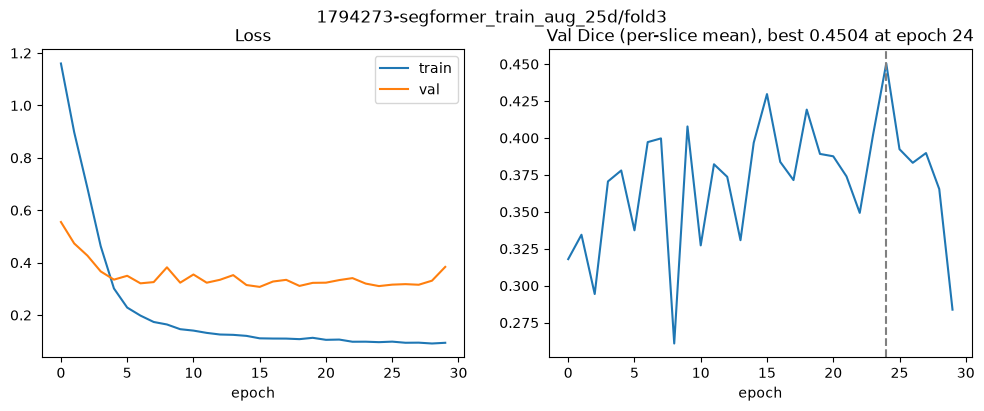

checkpoint_best.pt (epoch 24): val_dice per-slice mean = 0.4504, validated on cases [33, 50, 57]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.550,0.597,9.586,0.010,119745.0,18512.0,177449.0,1415
small_bowel,0.521,0.372,0.475,0.380,387310.0,483772.0,229751.0,1701
large_bowel,0.569,0.463,1.321,0.471,239887.0,156444.0,206713.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.071,0.021,0.908
small_bowel,0.174,0.000,0.178,0.649
large_bowel,0.107,0.182,0.000,0.711


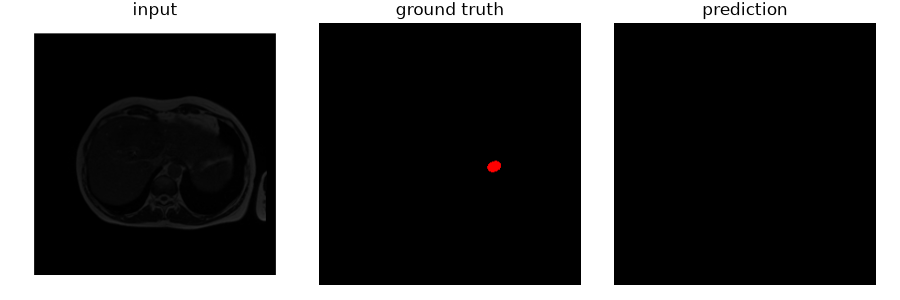

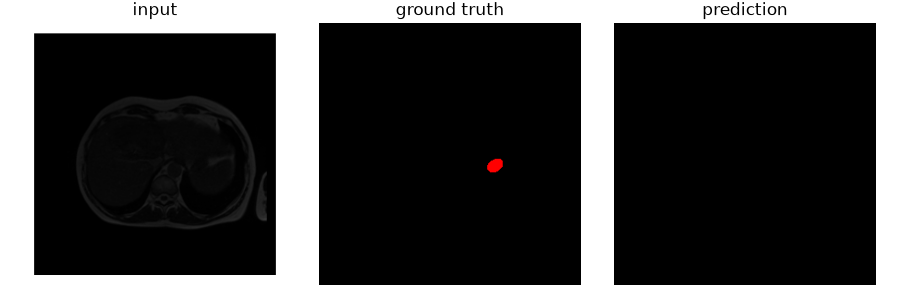

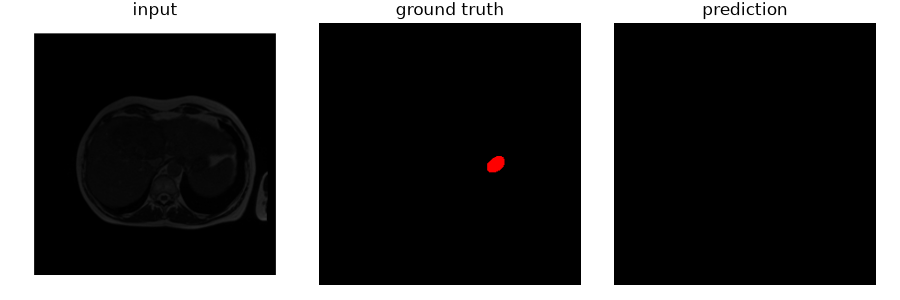

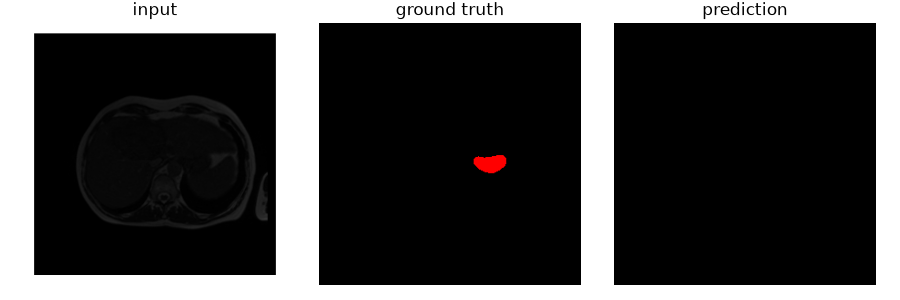

1794273-segformer_train_aug_25d/fold4: segformer, fold 4, 30 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7705.0


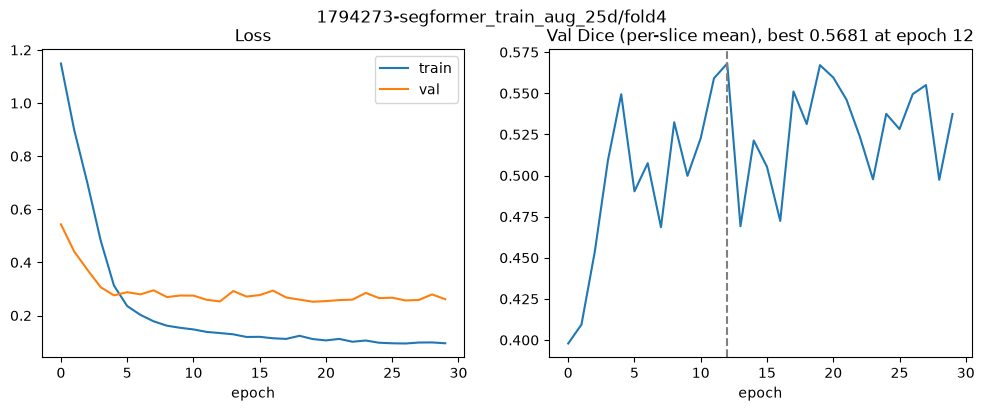

checkpoint_best.pt (epoch 12): val_dice per-slice mean = 0.5681, validated on cases [9, 29, 46]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.696,0.392,2.796,0.212,240496.0,55367.0,154779.0,1415
small_bowel,0.512,0.600,3.660,0.281,308155.0,126267.0,462187.0,1701
large_bowel,0.506,0.513,1.172,0.256,179570.0,161409.0,189237.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.280,0.047,0.674
small_bowel,0.003,0.000,0.293,0.704
large_bowel,0.022,0.617,0.000,0.362


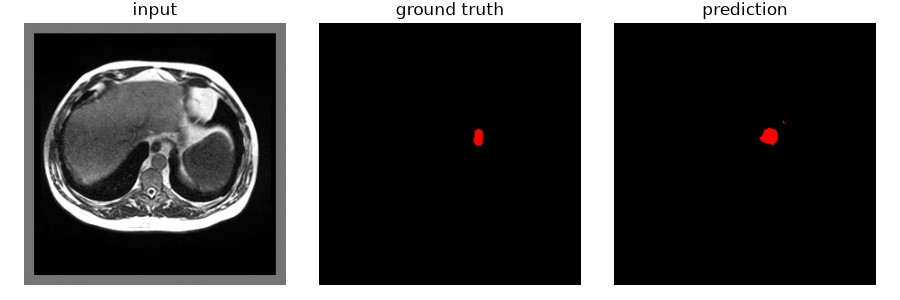

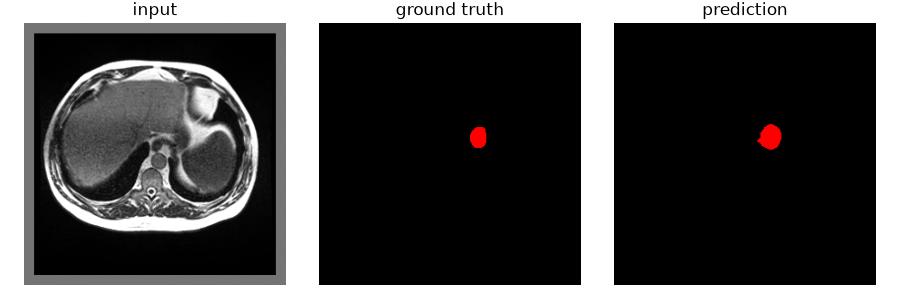

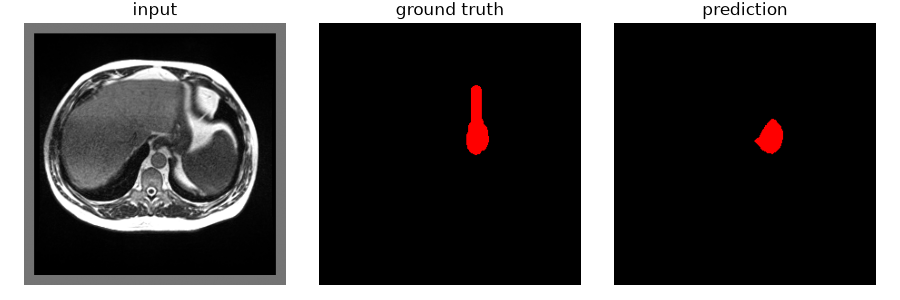

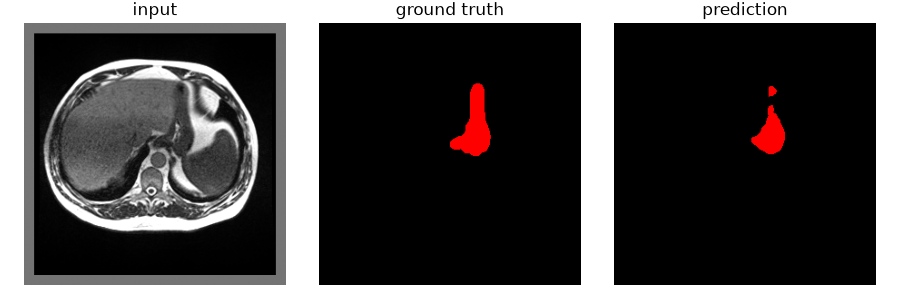

In [136]:
CV_JOB = '1794273-segformer_train_aug_25d'
CV_ARCHITECTURE = 'segformer'

cv_folders = [f'{CV_JOB}/fold{k}' for k in range(5)]
for folder in cv_folders:
    analyse_run(folder, CV_ARCHITECTURE, data=train_25d)

In [137]:
cv = pd.DataFrame([
    {
        'fold': RUN_RESULTS[folder]['fold'], 'val cases': RUN_RESULTS[folder]['val_cases'],
        'val_dice': RUN_RESULTS[folder]['val_dice'],
        **{f'dice {cls}': dice for cls, dice in RUN_RESULTS[folder]['per_class']['dice_pooled'].items()},
    }
    for folder in cv_folders
]).set_index('fold')
display(cv.round(3))
display(cv.drop(columns='val cases').agg(['mean', 'std']).round(3))

,val cases,val_dice,dice stomach,dice small_bowel,dice large_bowel
fold,,,,,
0,"[0, 6]",0.622,0.692,0.601,0.706
1,"[2, 24, 60]",0.680,0.799,0.582,0.721
2,"[17, 20, 45]",0.675,0.828,0.688,0.738
3,"[33, 50, 57]",0.450,0.550,0.521,0.569
4,"[9, 29, 46]",0.568,0.696,0.512,0.506


,val_dice,dice stomach,dice small_bowel,dice large_bowel
mean,0.599,0.713,0.580,0.648
std,0.095,0.110,0.071,0.104


## Augmentation

Every run above overfits, so this is the first attempt at doing something about it.

I used:
- random affine (rotation, scale, shift, shear) and grid distortion, because patient positioning varies between scan days and most of the organs is soft tissue that really deforms
- random scale, shift, gamma and an MRI bias field, because brightness varies between scanners and sessions

In [138]:
import train_aug_25d

aug_train_dataset = train_aug_25d.SegDataset(new_train_df,
                                            preprocess_input=preprocess_input, 
                                            scale_intensity=scale_intensity, 
                                            pad_fn=pad,
                                            augment=train_aug_25d.build_augmentation())

[prev, current, next_slice], mask = next(iter(aug_train_dataset))

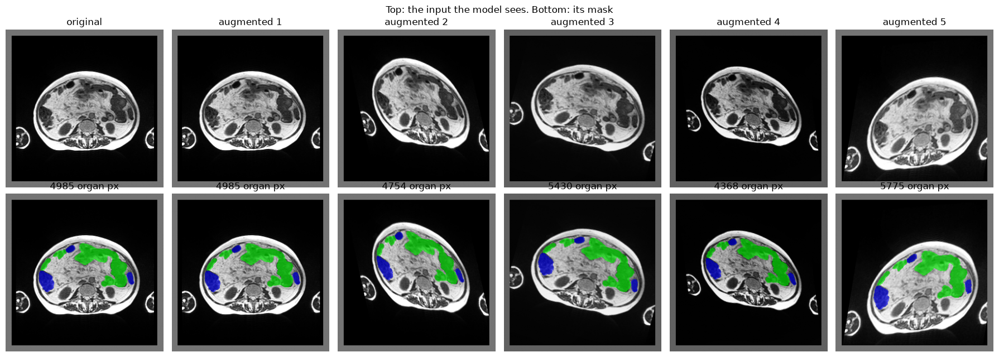

In [139]:
np.random.seed(2)
plain_dataset = train_aug_25d.SegDataset(new_train_df,
                                         preprocess_input=preprocess_input,
                                         scale_intensity=scale_intensity,
                                         pad_fn=pad)

seg = plain_dataset.seg_df
organ_slices = [i for i, key in enumerate(zip(seg['case'], seg['day'], seg['slice']))
                if plain_dataset.mask_lookup[key].any()]
index = organ_slices[len(organ_slices) // 2]

fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for col in range(6):
    image, mask = plain_dataset[index] if col == 0 else aug_train_dataset[index]
    current = image[1] # channel 1 of the 2.5D stack is the current slice
    overlay = mask.permute(1, 2, 0).numpy() # (H, W, 3): red stomach, green small bowel, blue large bowel

    axes[0, col].imshow(current, cmap='gray')
    axes[0, col].set_title('original' if col == 0 else f'augmented {col}')
    axes[1, col].imshow(current, cmap='gray')
    axes[1, col].imshow(overlay, alpha=overlay.max(axis=2) * 0.6)
    axes[1, col].set_title(f'{int(mask.sum())} organ px')

for ax in axes.ravel():
    ax.axis('off')
fig.suptitle('Top: the input the model sees. Bottom: its mask')
fig.tight_layout()
plt.show()

### SegFormer 2.5d + augmentation, 5 folds

- Input: 2.5D
- Loss: Dice + BCE
- Augmentation

Augmentation makes the model fit more slowly, so 30 epochs was no longer a fair budget. The run below repeats it with 60.

1794532-segformer_train_aug_25d/fold0: segformer, fold 0, 60 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7889.0


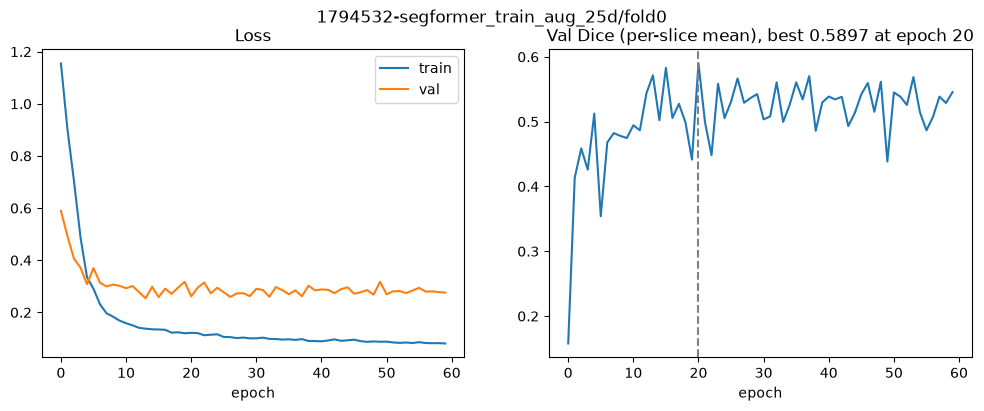

checkpoint_best.pt (epoch 20): val_dice per-slice mean = 0.5897, validated on cases [0, 6]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.743,0.349,3.444,0.028,223771.0,34798.0,119856.0,1415
small_bowel,0.578,0.409,0.902,0.421,357751.0,274902.0,248014.0,1701
large_bowel,0.667,0.224,0.407,0.180,391359.0,278213.0,113151.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.061,0.023,0.916
small_bowel,0.017,0.000,0.054,0.929
large_bowel,0.033,0.350,0.000,0.617


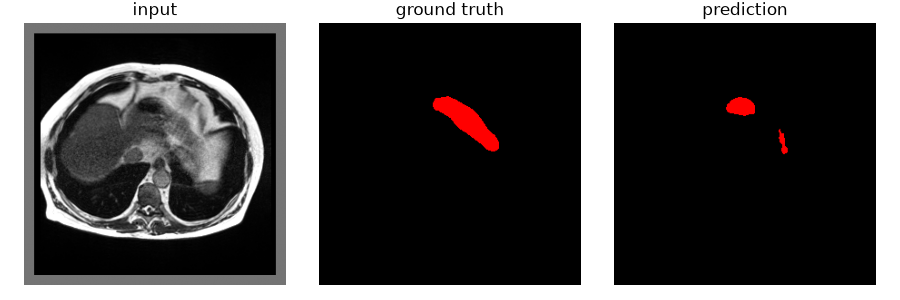

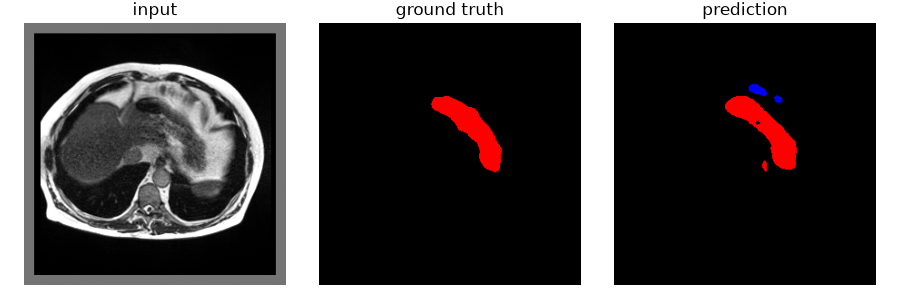

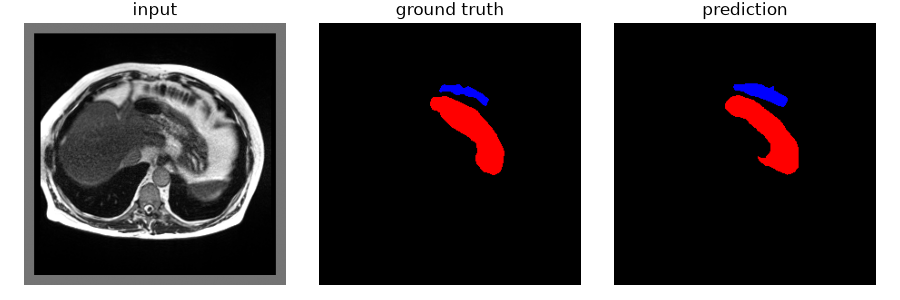

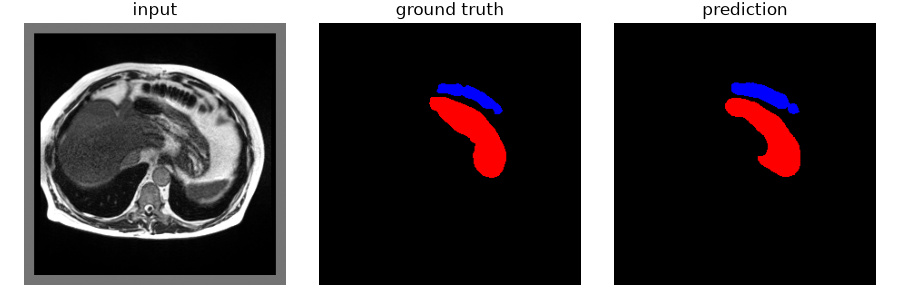

1794532-segformer_train_aug_25d/fold1: segformer, fold 1, 60 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7920.0


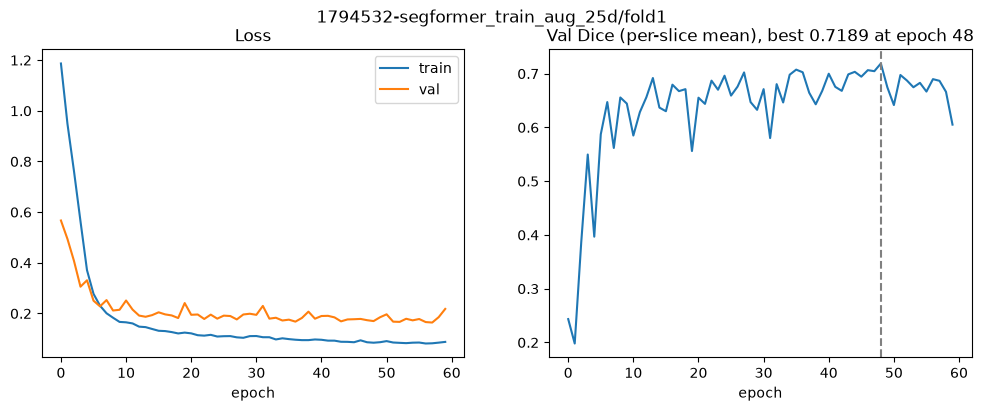

checkpoint_best.pt (epoch 48): val_dice per-slice mean = 0.7189, validated on cases [2, 24, 60]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.856,0.189,2.227,0.040,286882.0,29955.0,66695.0,1415
small_bowel,0.654,0.335,0.908,0.282,408939.0,226913.0,205954.0,1701
large_bowel,0.764,0.285,1.809,0.446,555277.0,122328.0,221276.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.044,0.044,0.912
small_bowel,0.054,0.000,0.349,0.597
large_bowel,0.006,0.165,0.000,0.829


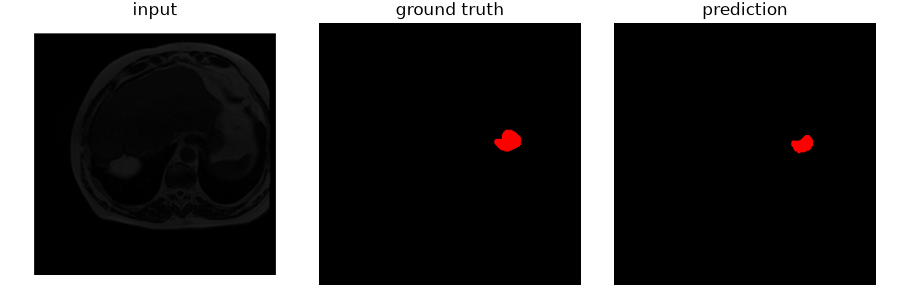

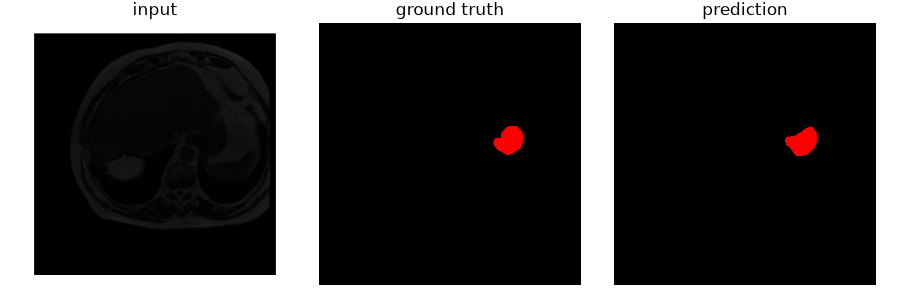

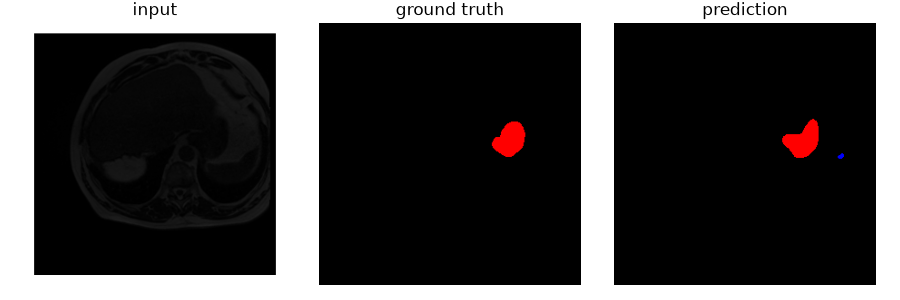

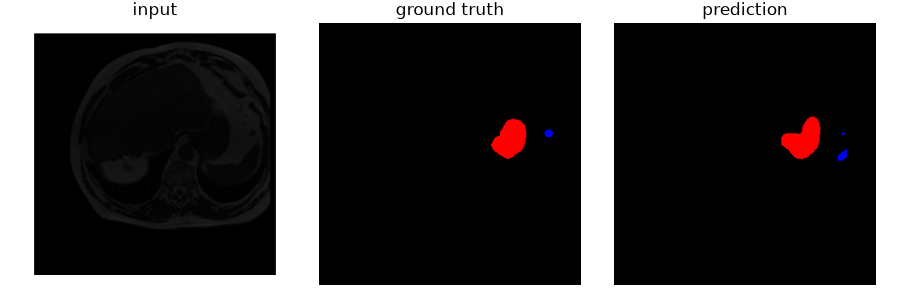

1794532-segformer_train_aug_25d/fold2: segformer, fold 2, 60 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7700.0


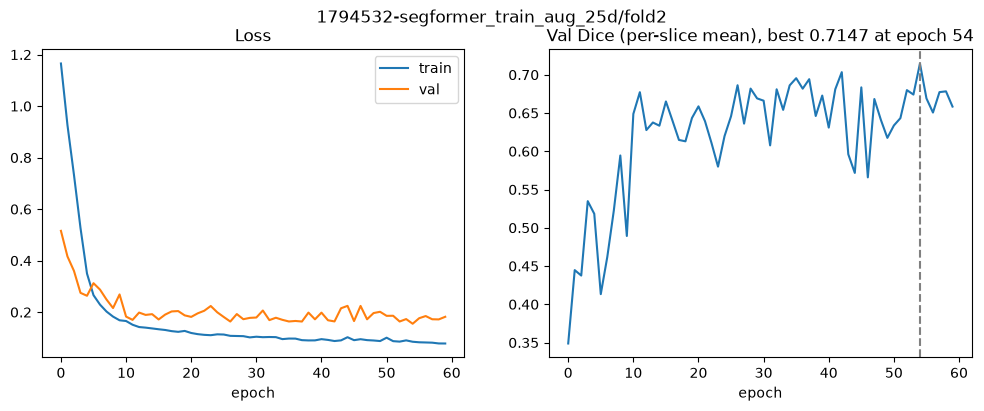

checkpoint_best.pt (epoch 54): val_dice per-slice mean = 0.7147, validated on cases [17, 20, 45]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.871,0.176,2.569,0.154,376711.0,31378.0,80597.0,1415
small_bowel,0.720,0.258,0.808,0.129,465156.0,199898.0,161442.0,1701
large_bowel,0.768,0.288,2.030,0.073,586558.0,116735.0,236958.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.017,0.154,0.829
small_bowel,0.019,0.000,0.357,0.624
large_bowel,0.069,0.297,0.000,0.634


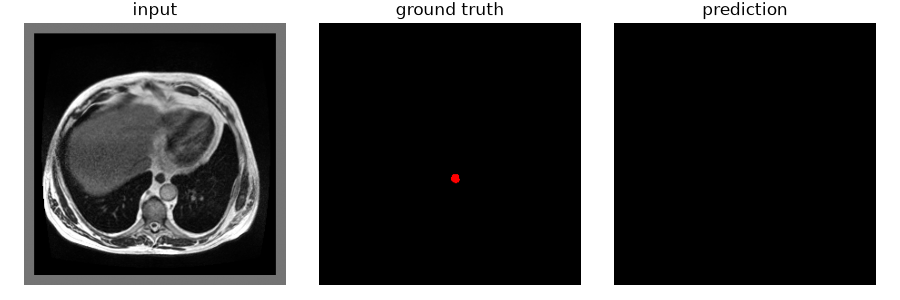

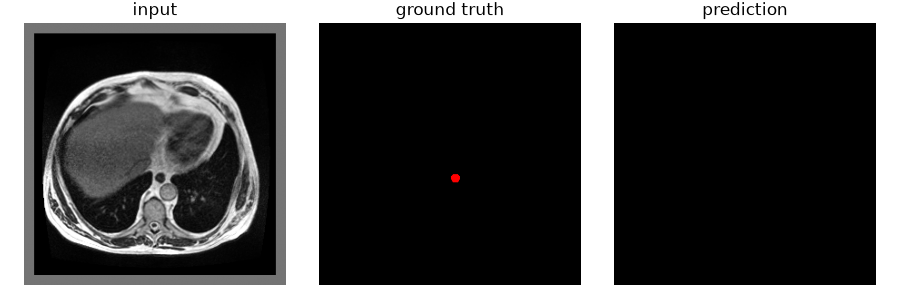

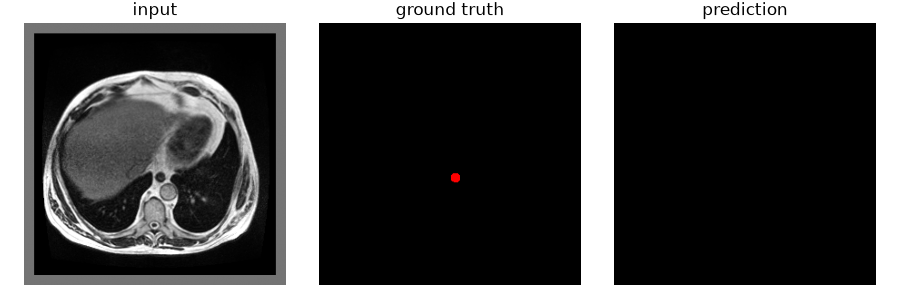

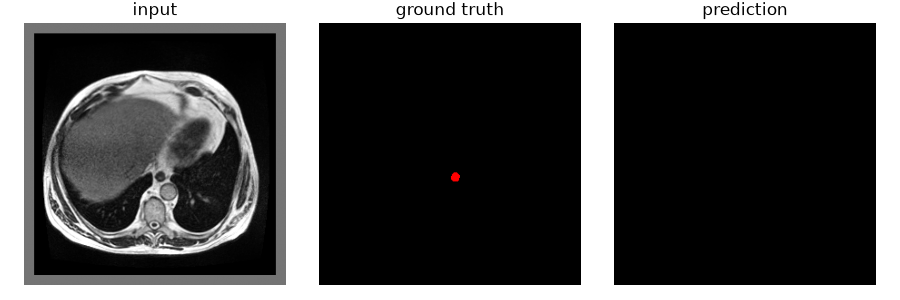

1794532-segformer_train_aug_25d/fold3: segformer, fold 3, 60 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7728.0


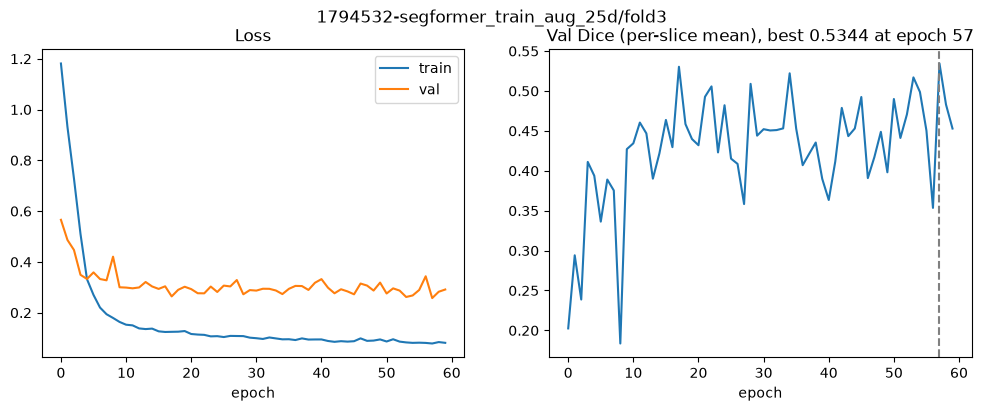

checkpoint_best.pt (epoch 57): val_dice per-slice mean = 0.5347, validated on cases [33, 50, 57]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.713,0.395,4.382,0.005,179687.0,26815.0,117507.0,1415
small_bowel,0.544,0.548,2.609,0.356,279170.0,129507.0,337891.0,1701
large_bowel,0.631,0.393,1.246,0.315,271059.0,140924.0,175541.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.131,0.025,0.844
small_bowel,0.144,0.000,0.310,0.547
large_bowel,0.125,0.346,0.000,0.530


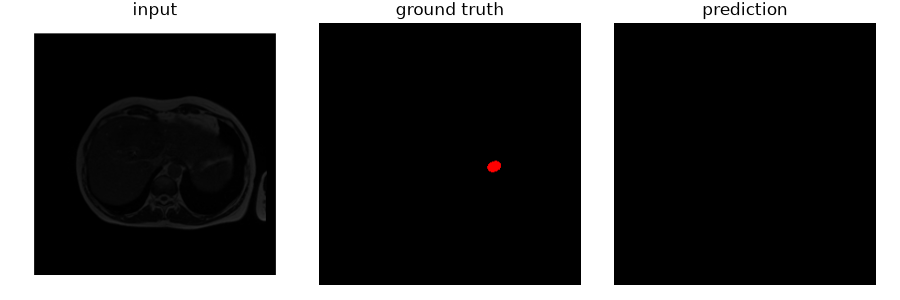

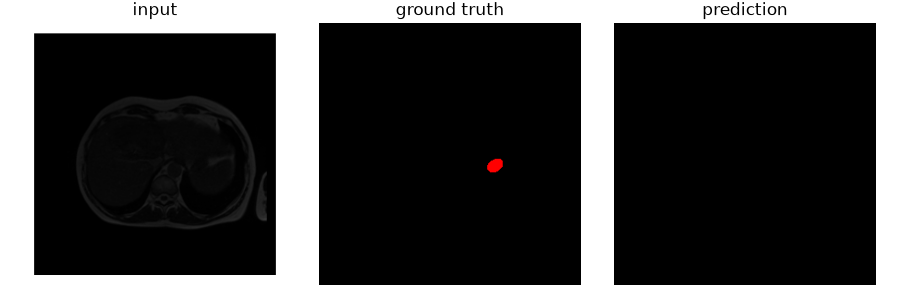

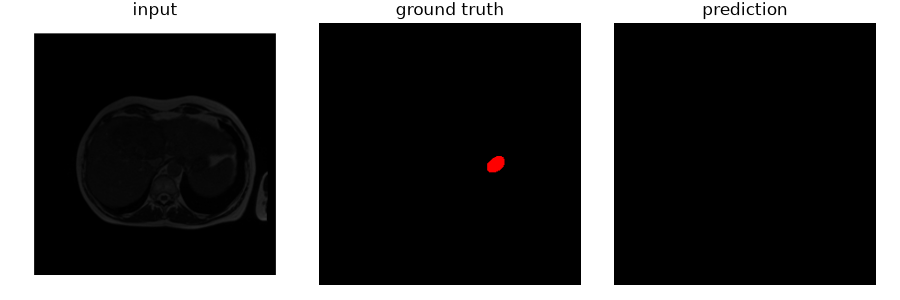

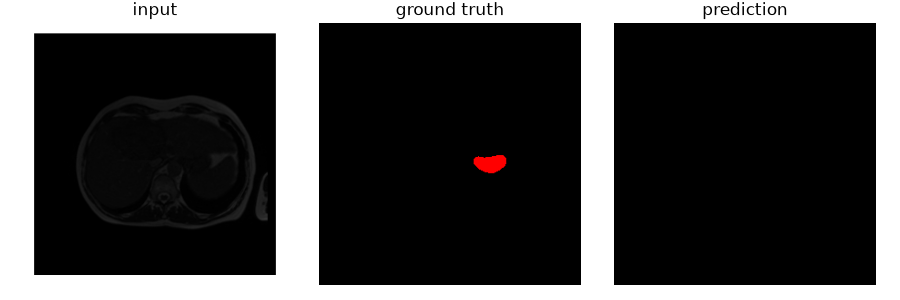

1794532-segformer_train_aug_25d/fold4: segformer, fold 4, 60 epochs, batch 32, lr 0.0001
Intensity range from train sample: p1=0.0, p99=7705.0


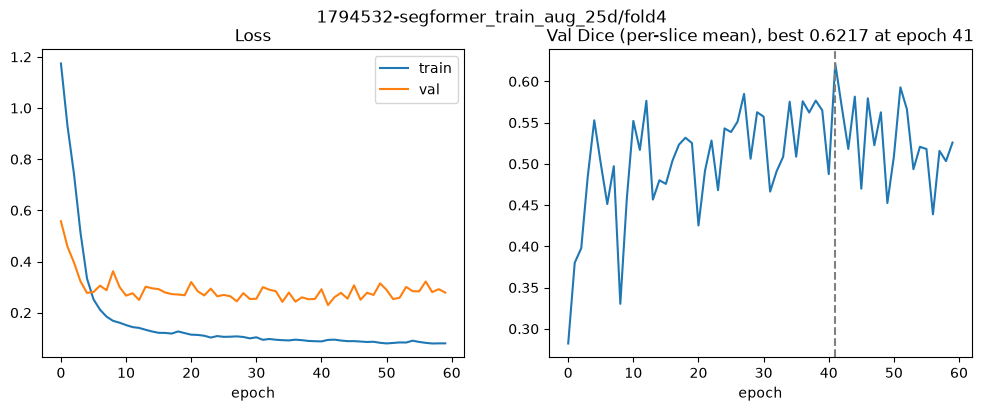

checkpoint_best.pt (epoch 41): val_dice per-slice mean = 0.6217, validated on cases [9, 29, 46]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.704,0.409,4.605,0.075,233696.0,35085.0,161579.0,1415
small_bowel,0.637,0.339,0.815,0.351,509384.0,320249.0,260958.0,1701
large_bowel,0.569,0.527,2.806,0.372,174368.0,69300.0,194439.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.221,0.012,0.767
small_bowel,0.042,0.000,0.294,0.664
large_bowel,0.003,0.404,0.000,0.593


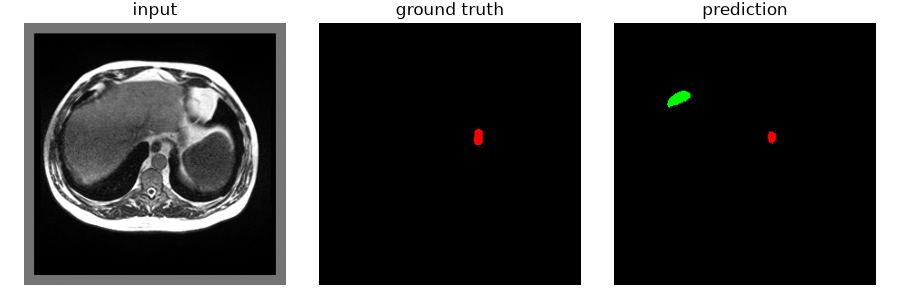

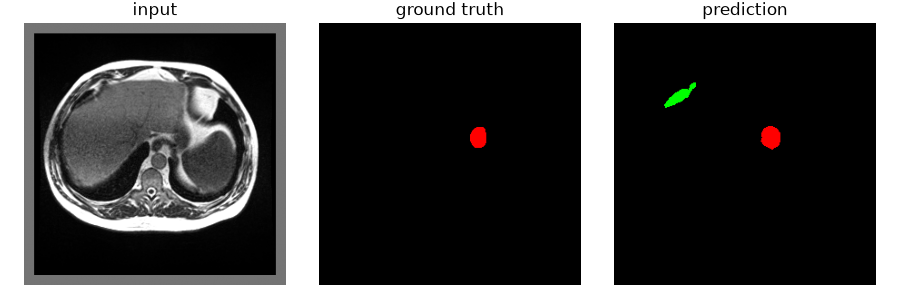

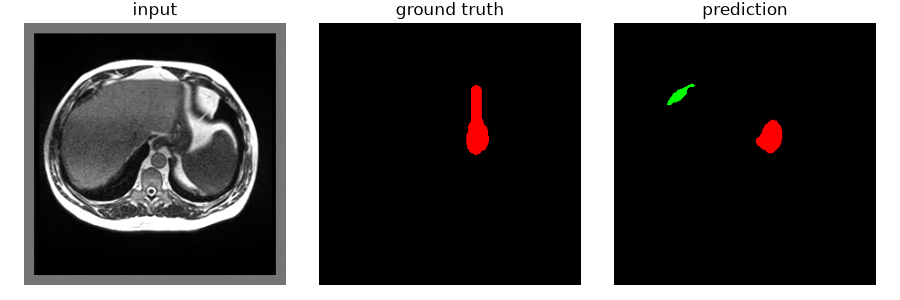

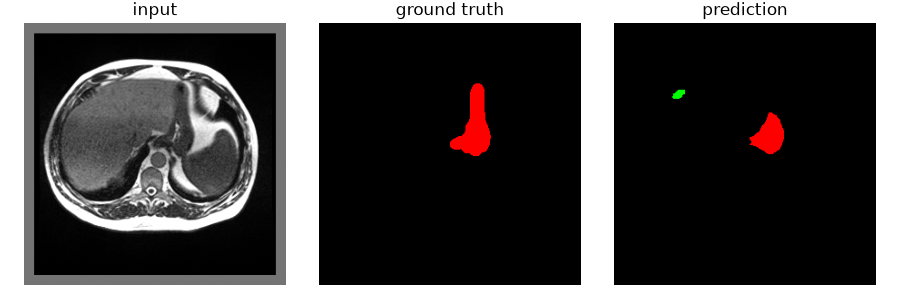

In [140]:
CV_JOB = '1794532-segformer_train_aug_25d'   # same as above but 60 epochs
CV_ARCHITECTURE = 'segformer'

cv_folders = [f'{CV_JOB}/fold{k}' for k in range(5)]
for folder in cv_folders:
    analyse_run(folder, CV_ARCHITECTURE, data=train_25d)

In [141]:
cv = pd.DataFrame([
    {
        'fold': RUN_RESULTS[folder]['fold'], 'val cases': RUN_RESULTS[folder]['val_cases'],
        'val_dice': RUN_RESULTS[folder]['val_dice'],
        **{f'dice {cls}': dice for cls, dice in RUN_RESULTS[folder]['per_class']['dice_pooled'].items()},
    }
    for folder in cv_folders
]).set_index('fold')
display(cv.round(3))
display(cv.drop(columns='val cases').agg(['mean', 'std']).round(3))

,val cases,val_dice,dice stomach,dice small_bowel,dice large_bowel
fold,,,,,
0,"[0, 6]",0.590,0.743,0.578,0.667
1,"[2, 24, 60]",0.719,0.856,0.654,0.764
2,"[17, 20, 45]",0.715,0.871,0.720,0.768
3,"[33, 50, 57]",0.535,0.713,0.544,0.631
4,"[9, 29, 46]",0.622,0.704,0.637,0.569


,val_dice,dice stomach,dice small_bowel,dice large_bowel
mean,0.636,0.777,0.627,0.680
std,0.080,0.080,0.069,0.086


## Results

Mean val Dice is **0.636**, against 0.614 for the same model without augmentation and 0.599 for the 30-epoch attempt. It wins 4 of the 5 folds against no augmentation (only fold 0 loses, -0.019) and 4 of 5 against the short run. This is the best try so far.

| fold | no aug | aug 30 ep | aug 60 ep |
|---|---|---|---|
| 0 | 0.609 | 0.622 | 0.590 |
| 1 | 0.704 | 0.680 | 0.719 |
| 2 | 0.674 | 0.675 | 0.715 |
| 3 | 0.504 | 0.450 | 0.535 |
| 4 | 0.576 | 0.568 | 0.622 |
| **mean** | 0.614 | 0.599 | **0.636** |

The gain (+0.022) is small next to the spread between folds (0.08), but it is in the same direction on 4 independent groups of patients, which is better evidence than the average alone.

Averaged per ten epochs, val Dice is flat from about epoch 30 on every fold, the last five epochs are slightly worse than the previous five on all five folds, and train_loss keeps falling while val_loss stops improving. Training longer than 60 is unlikely to pay.

Small bowel is still the weakest class (0.631) and about 31% of large bowel false positives still land on real small bowel. This is a problem of every configuration tried so far.

### SegFormer 2.5d + augmentation + per-image normalisation, 5 folds

- Input: 2.5D
- Loss: Dice + BCE
- Augmentation
- Intensity: each image scaled by its own p1/p99

Everything above maps every image through a single p1/p99 estimated once over the training set. The patient
intensity plot shows why that is wrong here: four of the fourteen patients are 20x darker than the rest and
arrive at the model almost black.

1807810-segformer_train_pernorm_25d/fold0: segformer, fold 0, 60 epochs, batch 32, lr 0.0001


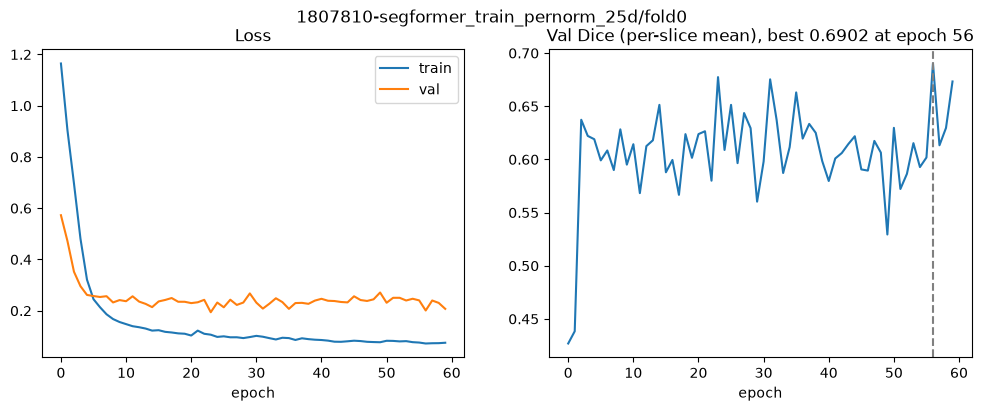

checkpoint_best.pt (epoch 56): val_dice per-slice mean = 0.6902, validated on cases [0, 6]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.833,0.235,3.275,0.099,262894.0,24648.0,80733.0,1415
small_bowel,0.620,0.390,1.095,0.400,369437.0,215824.0,236328.0,1701
large_bowel,0.739,0.139,0.295,0.220,434528.0,236952.0,69982.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.123,0.014,0.863
small_bowel,0.010,0.000,0.032,0.957
large_bowel,0.011,0.419,0.000,0.570


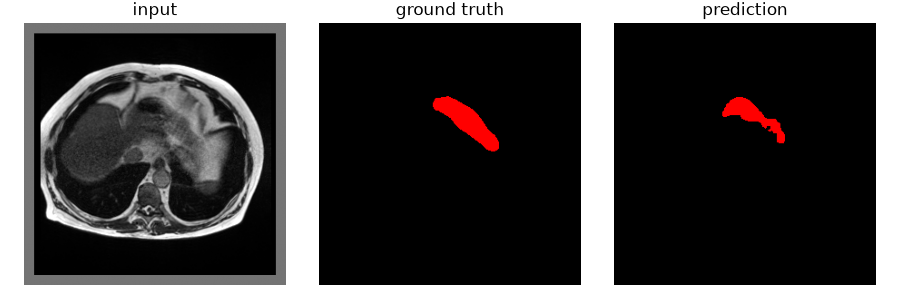

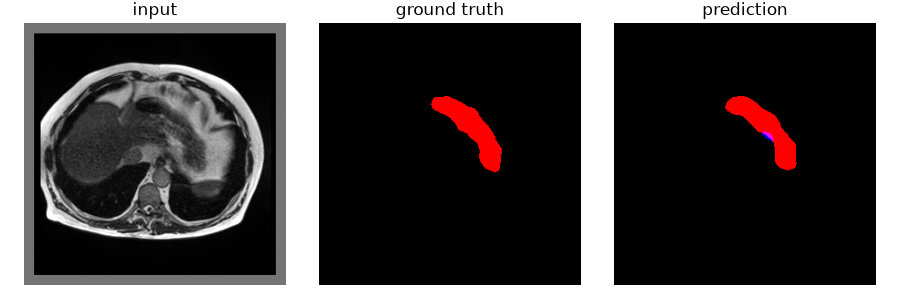

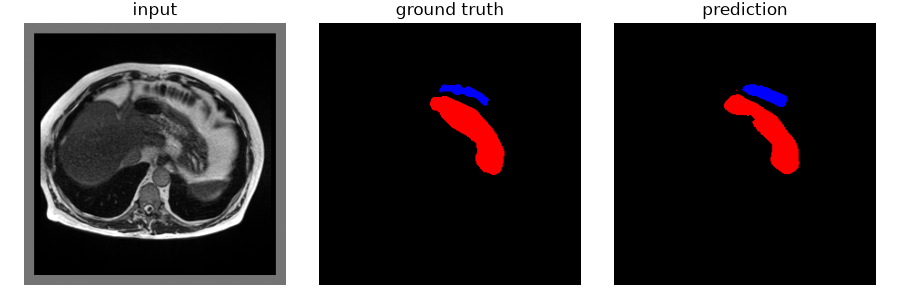

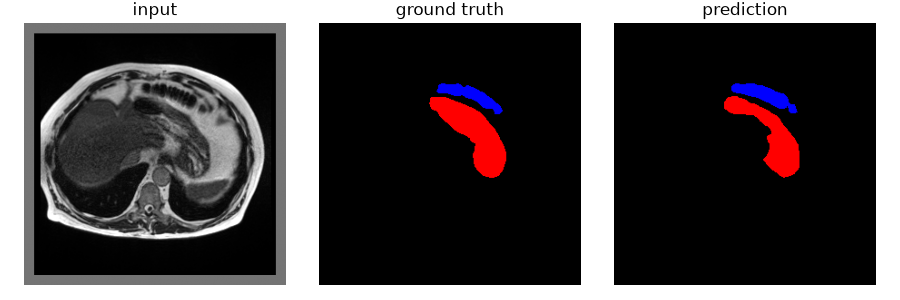

1807810-segformer_train_pernorm_25d/fold1: segformer, fold 1, 60 epochs, batch 32, lr 0.0001


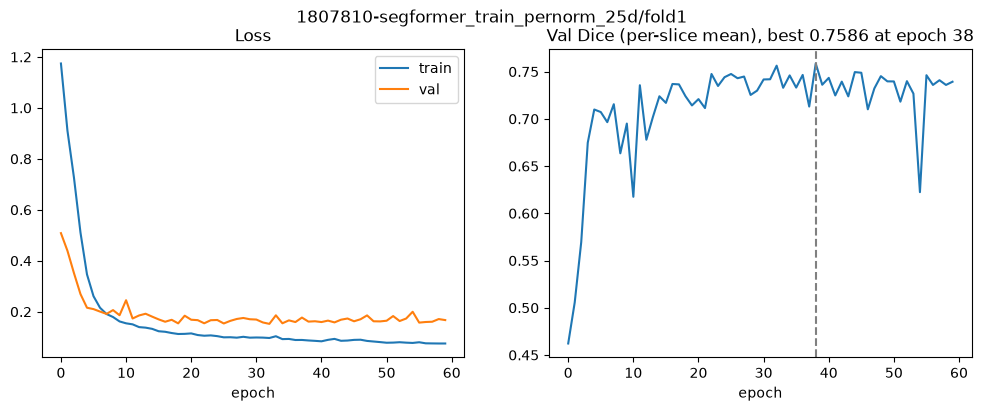

checkpoint_best.pt (epoch 38): val_dice per-slice mean = 0.7586, validated on cases [2, 24, 60]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.856,0.188,2.186,0.143,287084.0,30423.0,66493.0,1415
small_bowel,0.661,0.330,0.920,0.448,412025.0,220408.0,202868.0,1701
large_bowel,0.794,0.236,1.469,0.490,593643.0,124535.0,182910.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.068,0.038,0.894
small_bowel,0.043,0.000,0.236,0.721
large_bowel,0.004,0.238,0.000,0.758


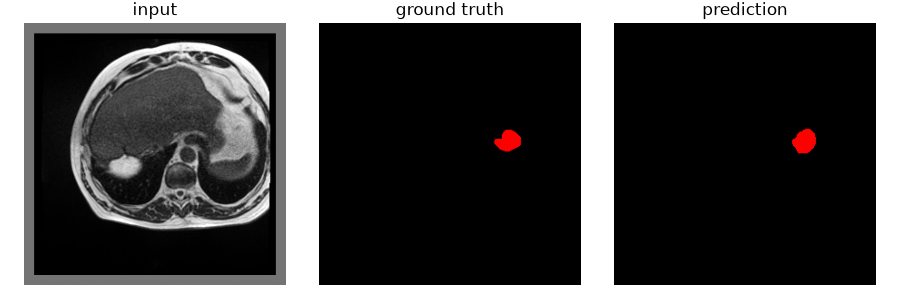

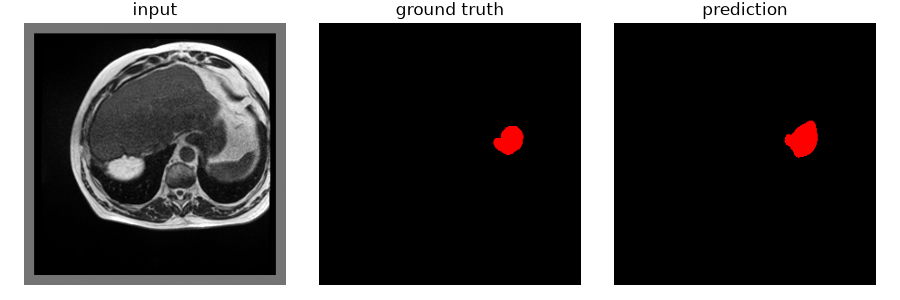

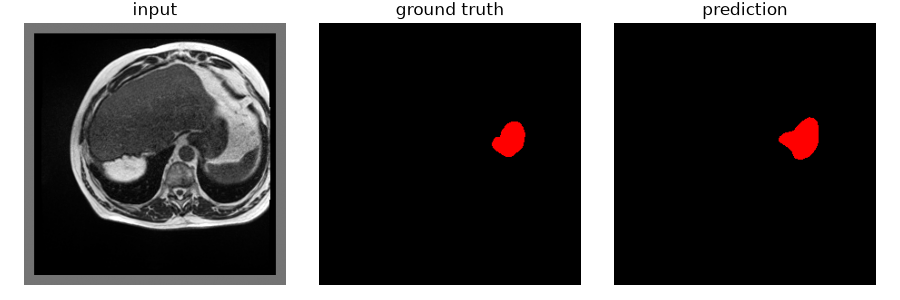

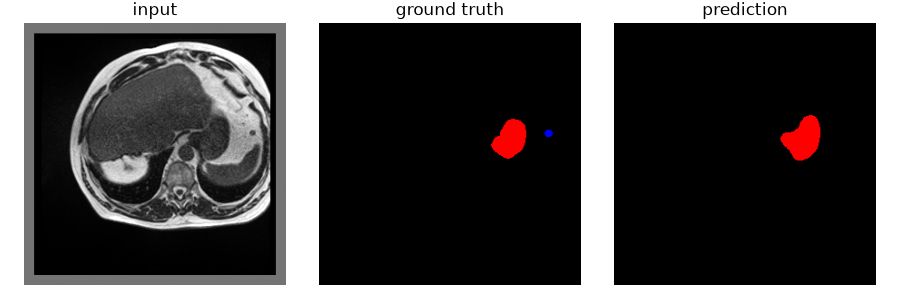

1807810-segformer_train_pernorm_25d/fold2: segformer, fold 2, 60 epochs, batch 32, lr 0.0001


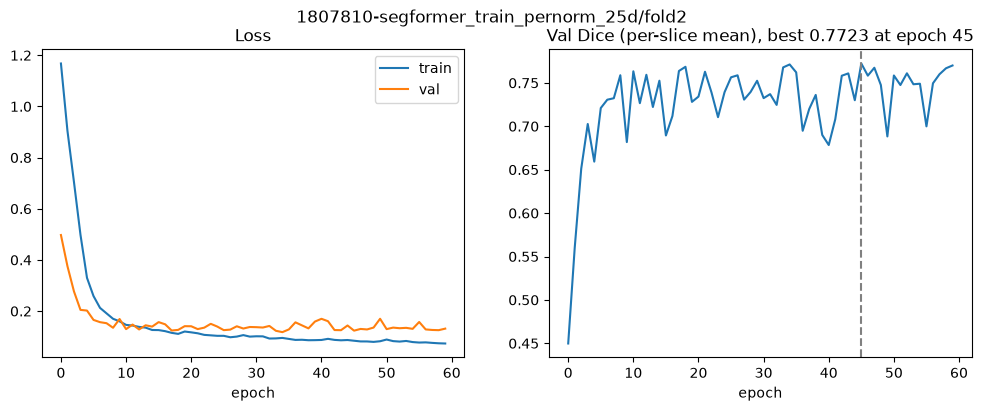

checkpoint_best.pt (epoch 45): val_dice per-slice mean = 0.7723, validated on cases [17, 20, 45]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.899,0.133,2.168,0.077,396358.0,28114.0,60950.0,1415
small_bowel,0.743,0.205,0.597,0.144,498142.0,215329.0,128456.0,1701
large_bowel,0.820,0.188,1.118,0.188,668960.0,138266.0,154556.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.010,0.067,0.923
small_bowel,0.011,0.000,0.314,0.676
large_bowel,0.013,0.218,0.000,0.769


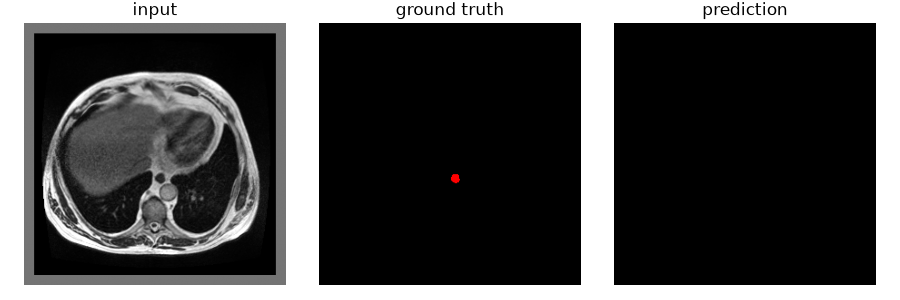

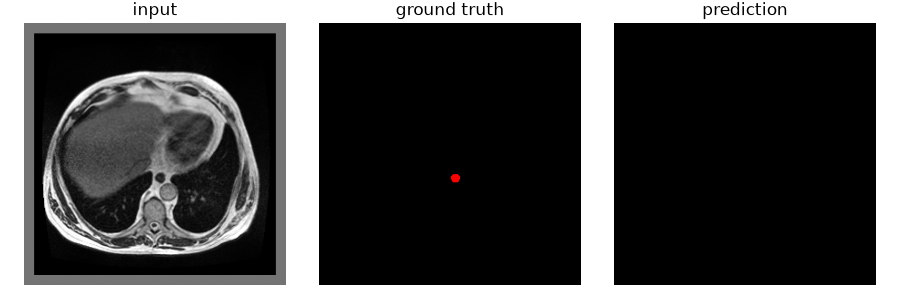

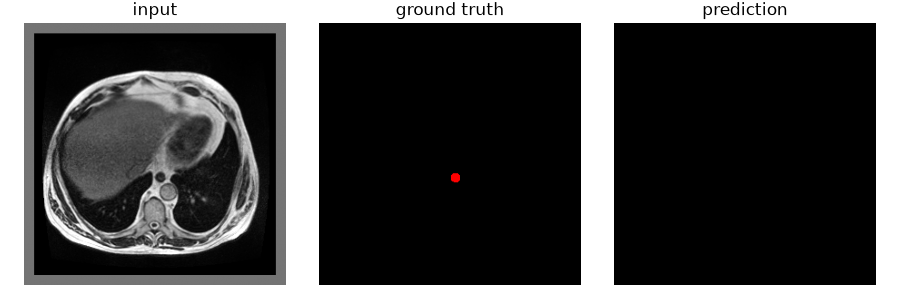

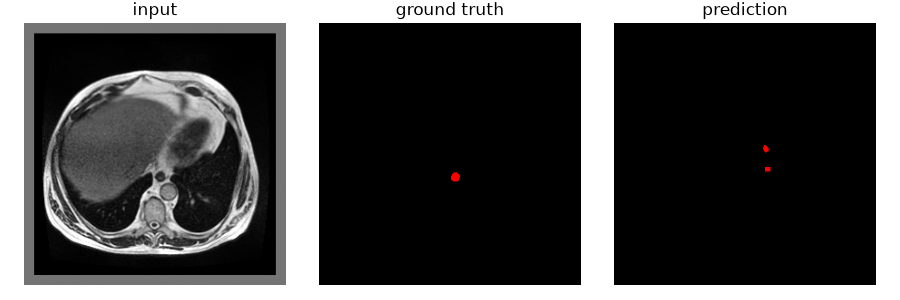

1807810-segformer_train_pernorm_25d/fold3: segformer, fold 3, 60 epochs, batch 32, lr 0.0001


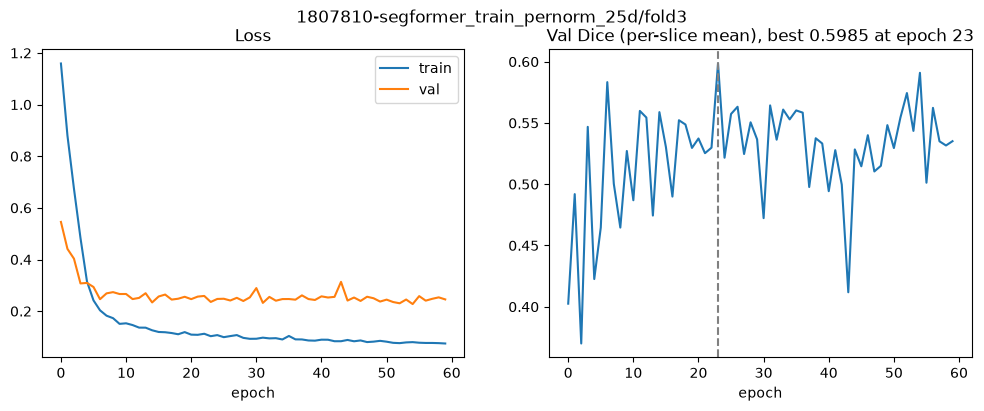

checkpoint_best.pt (epoch 23): val_dice per-slice mean = 0.5986, validated on cases [33, 50, 57]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.719,0.351,2.251,0.037,192974.0,46308.0,104220.0,1415
small_bowel,0.581,0.483,1.847,0.325,319053.0,161368.0,298008.0,1701
large_bowel,0.672,0.348,1.206,0.313,290988.0,129032.0,155612.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.071,0.075,0.854
small_bowel,0.155,0.000,0.220,0.624
large_bowel,0.198,0.332,0.000,0.471


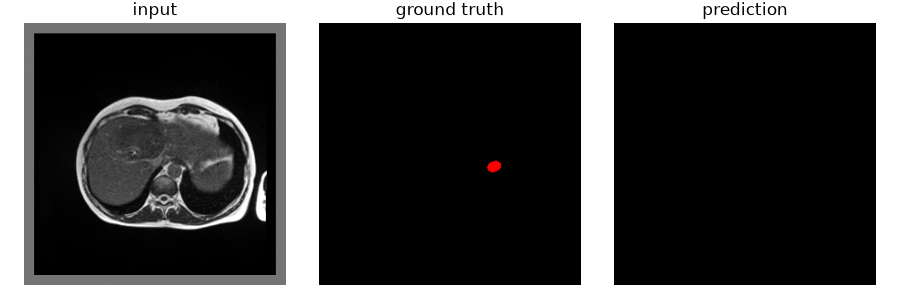

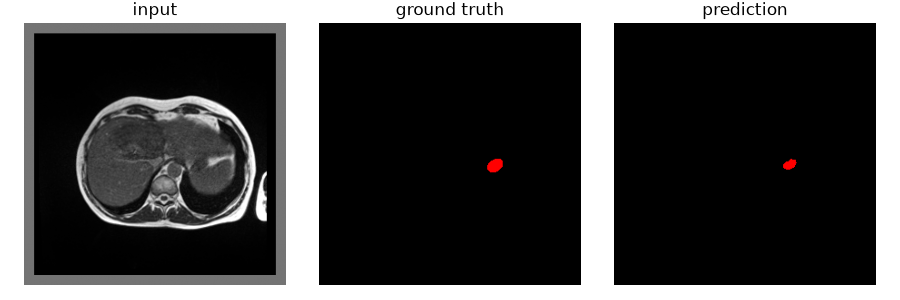

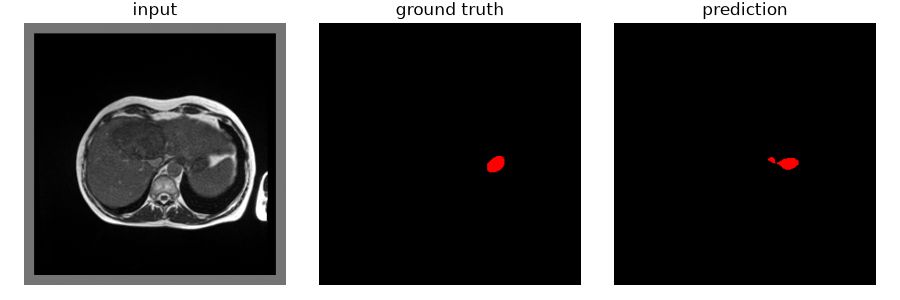

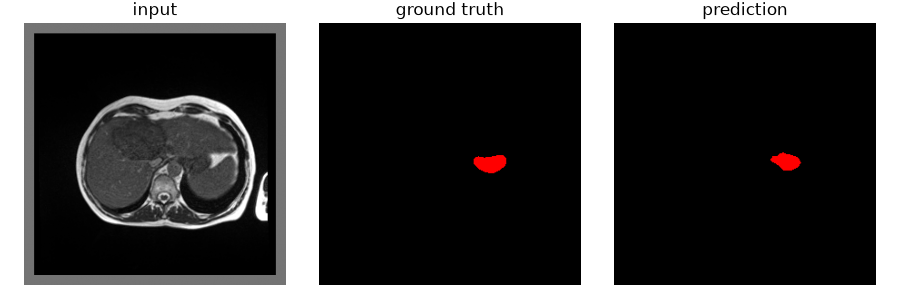

1807810-segformer_train_pernorm_25d/fold4: segformer, fold 4, 60 epochs, batch 32, lr 0.0001


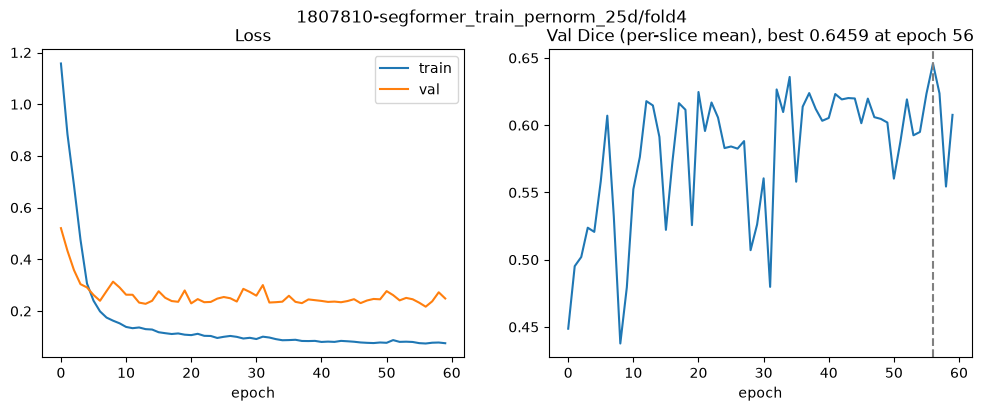

checkpoint_best.pt (epoch 56): val_dice per-slice mean = 0.6459, validated on cases [9, 29, 46]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.737,0.330,2.249,0.090,264790.0,58010.0,130485.0,1415
small_bowel,0.667,0.386,1.705,0.195,472862.0,174516.0,297480.0,1701
large_bowel,0.629,0.440,2.006,0.395,206354.0,81000.0,162453.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.395,0.018,0.587
small_bowel,0.044,0.000,0.348,0.608
large_bowel,0.014,0.410,0.000,0.576


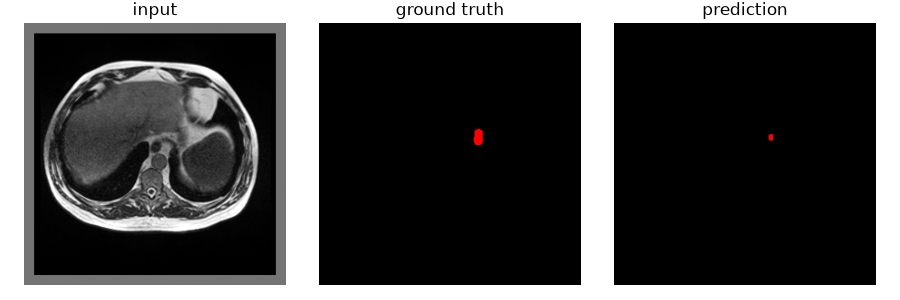

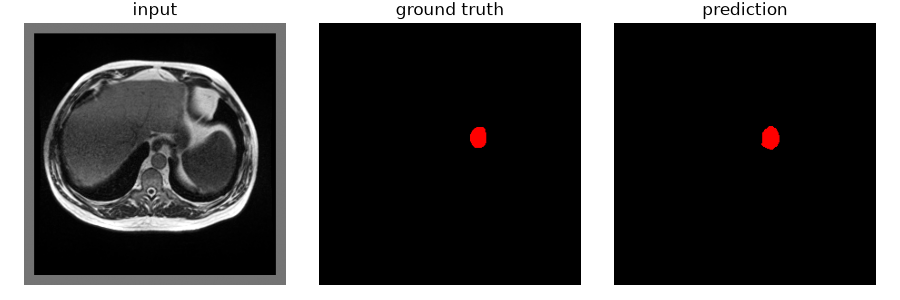

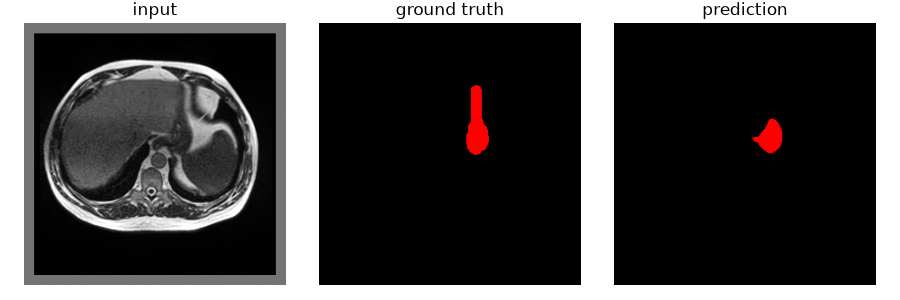

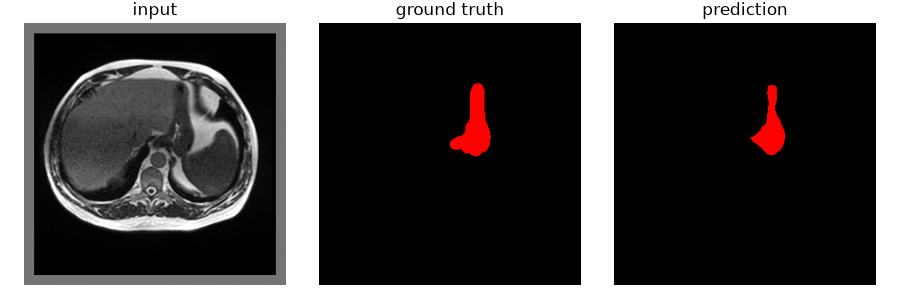

In [152]:
import train_pernorm_25d

CV_JOB = '1807810-segformer_train_pernorm_25d'
CV_ARCHITECTURE = 'segformer'

cv_folders = [f'{CV_JOB}/fold{k}' for k in range(5)]
for folder in cv_folders:
    analyse_run(folder, CV_ARCHITECTURE, data=train_pernorm_25d)

In [153]:
cv = pd.DataFrame([
    {
        'fold': RUN_RESULTS[folder]['fold'], 'val cases': RUN_RESULTS[folder]['val_cases'],
        'val_dice': RUN_RESULTS[folder]['val_dice'],
        **{f'dice {cls}': dice for cls, dice in RUN_RESULTS[folder]['per_class']['dice_pooled'].items()},
    }
    for folder in cv_folders
]).set_index('fold')
display(cv.round(3))
display(cv.drop(columns='val cases').agg(['mean', 'std']).round(3))

,val cases,val_dice,dice stomach,dice small_bowel,dice large_bowel
fold,,,,,
0,"[0, 6]",0.690,0.833,0.620,0.739
1,"[2, 24, 60]",0.759,0.856,0.661,0.794
2,"[17, 20, 45]",0.772,0.899,0.743,0.820
3,"[33, 50, 57]",0.599,0.719,0.581,0.672
4,"[9, 29, 46]",0.646,0.737,0.667,0.629


,val_dice,dice stomach,dice small_bowel,dice large_bowel
mean,0.693,0.809,0.655,0.731
std,0.074,0.077,0.060,0.081


## Results

Mean val Dice is **0.693**, against 0.636 for the same model with the global range. It wins all 5 folds, by +0.024 to +0.100. This is the largest gain of anything i tried.

| fold | val cases | global p1/p99 | per-image p1/p99 | diff |
|---|---|---|---|---|
| 0 | 0, 6 | 0.590 | 0.690 | +0.100 |
| 1 | 2, 24, 60 | 0.719 | 0.759 | +0.040 |
| 2 | 17, 20, 45 | 0.715 | 0.772 | +0.058 |
| 3 | 33, 50, 57 | 0.535 | 0.599 | +0.064 |
| 4 | 9, 29, 46 | 0.622 | 0.646 | +0.024 |
| **mean** | | 0.636 | **0.693** | **+0.057** |

The per-fold pattern is what the intensity plot predicts. Folds 0, 1, 2 and 3 each hold exactly one of the four
dark patients (0, 2, 17, 33) and gain +0.040 to +0.100; fold 4 (cases 9, 29, 46) is the only all-bright fold and
gains the least, +0.024. So the improvement really does come from the dark patients becoming visible rather than from a generally better contrast setting.

Per class everything moves up together: stomach 0.760 -> 0.817, small bowel 0.631 -> 0.658, large bowel 0.701 -> 0.754. Miss rates drop to 0.24 / 0.36 / 0.25.

Two things do not change. Small bowel is still the weakest class, and 33% of large bowel false positives still
land on real small bowel - the same figure as every run before. And fold 3 (cases 33, 50, 57) is still the hardest at 0.599 despite gaining +0.064.

## DINOv3

DINOv3 is a foundation model (ViT) that Meta trained on billions of ordinary photographs. Before building a segmentation model on top of it, the question is simply: does it see our organs?

It cuts the 288x288 input into 16x16 patches, so we get an 18x18 grid, and describes each patch with 384 numbers. Everything below is about what those numbers contain.

In [181]:
import timm

DINO_MODEL = 'vit_small_patch16_dinov3.lvd1689m'
dino = timm.create_model(DINO_MODEL, pretrained=True, img_size=288, num_classes=0).to(device).eval()

PATCH = 16
GRID = 288 // PATCH
N_PREFIX = dino.num_prefix_tokens # cls + storage tokens

print(f"Token length per patch: {dino.embed_dim}")
print(f"Number of patches (tokens): {GRID} x {GRID} = {GRID * GRID}")
print(f"Prefix tokens: {N_PREFIX}")
print(image.shape)
print(tokens.shape)
print(mask.shape)

Token length per patch: 384
Number of patches (tokens): 18 x 18 = 324
Prefix tokens: 5
torch.Size([3, 288, 288])
torch.Size([1, 329, 384])
torch.Size([3, 288, 288])


patch tokens: (324, 384)


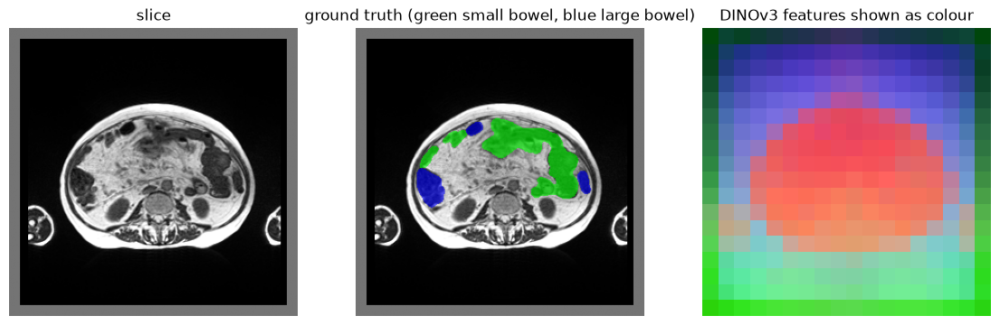

In [182]:
from sklearn.decomposition import PCA

image, mask = plain_dataset[index]

with torch.no_grad():
    tokens = dino.forward_features(image[None].to(device))
patch_tokens = tokens[0, N_PREFIX:].cpu().numpy() # (324, 384): one row of numbers per patch
print("patch tokens:", patch_tokens.shape)

colours = PCA(n_components=3).fit_transform(patch_tokens)
colours = (colours - colours.min()) / (colours.max() - colours.min())

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(image[1], cmap='gray')
axes[0].set_title('slice')
axes[1].imshow(image[1], cmap='gray')
axes[1].imshow(mask.permute(1, 2, 0), alpha=mask.max(0).values * 0.6)
axes[1].set_title('ground truth (green small bowel, blue large bowel)')
axes[2].imshow(colours.reshape(GRID, GRID, 3))
axes[2].set_title('DINOv3 features shown as colour')
for ax in axes:
    ax.axis('off')
plt.show()

Let's take one patch that sits inside an organ and ask which other patches DINOv3 finds similar to it. If the features knew about organs, only that organ should light up.

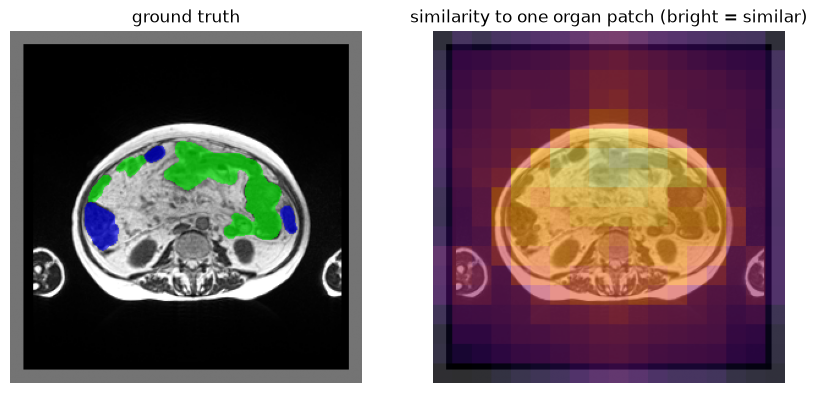

In [183]:
mask_per_patch = torch.nn.functional.interpolate(mask[None], size=(GRID, GRID), mode='area')[0]
organ_patch = int(mask_per_patch.sum(0).flatten().argmax()) # the patch containing the most organ

unit = patch_tokens / np.linalg.norm(patch_tokens, axis=1, keepdims=True)
similarity = (unit @ unit[organ_patch]).reshape(GRID, GRID) # cosine similarity to that patch

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image[1], cmap='gray')
axes[0].imshow(mask.permute(1, 2, 0), alpha=mask.max(0).values * 0.6)
axes[0].set_title('ground truth')
axes[1].imshow(image[1], cmap='gray')
axes[1].imshow(np.kron(similarity, np.ones((PATCH, PATCH))), cmap='inferno', alpha=0.6)
axes[1].set_title('similarity to one organ patch (bright = similar)')
for ax in axes:
    ax.axis('off')
plt.show()

In [184]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score

def collect_patches(ds, n_slices, seed):
    rng = np.random.default_rng(seed)
    seg = ds.seg_df
    organ_slices = [i for i, key in enumerate(zip(seg['case'], seg['day'], seg['slice']))
                    if ds.mask_lookup[key].any()]
    features, pixels, labels = [], [], []
    for i in rng.choice(organ_slices, size=n_slices, replace=False):
        img, msk = ds[int(i)]
        with torch.no_grad():
            tok = dino.forward_features(img[None].to(device))[0, N_PREFIX:].cpu().numpy()
        # label each patch by the organ covering most of it, 0 = background
        cover = torch.nn.functional.interpolate(msk[None], size=(GRID, GRID), mode='area')[0].numpy().reshape(3, -1)
        labels.append(np.where(cover.max(0) > 0.25, cover.argmax(0) + 1, 0))
        current = img[1].numpy()
        pixels.append(current.reshape(GRID, PATCH, GRID, PATCH).transpose(0, 2, 1, 3).reshape(GRID * GRID, PATCH * PATCH))
        features.append(tok)
    return np.concatenate(features), np.concatenate(pixels), np.concatenate(labels)

feat_tr, pix_tr, y_tr = collect_patches(train_dataset, 60, seed=0)
feat_va, pix_va, y_va = collect_patches(val_dataset, 30, seed=1)
print(f"{len(y_tr)} train patches / {len(y_va)} val patches")

for name, x_tr, x_va in [('DINOv3 features (384)', feat_tr, feat_va),
                         ('raw pixels (256)', pix_tr, pix_va),
                         ('mean brightness (1)', pix_tr.mean(1, keepdims=True), pix_va.mean(1, keepdims=True))]:
    mu, sd = x_tr.mean(0), x_tr.std(0) + 1e-6
    clf = LogisticRegression(max_iter=2000, class_weight='balanced').fit((x_tr - mu) / sd, y_tr)
    score = balanced_accuracy_score(y_va, clf.predict((x_va - mu) / sd))
    print(f"  {name:<24} balanced accuracy {score:.3f}   (chance = 0.25)")

19440 train patches / 9720 val patches
  DINOv3 features (384)    balanced accuracy 0.642   (chance = 0.25)
  raw pixels (256)         balanced accuracy 0.348   (chance = 0.25)
  mean brightness (1)      balanced accuracy 0.254   (chance = 0.25)


## Results

In the colour plot the whole abdominal interior comes out as one region and the similarity map lights up the entire cavity rather than one organ, which looks like the features are blind to our organs. But PCA only shows the first 3 of 384 directions, and those are dominated by the largest source of variation - body against background.

To better understand do extracted features really carry any useful information that will help to classify and detect organs, I tried to use Logistic Regression and compare how different inputs affects accuracy. 

| what the classifier sees | balanced accuracy over 4 classes |
|---|---|
| **DINOv3 features (384 numbers)** | **0.64** |
| raw pixels of the same patch (256) | 0.35 |
| mean brightness only (1) | 0.25 = chance |

So the features carry real anatomical information. Nearly double raw pixels, and 2.5x chance. Body-versus-background alone would not give that, because brightness alone scores at chance.

## Attention maps

A ViT builds every output by attending from each token to every other token. The CLS token is the one that summarises the whole image, so the row of attention from CLS to the 324 image patches shows which parts of the slice the model considers worth looking at.

Measurements are averaged over 108 organ-containing slices from 12 patients. The key quantity is `enrichment = share of attention / share of area`, where 1.0 means "no more than you would get by pointing at random".

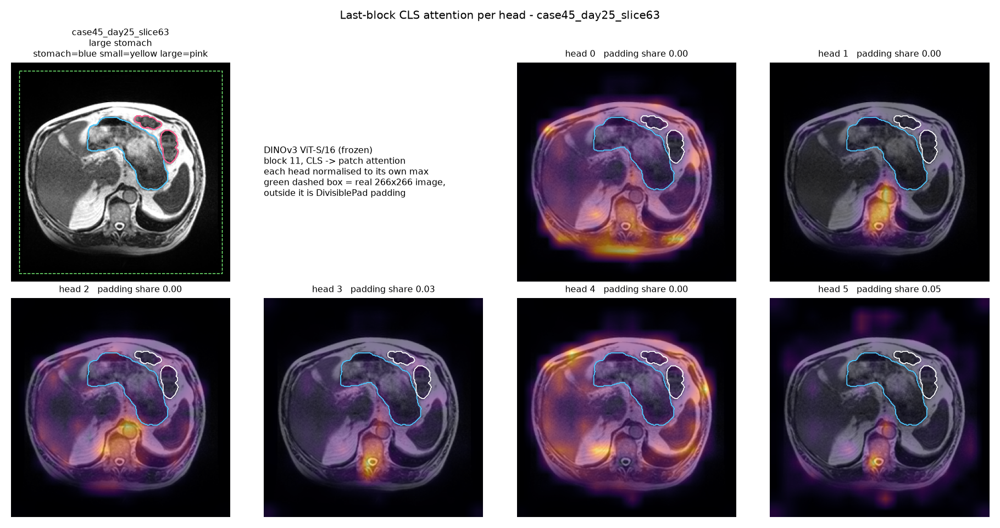

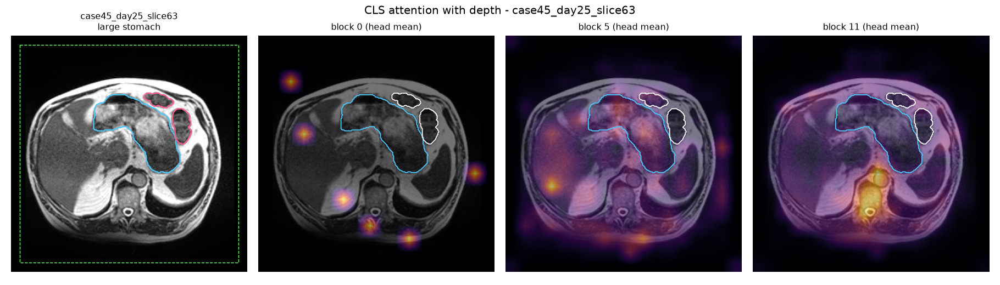

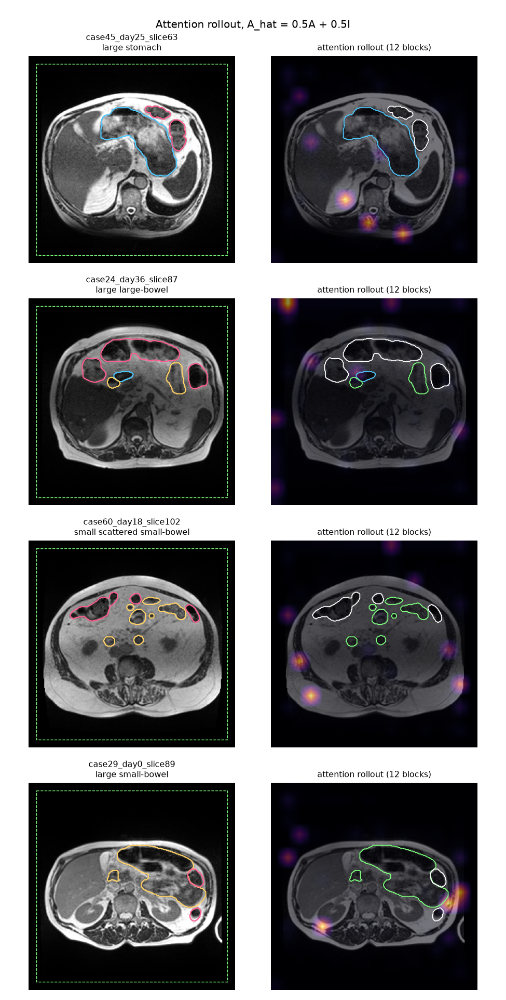

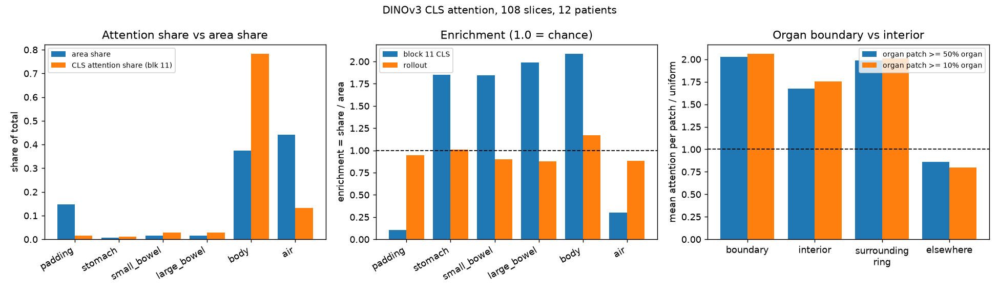

In [185]:
attention_dir = Path('results/dino_attention')

for figure in ['heads_last_block_case45_day25_slice63.png',
               'depth_case45_day25_slice63.png',
               'rollout_all_slices.png',
               'quantitative_regions.png']:
    display(Image(filename=str(attention_dir / figure)))

## Results

As we can see attention does not focus on the organs. It separates the patient from everything else very well, and stops there.

Let me explain the results.

First, Attention share vs area share plot.

- blue = area share. Says what fraction of the 288×288 input that region occupies. Padding 0.147, stomach 0.006, small_bowel 0.016, large_bowel 0.015, body 0.375, air 0.441.
- orange = attention share (block 11)- what fraction of the CLS attention mass landed on that region.7

Regions are mutually exclusive and cover everything: padding (the 11 px DivisiblePad border), the three organs, body (tissue that isn't one of the three organs), air (outside the patient).

So as you can see, body takes 37% of the pixels but takes 78% of the attention. Air is 44% of the pixels but takes 13%. So the model is not attending uniformly - it found the patient. 

As organs are taking very small part of the image and attention, let's take a look at an Enrichment plot. Enrichment is `attention share / area share`. It removes the size effect. If enrichment is 1.0, it means "this region got exactly the attention its size entitles it to". 2.0 means twice its fair share, so for stomach, large and small bowel it should be preferable bigger then for other parts of the body, background etc.

Block 11 numbers: padding 0.11, stomach 1.85, small_bowel 1.84, large_bowel 1.99, body 2.09, air 0.30, all organs 1.90. Seems fine, but not really.

The trap here is the organ bars at ~1.9 look like "DINOv3 prefers the organs". But body is also 2.09, even slightly higher than the organs. The 1.9× is fully explained by organs being inside the body, not by them being organs.

Moreover, the orange rollout bars are all ~0.88–1.17, i.e. flat at chance.

So the organs get no preference over any other tissue around them. What the maps actually light up, clearly visible in the per-head figure, is the spine, the body outline, and the fat-muscle interface under the skin. So it's high-contrast anatomy, which is what a model trained on natural photographs would be expected to lock onto. The stomach and bowel contours sit in dark regions.

I suppose maybe we could pick smaller patches. 16x16 patches over 288x288 give an 18x18 grid. An organ spans only 6-10 patches and an organ-touching patch is about a third organ. Patch-level attention physically cannot resolve organ boundaries.

A linear classifier could read organ identity out of these features at 0.62 balanced accuracy, yet attention gives organs no special weight. The information is present in the representation but is not what the model chooses to attend to. So we probably need more data here or fine-tune a model that was pretrained on similar domain of images.

But it's not fine tuned model and it probably has never seen such type of images, so let's fine tune it.

### DINOv3 as the segmentation encoder

- Input: 2.5D
- Loss: Dice + BCE
- Encoder: DINOv3 ViT-S/16 instead of the ImageNet ResNet-34
- Augmentation
- Intensity: each image scaled by its own p1/p99

The decoder is smp's own `UnetDecoder`, the same decoder code the baselines use. Tokens are taken from blocks 2, 5, 8 and 11, reshaped from 324 tokens back to the 18x18 grid and projected to the 4 deepest decoder levels. The two finest levels come from the image itself, since the ViT has no resolution below stride 16.

The data pipeline is the one of the best SegFormer run (`1807810`), so I tried to make it so only the encoder differs. Two things are added to the model: the ViT's final LayerNorm on the four token maps, and a BatchNorm after each projection. Without them the raw block outputs differ about 80x in scale between block 2 and block 11, and a few channels inside each block are 10-100x larger than the rest. Hope it will help stabilize gradients and training.

1878954-dino_unet_train_dino_pernorm_25d/fold0: dino_unet, fold 0, 60 epochs, batch 32, lr 0.0001


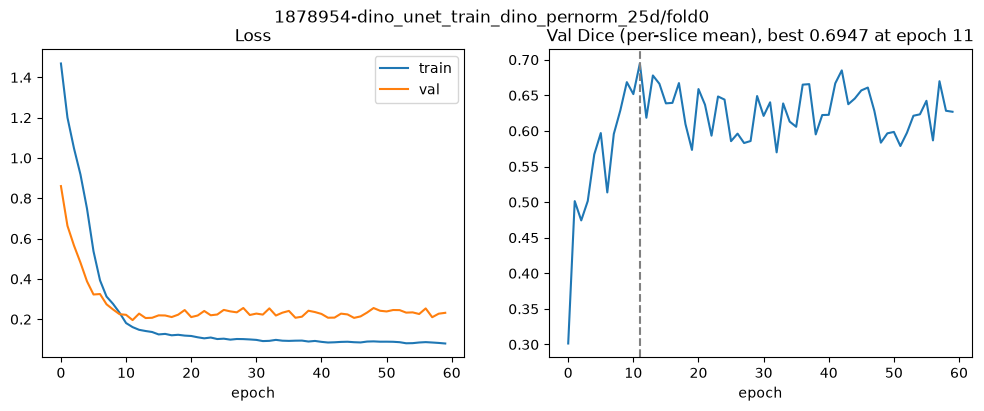

checkpoint_best.pt (epoch 11): val_dice per-slice mean = 0.6947, validated on cases [0, 6]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.843,0.203,2.150,0.149,273872.0,32440.0,69755.0,1415
small_bowel,0.622,0.394,1.148,0.355,367333.0,207780.0,238432.0,1701
large_bowel,0.739,0.120,0.238,0.163,444123.0,253914.0,60387.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.157,0.026,0.817
small_bowel,0.040,0.000,0.032,0.928
large_bowel,0.008,0.447,0.000,0.545


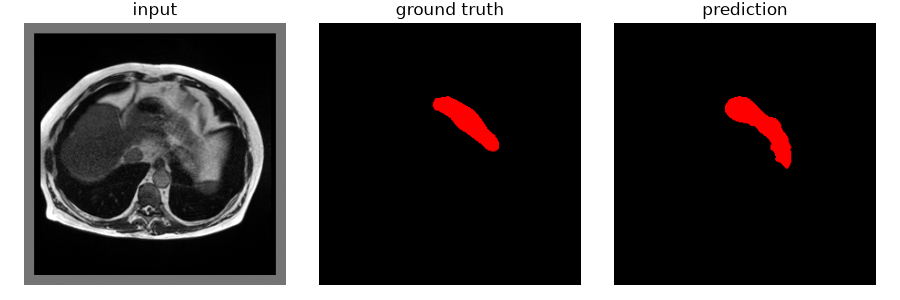

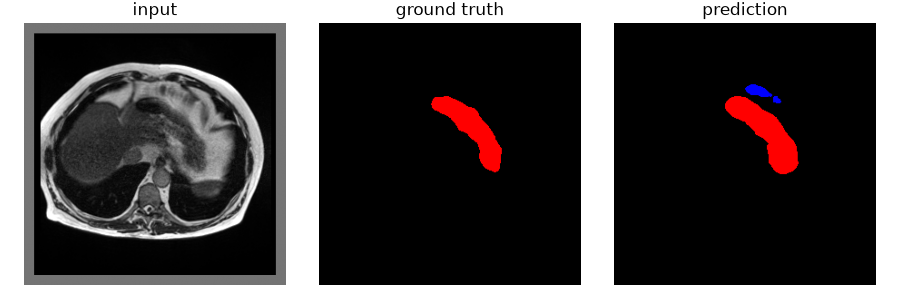

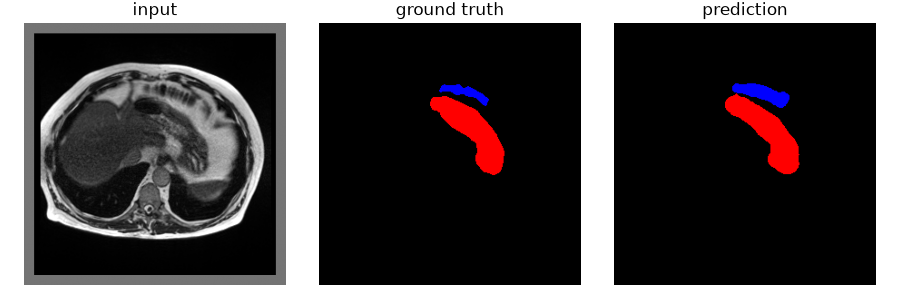

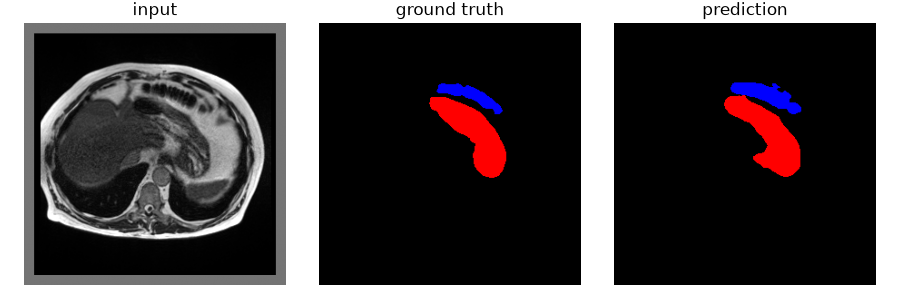

1878954-dino_unet_train_dino_pernorm_25d/fold1: dino_unet, fold 1, 60 epochs, batch 32, lr 0.0001


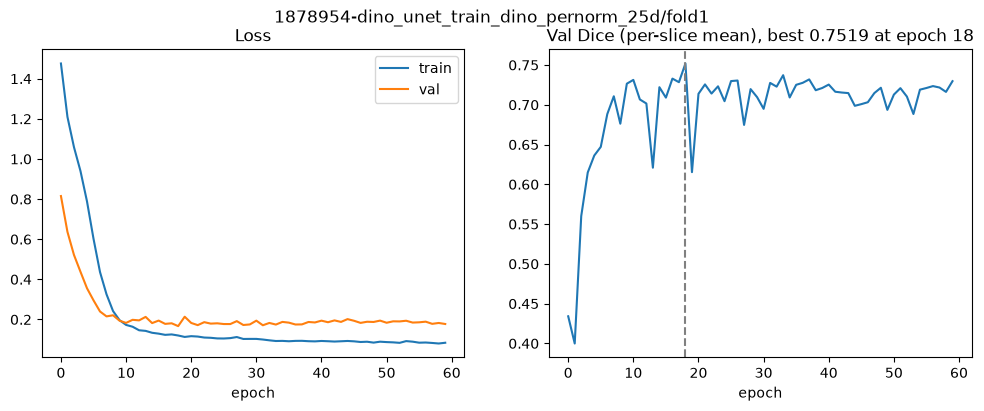

checkpoint_best.pt (epoch 18): val_dice per-slice mean = 0.7519, validated on cases [2, 24, 60]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.864,0.154,1.388,0.093,299060.0,39268.0,54517.0,1415
small_bowel,0.656,0.259,0.502,0.392,455408.0,317566.0,159485.0,1701
large_bowel,0.779,0.253,1.473,0.569,580339.0,133246.0,196214.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.029,0.021,0.950
small_bowel,0.036,0.000,0.262,0.701
large_bowel,0.014,0.097,0.000,0.890


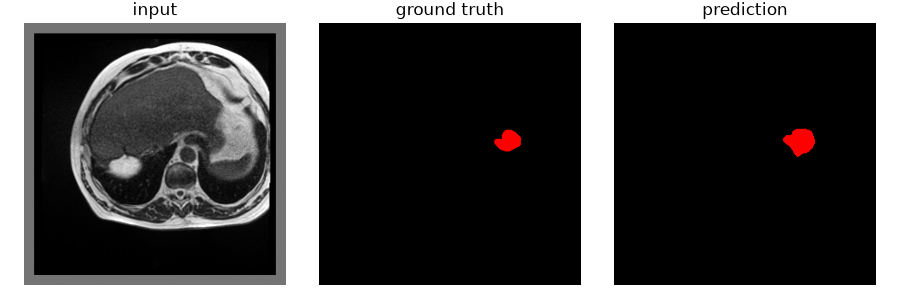

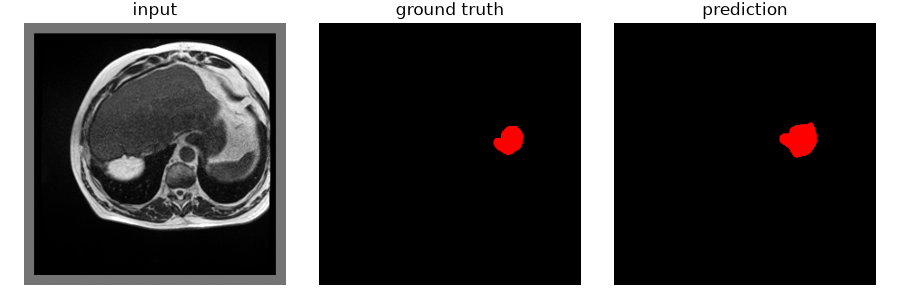

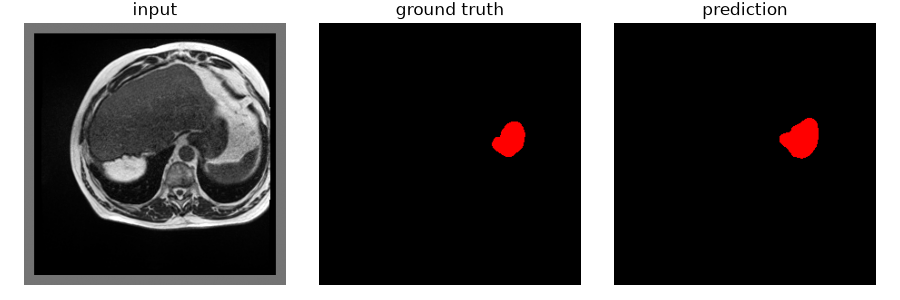

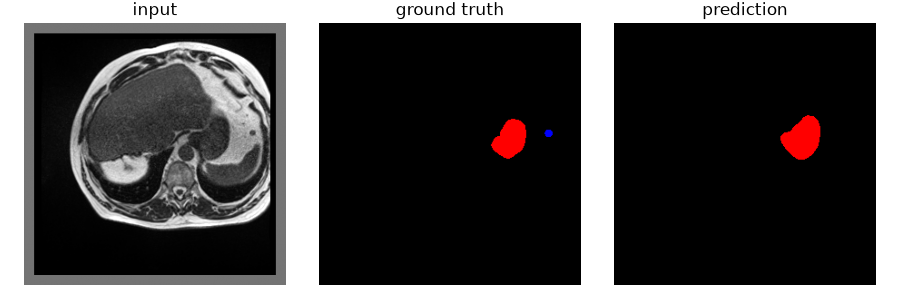

1878954-dino_unet_train_dino_pernorm_25d/fold2: dino_unet, fold 2, 60 epochs, batch 32, lr 0.0001


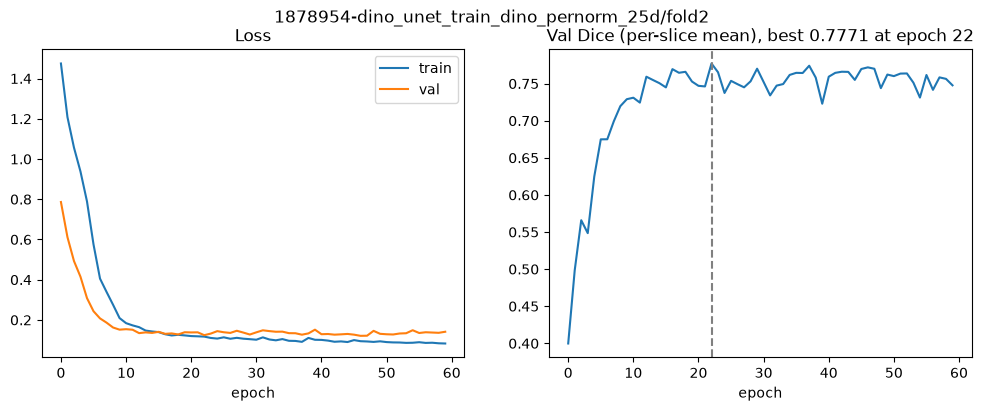

checkpoint_best.pt (epoch 22): val_dice per-slice mean = 0.7771, validated on cases [17, 20, 45]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.906,0.092,0.966,0.116,415111.0,43660.0,42197.0,1415
small_bowel,0.722,0.235,0.663,0.232,479269.0,222229.0,147329.0,1701
large_bowel,0.822,0.132,0.544,0.164,714567.0,200453.0,108949.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.046,0.143,0.811
small_bowel,0.002,0.000,0.193,0.805
large_bowel,0.012,0.307,0.000,0.682


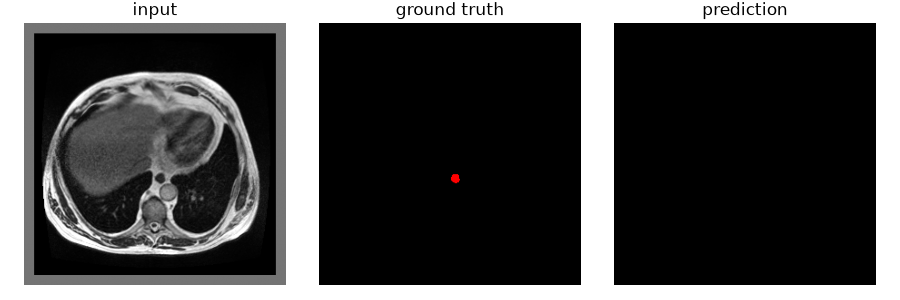

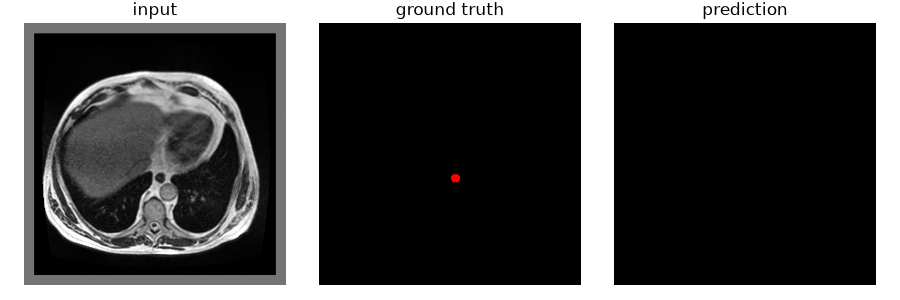

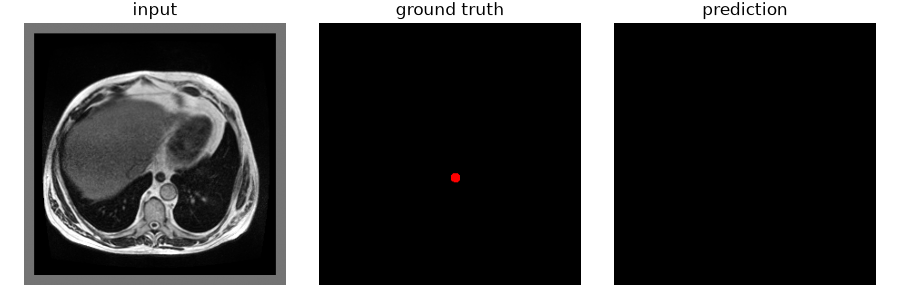

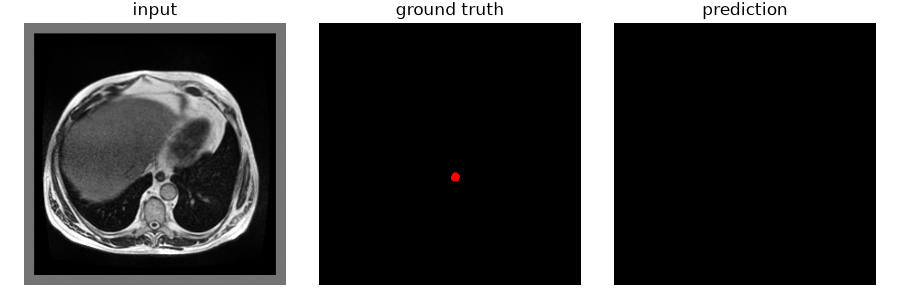

1878954-dino_unet_train_dino_pernorm_25d/fold3: dino_unet, fold 3, 60 epochs, batch 32, lr 0.0001


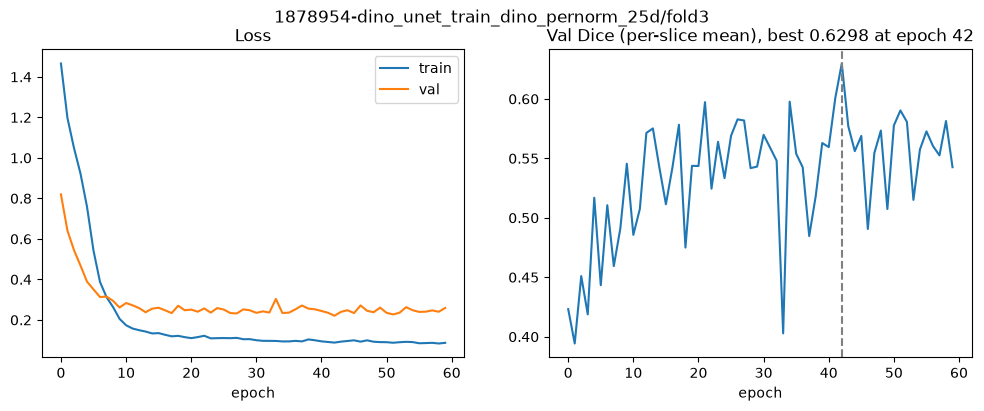

checkpoint_best.pt (epoch 42): val_dice per-slice mean = 0.6298, validated on cases [33, 50, 57]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.765,0.251,1.200,0.105,222680.0,62103.0,74514.0,1415
small_bowel,0.550,0.540,2.551,0.424,283626.0,130733.0,333435.0,1701
large_bowel,0.663,0.309,0.786,0.357,308493.0,175713.0,138107.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.155,0.041,0.804
small_bowel,0.046,0.000,0.312,0.642
large_bowel,0.158,0.348,0.000,0.495


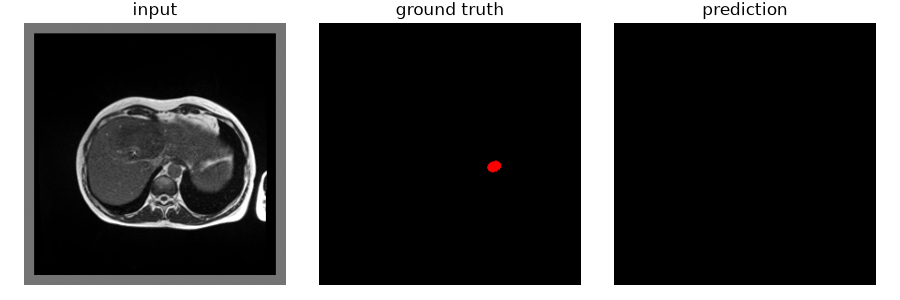

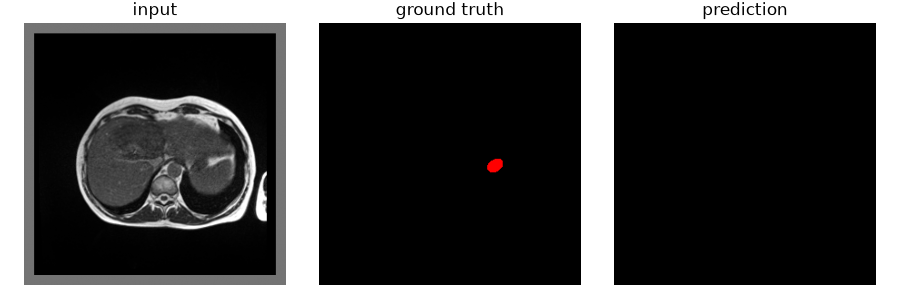

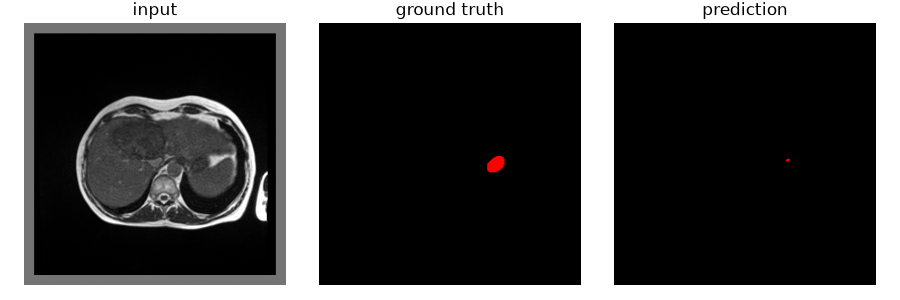

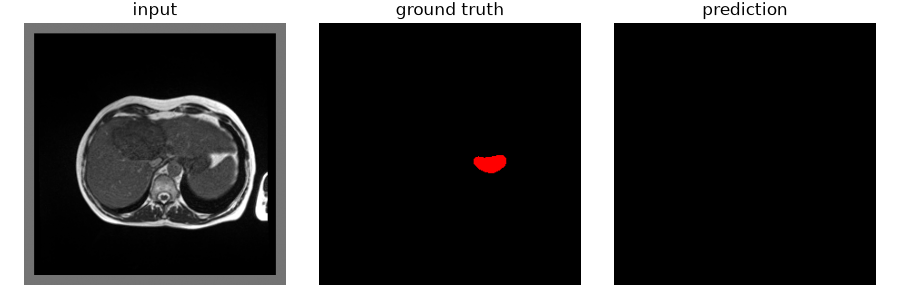

1878954-dino_unet_train_dino_pernorm_25d/fold4: dino_unet, fold 4, 60 epochs, batch 32, lr 0.0001


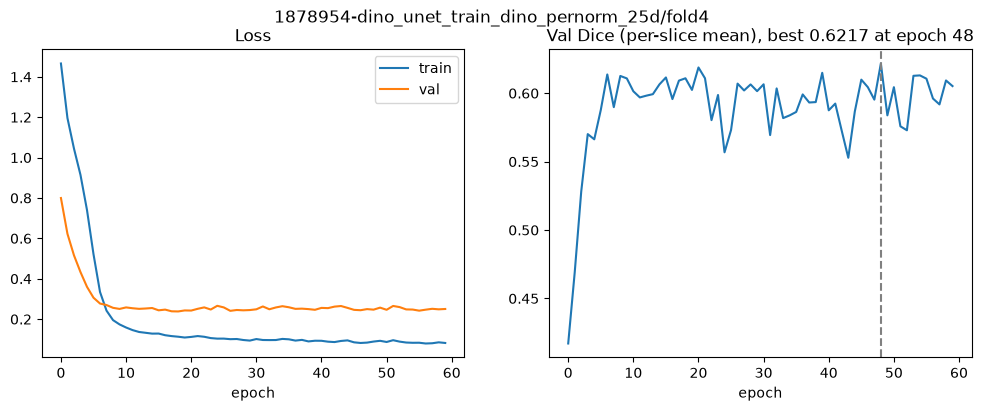

checkpoint_best.pt (epoch 48): val_dice per-slice mean = 0.6217, validated on cases [9, 29, 46]


,dice_pooled,miss_rate,fn_fp_ratio,fp_on_empty_share,tp,fp,fn,annotated_slices
class,,,,,,,,
stomach,0.728,0.320,1.696,0.192,268763.0,74597.0,126512.0,1415
small_bowel,0.546,0.519,1.833,0.300,370809.0,217992.0,399533.0,1701
large_bowel,0.535,0.381,0.548,0.202,228235.0,256301.0,140572.0,2159


,stomach,small_bowel,large_bowel,background
stomach,0.000,0.393,0.081,0.526
small_bowel,0.012,0.000,0.234,0.754
large_bowel,0.021,0.664,0.000,0.316


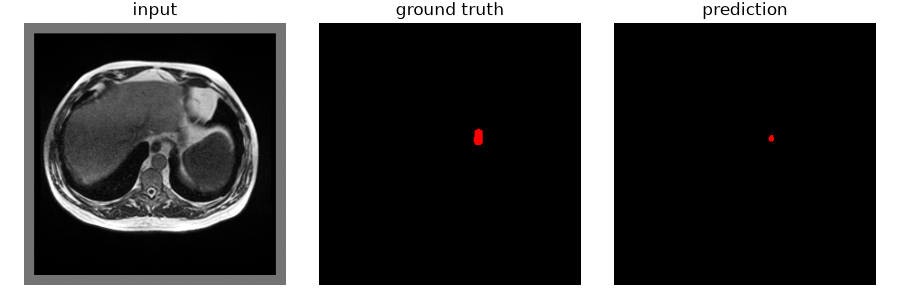

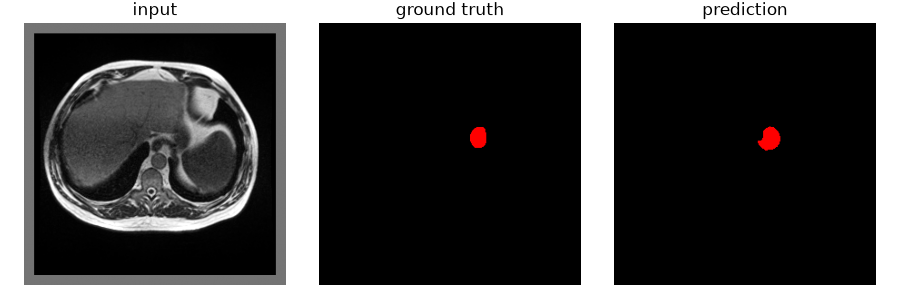

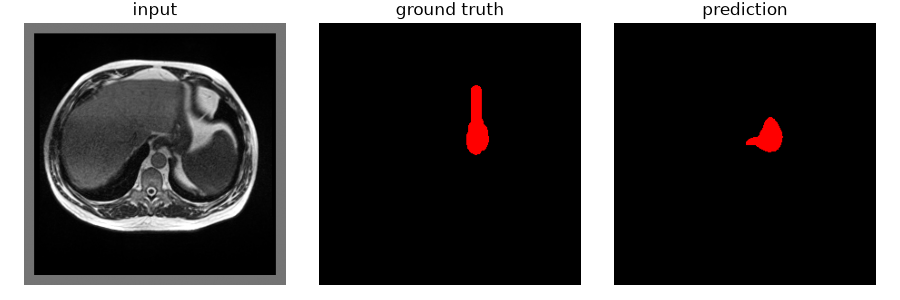

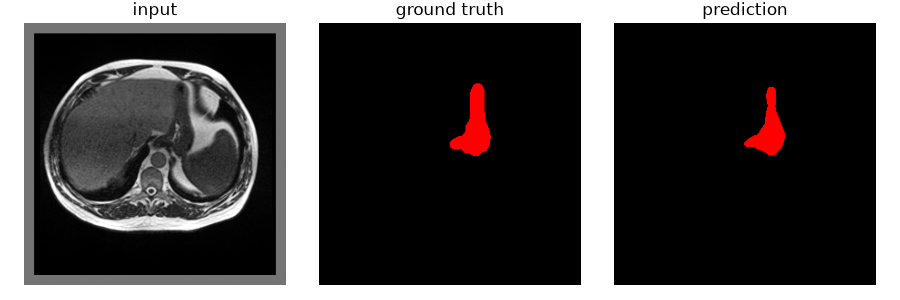

In [186]:
import train_dino_pernorm_25d

CV_JOB = '1878954-dino_unet_train_dino_pernorm_25d'
CV_ARCHITECTURE = 'dino_unet'

cv_folders = [f'{CV_JOB}/fold{k}' for k in range(5)]
for folder in cv_folders:
    dino_model = train_dino_pernorm_25d.DinoUnet('vit_small_patch16_dinov3.lvd1689m',
                                                 classes=3, freeze_encoder=False)
    analyse_run(folder, CV_ARCHITECTURE, data=train_dino_pernorm_25d, model=dino_model)

In [187]:
cv = pd.DataFrame([
    {
        'fold': RUN_RESULTS[folder]['fold'], 'val cases': RUN_RESULTS[folder]['val_cases'],
        'val_dice': RUN_RESULTS[folder]['val_dice'],
        **{f'dice {cls}': dice for cls, dice in RUN_RESULTS[folder]['per_class']['dice_pooled'].items()},
    }
    for folder in cv_folders
]).set_index('fold')
display(cv.round(3))
display(cv.drop(columns='val cases').agg(['mean', 'std']).round(3))

,val cases,val_dice,dice stomach,dice small_bowel,dice large_bowel
fold,,,,,
0,"[0, 6]",0.695,0.843,0.622,0.739
1,"[2, 24, 60]",0.752,0.864,0.656,0.779
2,"[17, 20, 45]",0.777,0.906,0.722,0.822
3,"[33, 50, 57]",0.630,0.765,0.550,0.663
4,"[9, 29, 46]",0.622,0.728,0.546,0.535


,val_dice,dice stomach,dice small_bowel,dice large_bowel
mean,0.695,0.821,0.619,0.707
std,0.070,0.073,0.074,0.113


## Results

Mean val Dice is **0.695**, against 0.693 for SegFormer with the same data pipeline (`1807810`). It wins 3 of 5 folds and the means differ by 0.002, so the two are tied.

| fold | val cases | SegFormer | DINOv3 U-Net | diff |
|---|---|---|---|---|
| 0 | 0, 6 | 0.690 | 0.695 | +0.005 |
| 1 | 2, 24, 60 | 0.759 | 0.752 | -0.007 |
| 2 | 17, 20, 45 | 0.772 | 0.777 | +0.005 |
| 3 | 33, 50, 57 | 0.599 | 0.630 | +0.031 |
| 4 | 9, 29, 46 | 0.646 | 0.622 | -0.024 |
| **mean** | | 0.693 | **0.695** | +0.002 |

The two encoders do not fail in the same places, though:

| mean over folds | stomach | small bowel | large bowel |
|---|---|---|---|
| SegFormer | 0.809 | **0.655** | **0.731** |
| DINOv3 U-Net | **0.821** | 0.619 | 0.707 |

DINOv3 is better on stomach, on 4 of 5 folds, and misses less of it (0.20 against 0.24 pooled over the folds). The fold 3 gain comes from there: stomach 0.765 against 0.719. On both bowels it is worse. It even misses less large bowel (0.22 against 0.25), but predicts far more of it - 1.02M false positive pixels against 0.71M, 41% of them on real small bowel against 33%. So it finds the bowel as well as SegFormer but mixes up which bowel it is more often. Fold 4 is where this costs most: small bowel 0.546 against 0.667, with 66% of large bowel false positives on small bowel.

DINOv3 also peaks earlier - best epochs 11, 18, 22, 42 and 48, against 23 to 56 for SegFormer - and overfits after that. Train_loss ends at 0.083, the same level as the other augmented runs.

### DINOv3 against ResNet-34

The same probe on ResNet-34, the encoder of every baseline, and on DINOv3 after fine-tuning.

In [ ]:
from sklearn.metrics import recall_score

resnet_imagenet = smp.encoders.get_encoder('resnet34', weights='imagenet').to(device).eval()

segformer_2d = smp.create_model('segformer', encoder_name='resnet34', encoder_weights=None, classes=3)
checkpoint = torch.load('results/1786236/fold0/checkpoint_best.pt', map_location=device, weights_only=False)
segformer_2d.load_state_dict(checkpoint['model_state'])
resnet_trained = segformer_2d.encoder.to(device).eval()

dino_unet = train_dino_pernorm_25d.DinoUnet(DINO_MODEL, classes=3, freeze_encoder=False)
checkpoint = torch.load('results/1878954-dino_unet_train_dino_pernorm_25d/fold0/checkpoint_best.pt', map_location=device,
                        weights_only=False)
dino_unet.load_state_dict(checkpoint['model_state'])
dino_finetuned = dino_unet.vit.to(device).eval()

dino_pre, dino_scale, dino_pad = train_dino_pernorm_25d.build_transforms(new_train_df, ENCODER, sample_size=500, seed=42)
dino_train_dataset = train_dino_pernorm_25d.SegDataset(new_train_df, dino_pre, dino_scale, dino_pad)
dino_val_dataset = train_dino_pernorm_25d.SegDataset(val_df, dino_pre, dino_scale, dino_pad)

In [189]:
def collect_features(ds, encoder, n_slices, seed):
    rng = np.random.default_rng(seed)
    seg = ds.seg_df
    organ_slices = [i for i, key in enumerate(zip(seg['case'], seg['day'], seg['slice']))
                    if ds.mask_lookup[key].any()]
    features = []
    for i in rng.choice(organ_slices, size=n_slices, replace=False):
        img, _ = ds[int(i)]
        with torch.no_grad():
            if encoder is dino_finetuned:
                tokens = encoder.forward_features(img[None].to(device))[0, N_PREFIX:]
            else:
                fmap = encoder(img[None].to(device))[4][0]   # layer3: (256, 18, 18), same grid as DINOv3
                tokens = fmap.reshape(fmap.shape[0], -1).T
        features.append(tokens.cpu().numpy())
    return np.concatenate(features)

probes = [('DINOv3, pretrained (384)', feat_tr, feat_va)]
for name, encoder, train_ds, val_ds in [
        ('DINOv3, fine-tuned (384)', dino_finetuned, dino_train_dataset, dino_val_dataset),
        ('ResNet-34, ImageNet (256)', resnet_imagenet, train_dataset, val_dataset),
        ('ResNet-34, trained on MRI (256)', resnet_trained, train_dataset, val_dataset)]:
    probes.append((name, collect_features(train_ds, encoder, 60, seed=0), collect_features(val_ds, encoder, 30, seed=1)))

print(f"{'':<34}{'balanced':>9}{'backgr':>8}{'stomach':>9}{'small':>7}{'large':>7}")
for name, x_tr, x_va in probes:
    mu, sd = x_tr.mean(0), x_tr.std(0) + 1e-6
    clf = LogisticRegression(max_iter=2000, class_weight='balanced').fit((x_tr - mu) / sd, y_tr)
    predicted = clf.predict((x_va - mu) / sd)
    recall = recall_score(y_va, predicted, average=None)
    print(f"{name:<34}{balanced_accuracy_score(y_va, predicted):>9.3f}" + ''.join(f'{r:>8.2f}' for r in recall))

                                   balanced  backgr  stomach  small  large
DINOv3, pretrained (384)              0.642    0.95    0.45    0.60    0.57
DINOv3, fine-tuned (384)              0.779    0.99    0.83    0.48    0.82
ResNet-34, ImageNet (256)             0.603    0.94    0.36    0.57    0.55
ResNet-34, trained on MRI (256)       0.657    0.99    0.57    0.39    0.68


## Results

| features | balanced acc | background | stomach | small bowel | large bowel |
|---|---|---|---|---|---|
| DINOv3, pretrained | 0.642 | 0.95 | 0.45 | **0.60** | 0.57 |
| **DINOv3, fine-tuned** | **0.779** | **0.99** | **0.83** | 0.48 | **0.82** |
| ResNet-34, ImageNet | 0.603 | 0.94 | 0.36 | 0.57 | 0.55 |
| ResNet-34, trained on MRI | 0.657 | **0.99** | 0.57 | 0.39 | 0.68 |

Pretrained DINOv3 beats pretrained ResNet-34, but only by 0.04, and on each organ by 0.02-0.09. As a starting point it is somewhat better, not a different league. The probe is one split with 2 validation patients, so a gap this size is suggestive rather than proven.

Training on our data moves the ResNet ahead of pretrained DINOv3 overall, but unevenly: stomach and large bowel improve a lot, while small bowel drops from 0.57 to 0.39. The trained encoder has learned to favour the two organs that are easier to get right and given up on small bowel - the same class every segmentation run is worst at.

Fine-tuned DINOv3 has the best features of all four, by a wide margin on stomach (0.83) and large bowel (0.82). Small bowel is the exception: 0.48, down from 0.60 before fine-tuning. The segmentation results show the same split: the DINOv3 U-Net is better than SegFormer on stomach and worse on both bowels.

Better features did not give better masks overall, though (0.695 against 0.693). A likely reason hides in the the decoder or connection between encoder and decoder. I am not really sure how to improve written architecture, but i think there are ways to do so.

### What the encoders see

The same PCA colouring as for DINOv3, now for all four encoders on one validation slice (case 6).

case, day, slice: (6.0, 13.0, 87.0)


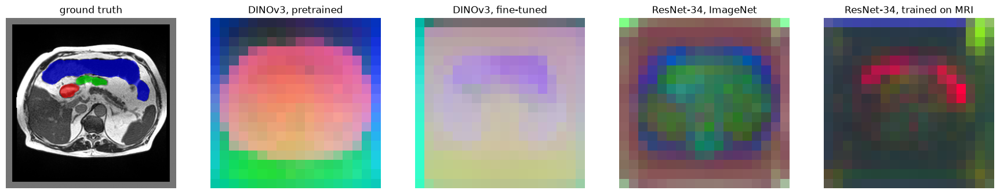

In [ ]:
seg = val_dataset.seg_df
val_index, largest_area = None, 0
for i, key in enumerate(zip(seg['case'], seg['day'], seg['slice'])):
    m = val_dataset.mask_lookup[key]
    if m[..., 1].any() and m[..., 2].any() and m.sum() > largest_area: # both bowels present
        val_index, largest_area = i, m.sum()
val_image, val_mask = val_dataset[val_index]
dino_val_image, _ = dino_val_dataset[val_index]
print('case, day, slice:', tuple(seg.loc[val_index, ['case', 'day', 'slice']]))

with torch.no_grad():
    x = val_image[None].to(device)
    feature_maps = {
        'DINOv3, pretrained': dino.forward_features(x)[0, N_PREFIX:].cpu().numpy(),
        'DINOv3, fine-tuned': dino_finetuned.forward_features(dino_val_image[None].to(device))[0, N_PREFIX:].cpu().numpy(),
        'ResNet-34, ImageNet': resnet_imagenet(x)[4][0].reshape(256, -1).T.cpu().numpy(),
        'ResNet-34, trained on MRI': resnet_trained(x)[4][0].reshape(256, -1).T.cpu().numpy(),
    }

fig, axes = plt.subplots(1, 5, figsize=(22, 5))
axes[0].imshow(val_image[1], cmap='gray')
axes[0].imshow(val_mask.permute(1, 2, 0), alpha=val_mask.max(0).values * 0.6)
axes[0].set_title('ground truth')
for ax, (name, features) in zip(axes[1:], feature_maps.items()):
    colours = PCA(n_components=3).fit_transform(features)
    colours = (colours - colours.min()) / (colours.max() - colours.min())
    ax.imshow(colours.reshape(GRID, GRID, 3))
    ax.set_title(name)
for ax in axes:
    ax.axis('off')
plt.show()

Attention from one organ patch in the last block of DINOv3, before and after fine-tuning: which patches does it collect information from? The heatmap is the white patch's attention row; the outlines are stomach (red), small bowel (green) and large bowel (cyan). Below it, the same measured over every organ patch of the 30 probe slices.

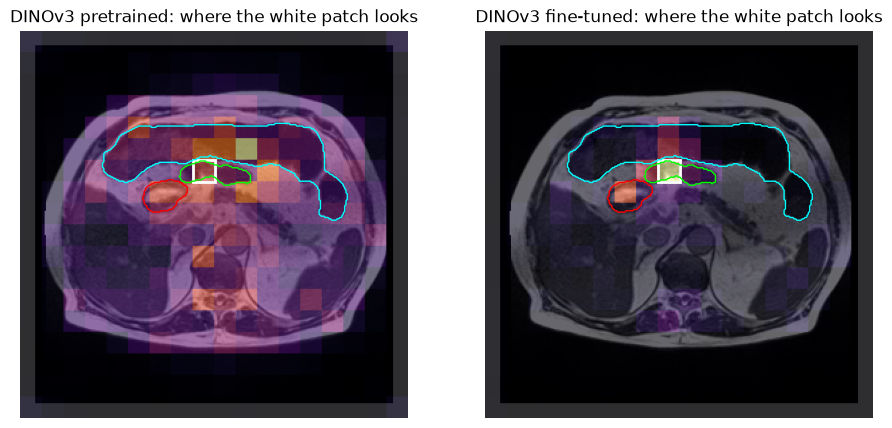

             within 5x5   stomach  small_bowel  large_bowel
pretrained         0.24      1.29         1.27         1.65
fine-tuned         0.31      7.70         2.35         4.19


In [ ]:
def last_block_attention(vit, image):
    """Patch-to-patch attention of the last block, averaged over the 6 heads: (324, 324), rows sum to 1."""
    stored = []
    attn = vit.blocks[-1].attn
    attn.fused_attn = False
    hook = attn.attn_drop.register_forward_hook(lambda module, inputs, output: stored.append(output))
    with torch.no_grad():
        vit.forward_features(image[None].to(device))
    hook.remove()
    attn.fused_attn = True
    patches = stored[0][0].mean(0)[N_PREFIX:, N_PREFIX:].cpu().numpy() # drop CLS and storage tokens
    return patches / patches.sum(1, keepdims=True)

cover = torch.nn.functional.interpolate(val_mask[None], size=(GRID, GRID), mode='area')[0]
query = int(cover[1].flatten().argmax()) # the patch holding the most small bowel

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, (name, vit, img) in zip(axes, [('pretrained', dino, val_image), ('fine-tuned', dino_finetuned, dino_val_image)]):
    attention = last_block_attention(vit, img)[query].reshape(GRID, GRID)
    ax.imshow(val_image[1], cmap='gray')
    ax.imshow(np.kron(attention, np.ones((PATCH, PATCH))), cmap='inferno', alpha=0.6)
    for c, colour in enumerate(['red', 'lime', 'cyan']):
        ax.contour(val_mask[c], levels=[0.5], colors=colour, linewidths=1)
    ax.add_patch(plt.Rectangle(((query % GRID) * PATCH, (query // GRID) * PATCH), PATCH, PATCH,
                               fill=False, edgecolor='white', linewidth=2))
    ax.set_title(f'DINOv3 {name}: where the white patch looks')
    ax.axis('off')
plt.show()

# over the 30 validation slices of the probe. Fine-tuning also makes attention more local, and an organ's
# patches are neighbours, so compare only within the 5x5 neighbourhood of each organ patch:
# attention per same-organ neighbour / attention per other neighbour (1.0 = the organ gets no preference)
rows, cols = np.divmod(np.arange(GRID * GRID), GRID)
rng = np.random.default_rng(1)
seg = val_dataset.seg_df
organ_slices = [i for i, key in enumerate(zip(seg['case'], seg['day'], seg['slice']))
                if val_dataset.mask_lookup[key].any()]
local_share = {'pretrained': [], 'fine-tuned': []}
organ_ratio = {'pretrained': [[], [], []], 'fine-tuned': [[], [], []]}
for i in rng.choice(organ_slices, size=30, replace=False):
    img_2d, msk = val_dataset[int(i)]
    img_25d, _ = dino_val_dataset[int(i)]
    cover = torch.nn.functional.interpolate(msk[None], size=(GRID, GRID), mode='area')[0].numpy().reshape(3, -1)
    labels = np.where(cover.max(0) > 0.25, cover.argmax(0) + 1, 0)
    for name, vit, img in [('pretrained', dino, img_2d), ('fine-tuned', dino_finetuned, img_25d)]:
        attention = last_block_attention(vit, img)
        for q in np.flatnonzero(labels > 0):
            near = (np.abs(rows - rows[q]) <= 2) & (np.abs(cols - cols[q]) <= 2)
            near[q] = False
            local_share[name].append(attention[q, near].sum())
            same, other = near & (labels == labels[q]), near & (labels != labels[q])
            if same.any() and other.any():
                organ_ratio[name][labels[q] - 1].append(attention[q, same].mean() / attention[q, other].mean())

print(f"{'':<12}{'within 5x5':>11}{'stomach':>10}{'small_bowel':>13}{'large_bowel':>13}")
for name in local_share:
    print(f'{name:<12}{np.mean(local_share[name]):>11.2f}' +
          ''.join(f'{np.median(v):>{w}.2f}' for v, w in zip(organ_ratio[name], [10, 13, 13])))

## Results

The two pretrained encoders mainly split body from background. ImageNet ResNet also lights up the padded corners. Measured per patch, both do tint the organs slightly differently from the surrounding tissue, but all three organs get the same colour, so they are telling "middle of the abdomen" apart, not stomach from bowel. The trained ResNet separates one organ: the large bowel arc comes out red (0.56 on the red axis against 0.23 for other tissue), while stomach and small bowel sit in between (0.32, 0.38).

Fine-tuned DINOv3 turns the organ band along the top of the abdomen into one violet arc, but sets it apart from the other tissue only a little (0.75-0.85 against 0.70 on the blue axis). On that axis the organs line up as stomach, small bowel, large bowel, with the two bowels closest (0.82, 0.85). On this slice the colours also rest on only 3 stomach and 4 small bowel patches.

Before fine-tuning, the small bowel patch looks at the whole body, spine included. After, it looks at its own neighbourhood and at the stomach next to it. Measured over the 30 slices:

| | share within 5x5 | stomach | small bowel | large bowel |
|---|---|---|---|---|
| pretrained | 0.24 | 1.29 | 1.27 | 1.65 |
| fine-tuned | 0.31 | 7.70 | 2.35 | 4.19 |

The first column is how much attention stays in the 5x5 neighbourhood. It rises, so fine-tuning makes attention more local. The organ columns compare, inside that neighbourhood only, attention per same-organ patch against attention per other patch, so locality cannot explain them. Pretrained DINOv3 barely prefers the organ (1.3x). However, fine-tuned DINOv3 gives a stomach patch 7.7x more attention than the tissue around it, and a large bowel patch 4.2x. Fine-tuning taught it to look at the organ, not just near it. Small bowel is again last (2.35x).

## Comparison

| run | input | augmentation | intensity | mean val Dice |
|---|---|---|---|---|
| U-Net++ (`1786020`) | 2D | no | global | 0.571 |
| SegFormer (`1786236`) | 2D | no | global | 0.585 |
| U-Net++ (`1787653`) | 2.5D | no | global | 0.592 |
| SegFormer (`1794273`) | 2.5D | yes | global | 0.599 |
| SegFormer (`1786512`) | 2.5D | no | global | 0.614 |
| SegFormer (`1794532`) | 2.5D | yes | global | 0.636 |
| **SegFormer (`1807810`)** | **2.5D** | **yes** | **per image** | **0.693** |
| **DINOv3 U-Net (`1878954`)** | **2.5D** | **yes** | **per image** | **0.695** |

Four changes were tested, each on all 5 folds:

- **2D to 2.5D**: +0.029 for SegFormer, +0.021 for U-Net++, winning all 5 folds both times.
- **Augmentation**: +0.022, 4 of 5 folds, but only once the budget went from 30 to 60 epochs.
- **Per-image intensity scaling**: **+0.057, 5 of 5 folds** - but it's not really a new feature but just fix of the bag that that i made.
- **DINOv3 as the encoder**: +0.002 against SegFormer with the same data pipeline, 3 of 5 fold. It is better on stomach and worse on both bowels.

SegFormer beats U-Net++ on average with both inputs, yet wins only 3 of 5 folds each time.

Two problems survive every configuration:

- Small bowel is always the weakest class (0.556 to 0.655) and about a third of large bowel false positives land on real small bowel in every single run, 41% for DINOv3.
- Fold 3 (cases 33, 50, 57) is the hardest fold in every run but DINOv3, where fold 4 is just below it (0.622 against 0.630).

And still couldn't fix overfitting. train_loss ends between 0.04 and 0.10 while val_loss stops improving, in all eight runs.

In [ ]:
summary = pd.DataFrame([
    {
        'run': r['label'], 'architecture': r['architecture'],
        'best epoch': r['best_epoch'], 'val_dice': r['val_dice'],
        **{f'dice {cls}': dice for cls, dice in r['per_class']['dice_pooled'].items()},
    }
    for r in RUN_RESULTS.values()
]).set_index('run')
display(summary.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
for r in RUN_RESULTS.values():
    ax.plot(r['metrics']['epoch'], r['metrics']['val_dice'], label=r['label'])
ax.set_xlabel('epoch')
ax.set_ylabel('val Dice (per-slice mean)')
ax.legend()
plt.show()